In [8]:

from __future__ import print_function, division
from collections import defaultdict, OrderedDict
import gzip
import pickle
import json
import os
import uproot
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
from coffea import hist, processor 
from coffea.hist import plot
from coffea.util import load, save

In [9]:
hists = load('../../../hists/UL_lep_monotop_v1_test_2017.scaled')
data={
    '2017':{
        'sre': 'SingleElectron',
        'srm': 'SingleMuon',
        'wjetm': 'SingleMuon',
        'ttbarm': 'SingleMuon',
        'wjete': 'SingleElectron',
        'ttbare': 'SingleElectron',
#         'zmcr': 'MET',
#         'zecr': 'EGamma',
#         'gcr': 'EGamma'
    }
}

data_hists   = hists['data']
bkg_hists    = hists['bkg']
signal_hists = hists['sig']

In [ ]:
signal_hists

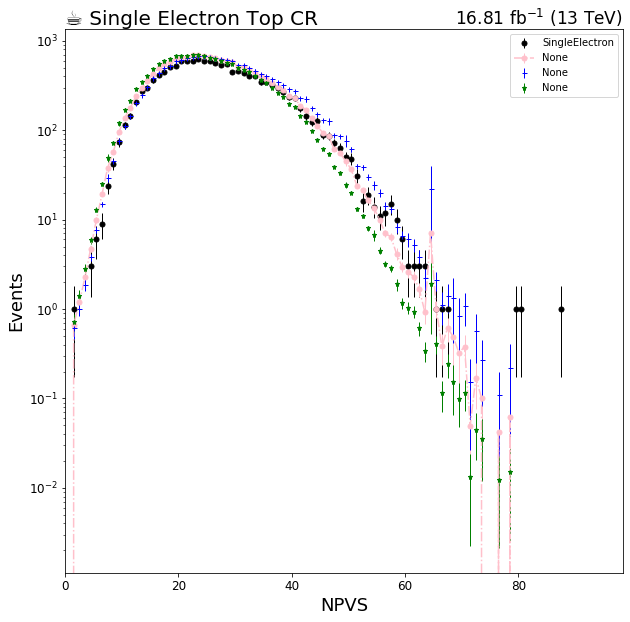

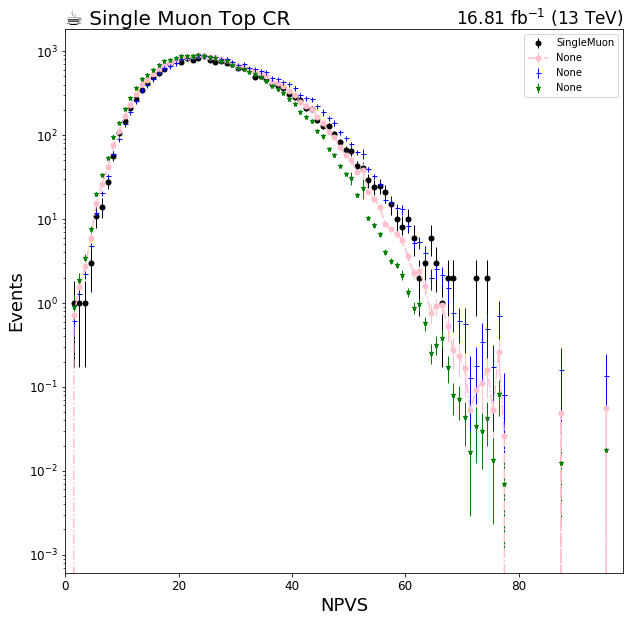

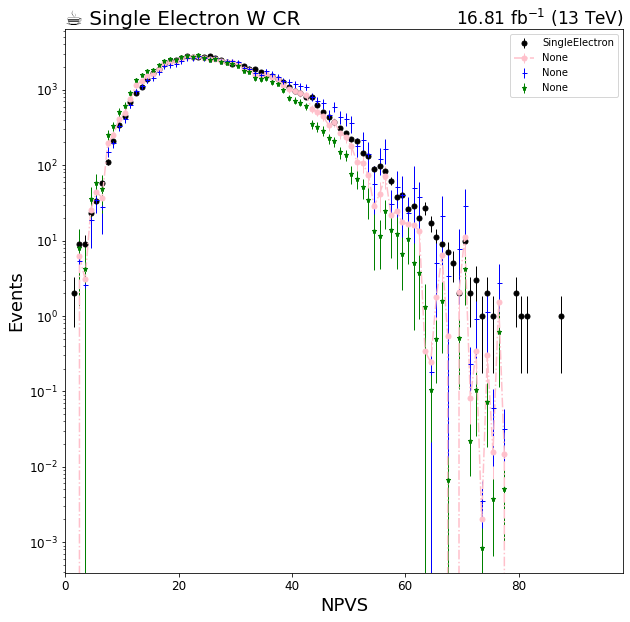

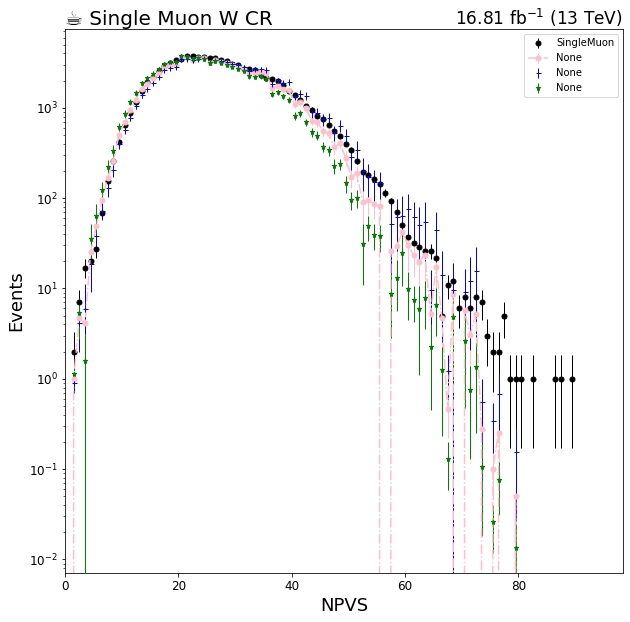

In [10]:


from coffea.hist import plot
import matplotlib.pyplot as plt

R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
for _region in bkg_hists['template'].identifiers('region'):
    if not (str(_region) not  in ['sre', 'srm']): continue
    fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 0.2,}
#     legend_opts = {'Process':"hi"}
    error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
    # nostack_fill_opts = {'alpha': 0.2, 'label': 'hi'}
    data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k',  }#, 'elinewidth': 1, 'emarker': '_'}
    bkg_err_opts_up = {'linestyle':'None', 'marker': '+', 'markersize': 5., 'color':'blue', }#, 'elinewidth': 1, 'emarker': '_'}
    bkg_err_opts_down = {'linestyle':'None', 'marker': '*', 'markersize': 5., 'color':'g', }#, 'elinewidth': 1, 'emarker': '_'}
    bkg_err_opts = {'linestyle':'-.', 'marker': 'o', 'markersize': 5., 'color':'pink', }#, 'elinewidth': 1, 'emarker': '_'}

    fig, ax = plt.subplots(1,1, figsize=(10,10))
    #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
    colors = ['#a6cee3', '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                      '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                      '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']

    plot.plot1d(data_hists['template'].integrate('region',_region).integrate('systematic', 'nominal').integrate('mT_corrected')[data['2017'][str(_region)]],            
    #         overlay="process",
            ax=ax,
            clear=False,
            error_opts=data_err_opts,
#                 legend_opts=legend_opts
               )

    plot.plot1d(bkg_hists['template'].integrate('region',_region).integrate('systematic', 'nominal').integrate('mT_corrected').sum('process'),
#                 overlay="process",
                ax=ax,
                clear=False,
    #             stack=True,
    #             fill_opts=fill_opts,
                error_opts=bkg_err_opts,
#                 legend_opts=legend_opts
                   )
    plot.plot1d(bkg_hists['template'].integrate('region',_region).integrate('systematic', 'puUp').integrate('mT_corrected').sum('process'),
    #             overlay="process",
                ax=ax,
                clear=False,
    #             stack=True,
    #             fill_opts=fill_opts,
                error_opts=bkg_err_opts_up
                   )

    plot.plot1d(bkg_hists['template'].integrate('region',_region).integrate('systematic', 'puDown').integrate('mT_corrected').sum('process'),
    #             overlay="process",
                ax=ax,
                clear=False,
    #             stack=True,
    #             fill_opts=fill_opts,
                error_opts=bkg_err_opts_down,
                   )
    ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
    args = {'linestyle':'--', 'linewidth': 5}
    ax.autoscale(axis='x', tight=True)
    ax.set_yscale('log')
    # if(key=='dilepmass'): ax.set_xlim(50, 130)
    ax.set_ylim(.1, None)
    ax.autoscale()
    leg = ax.legend(ncol=1, loc='best')
    coffee = plt.text(0., 1., u"☕ "+R[str(_region).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
    lumi = plt.text(1., 1., r"16.81 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)

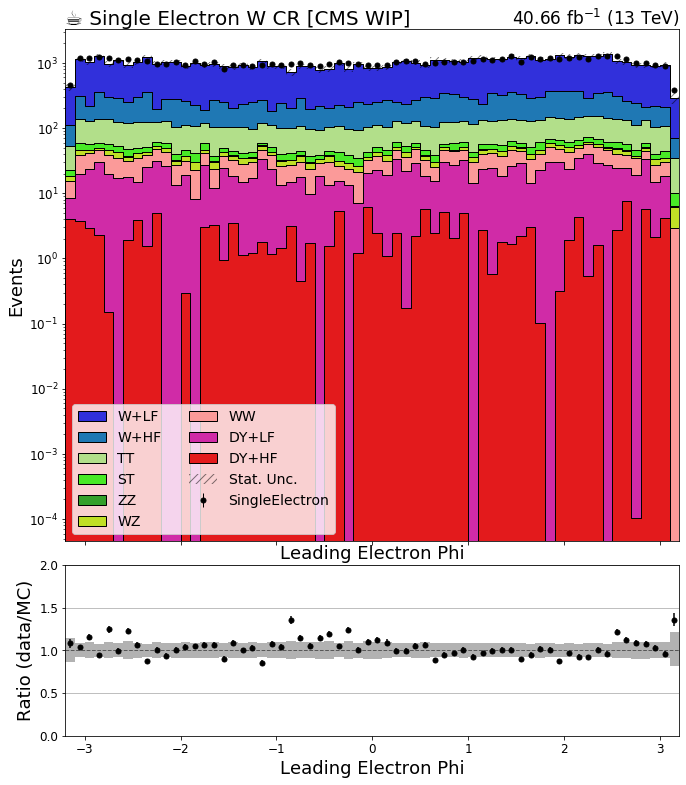

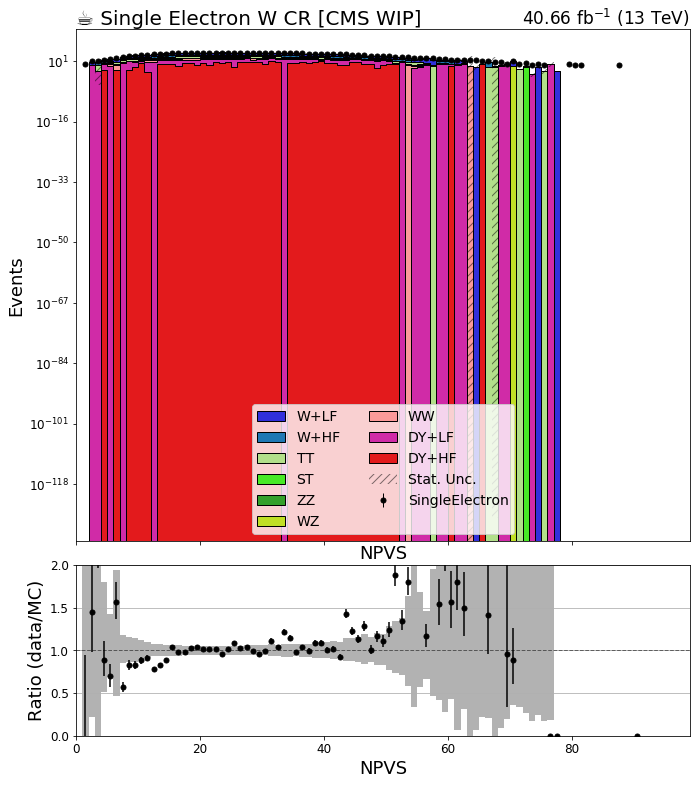

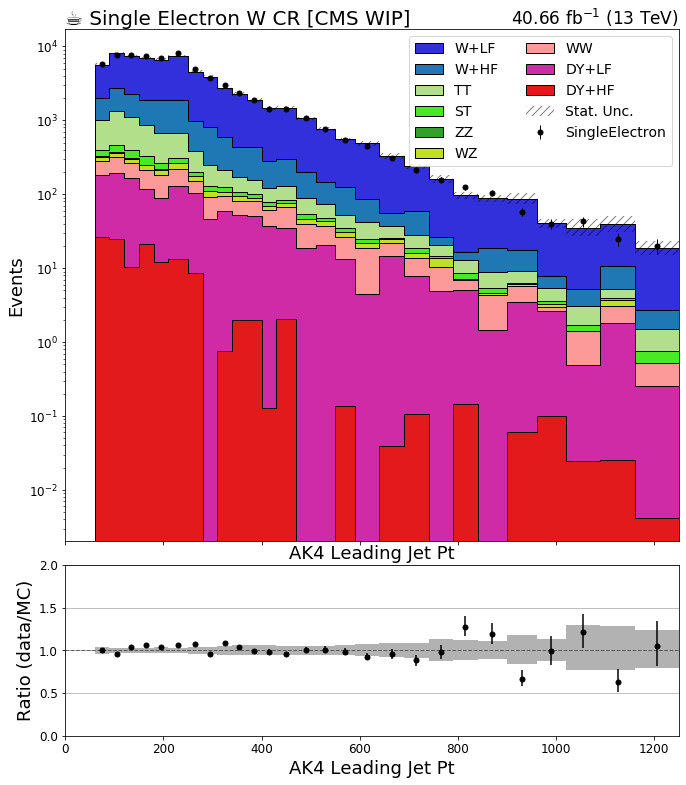

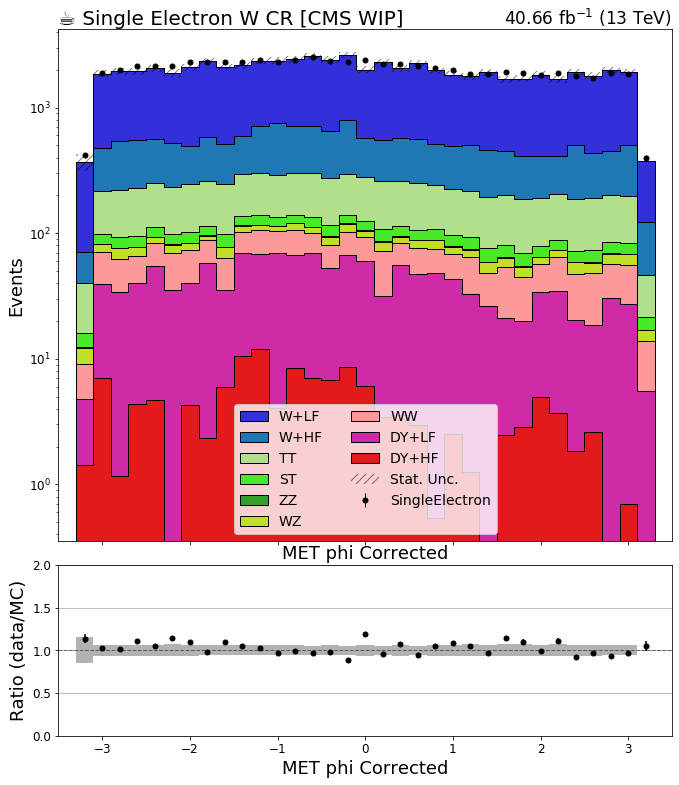

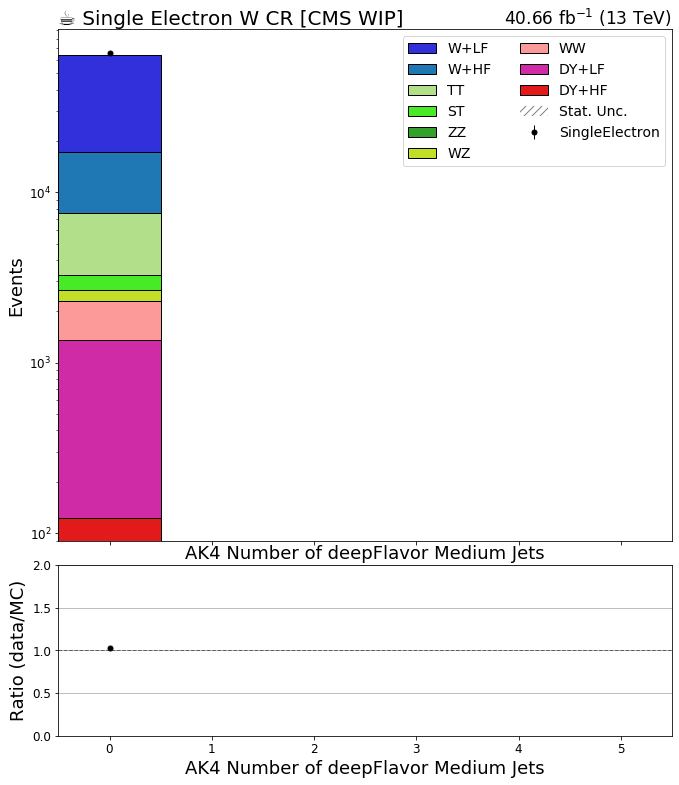

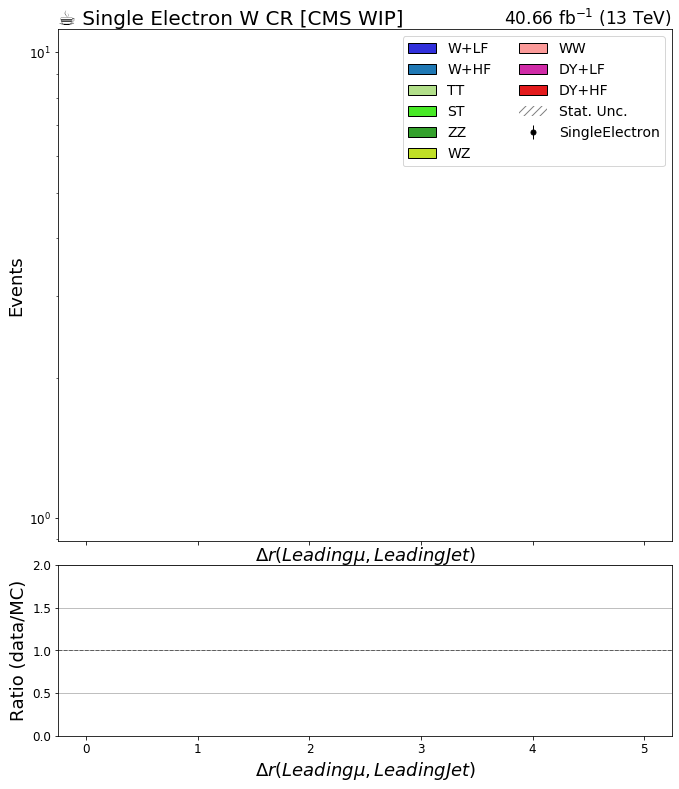

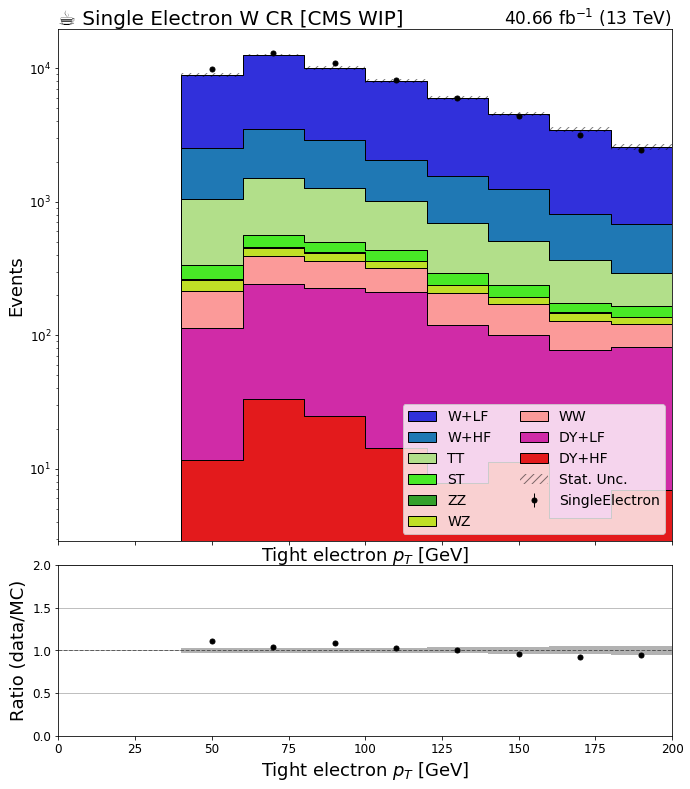

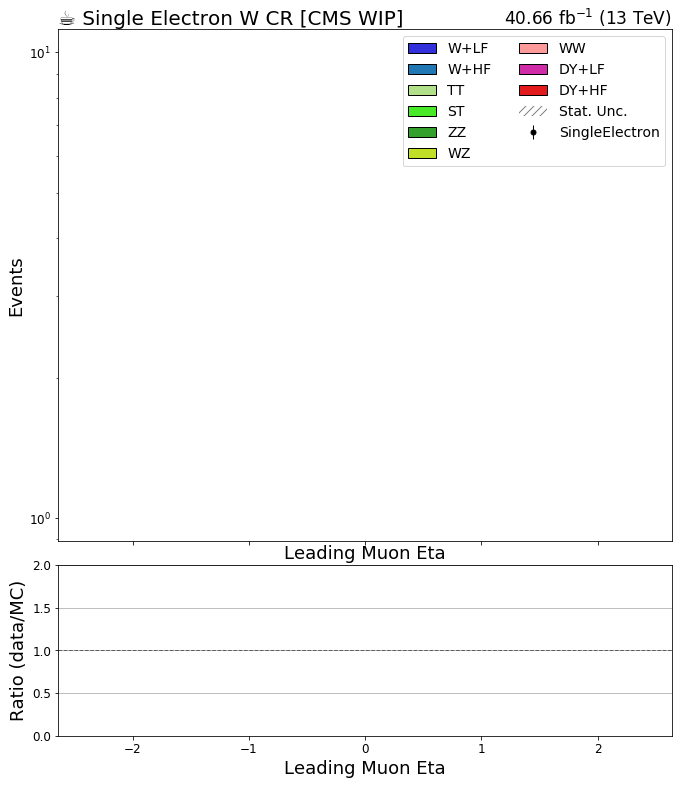

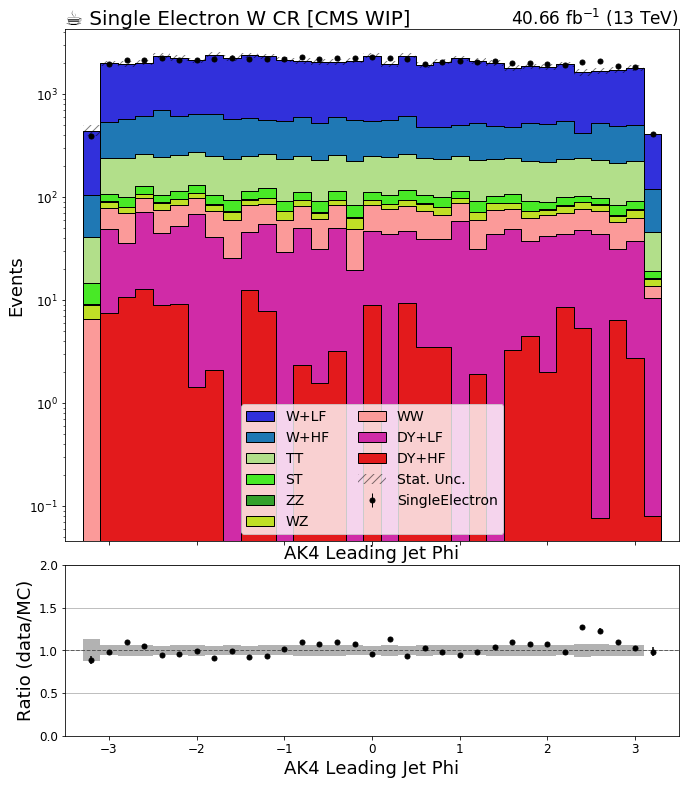

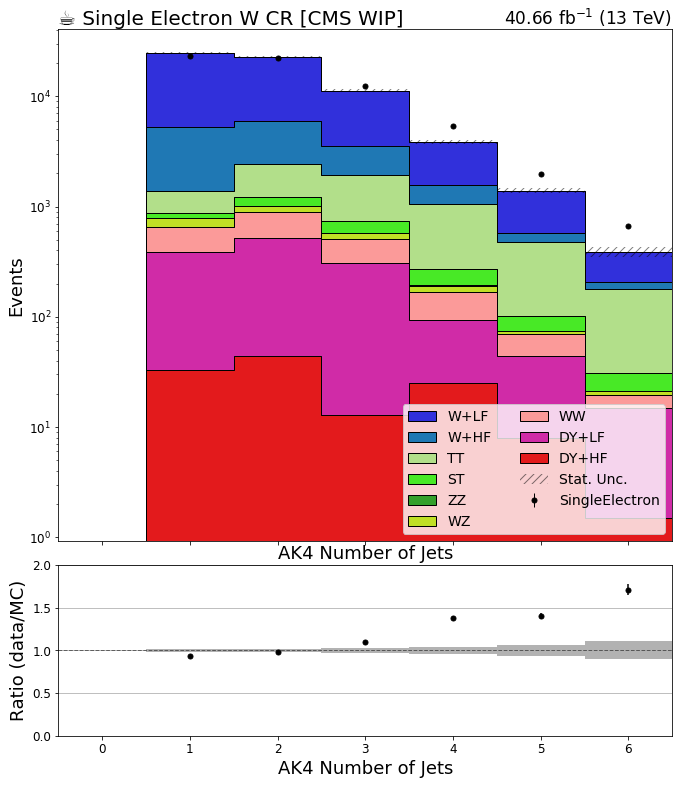

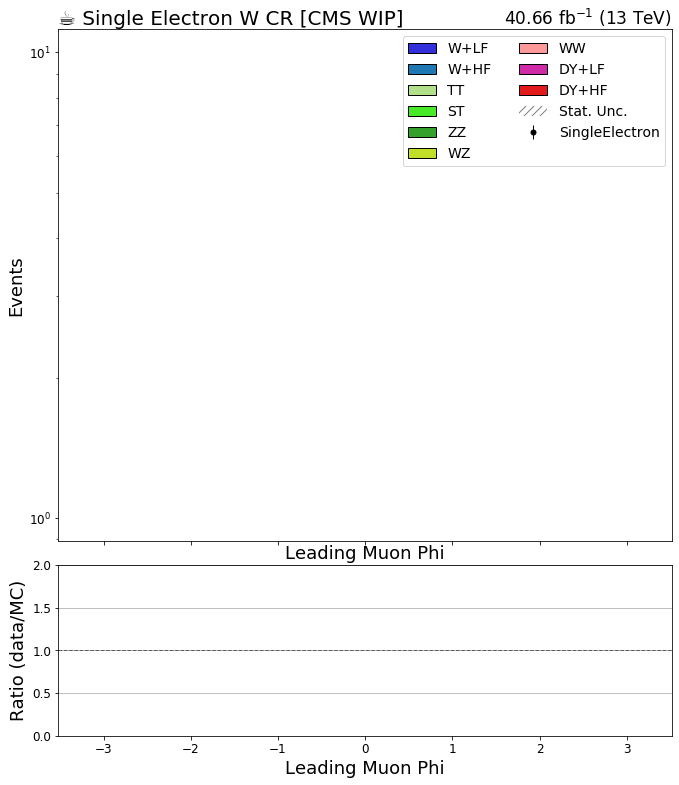

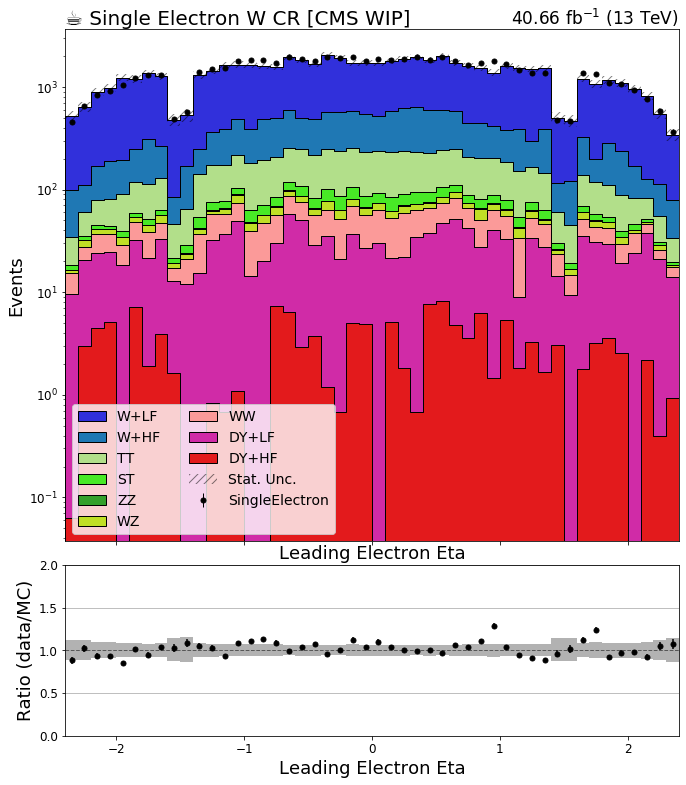

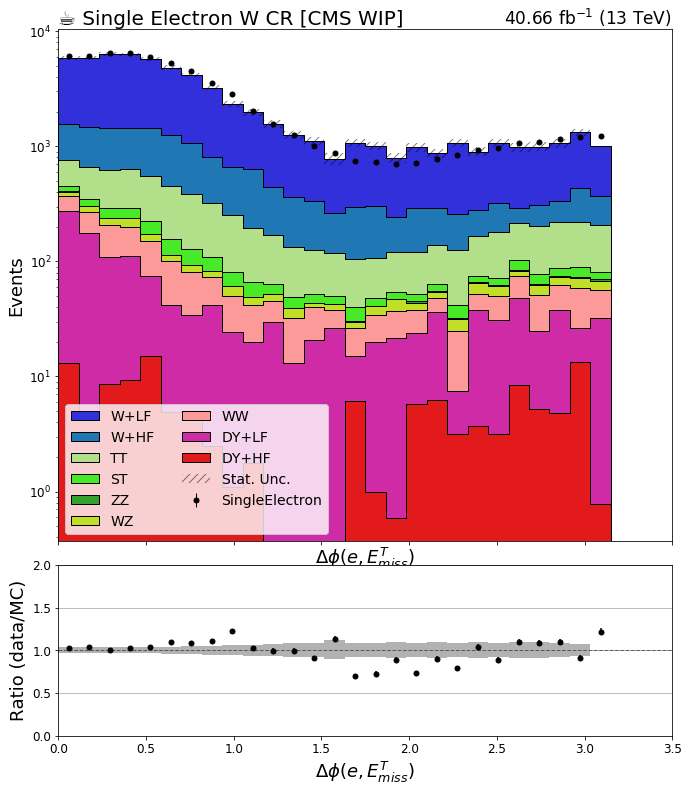

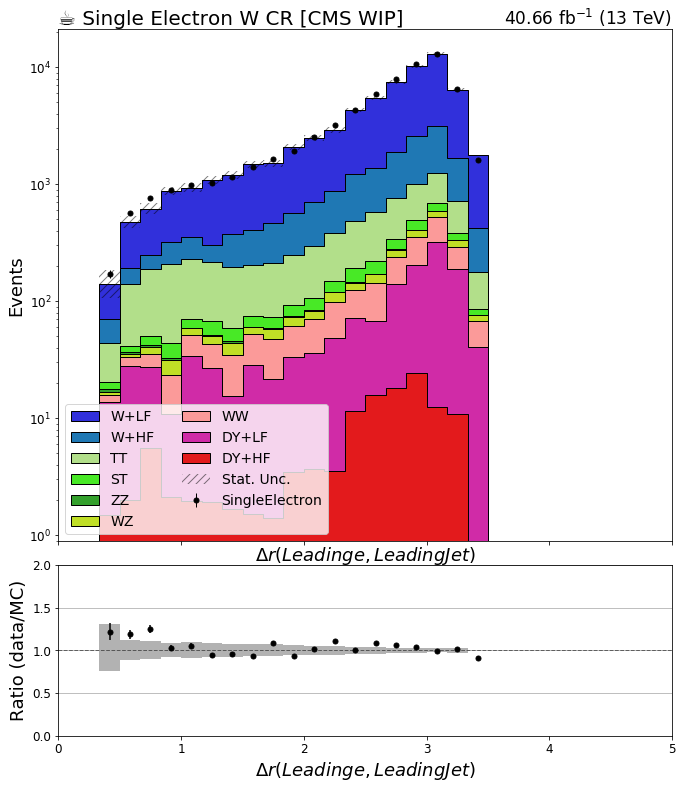

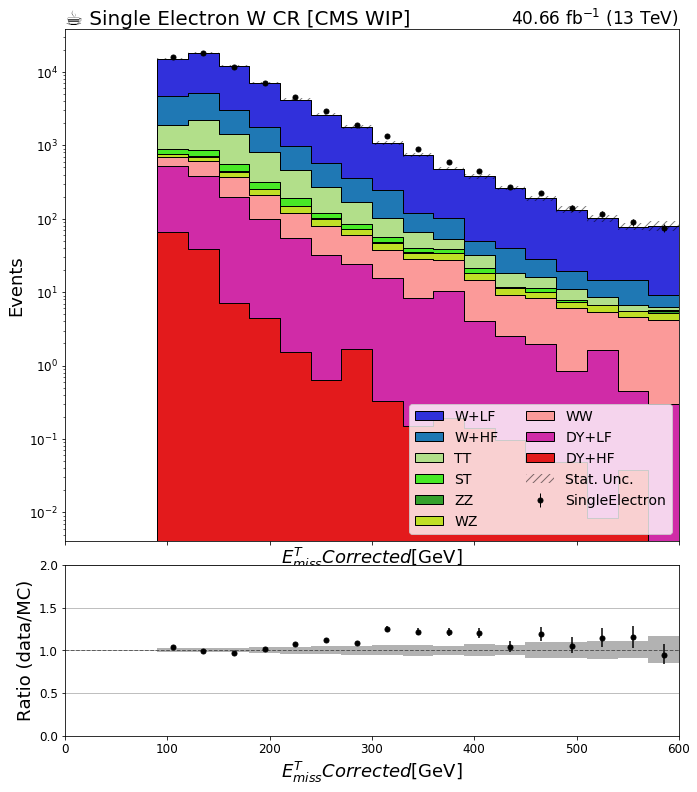

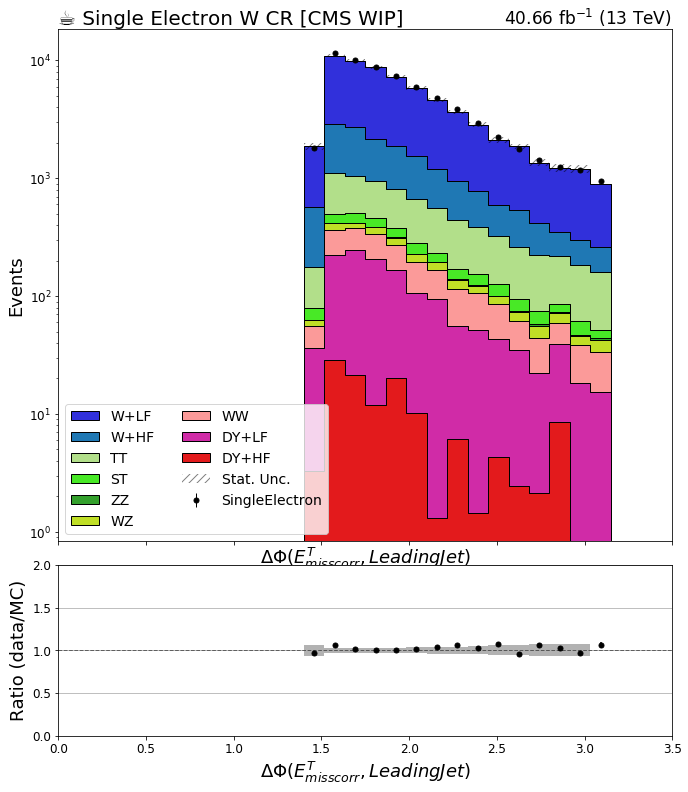

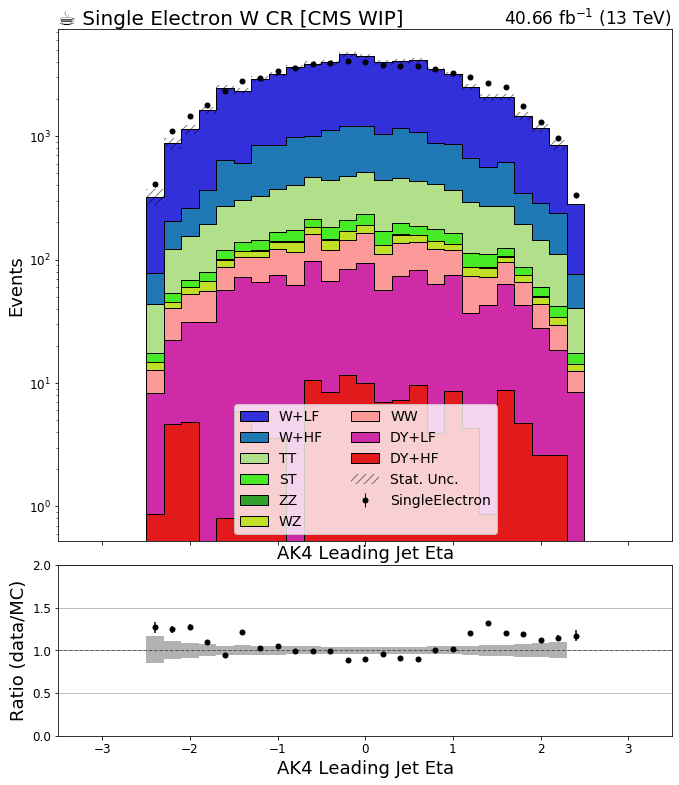

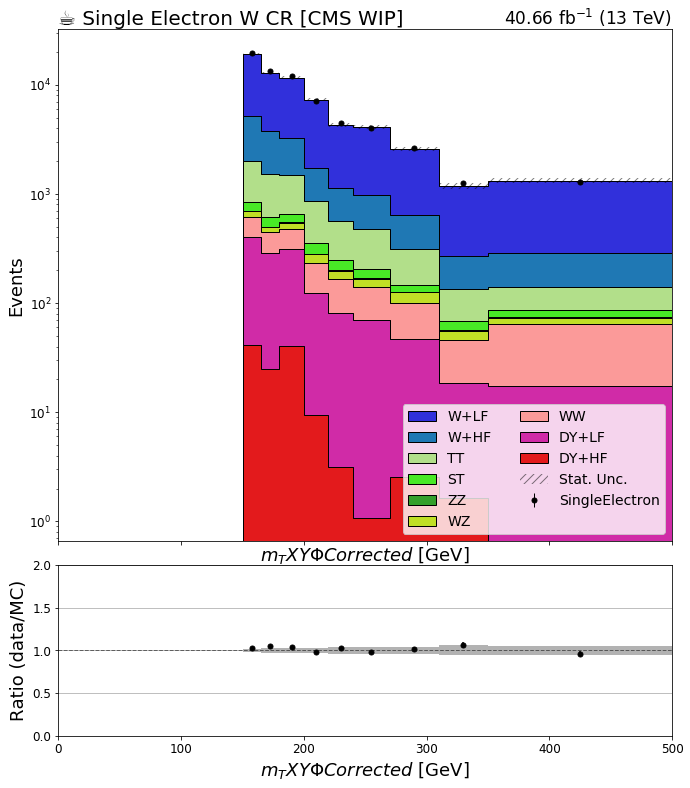

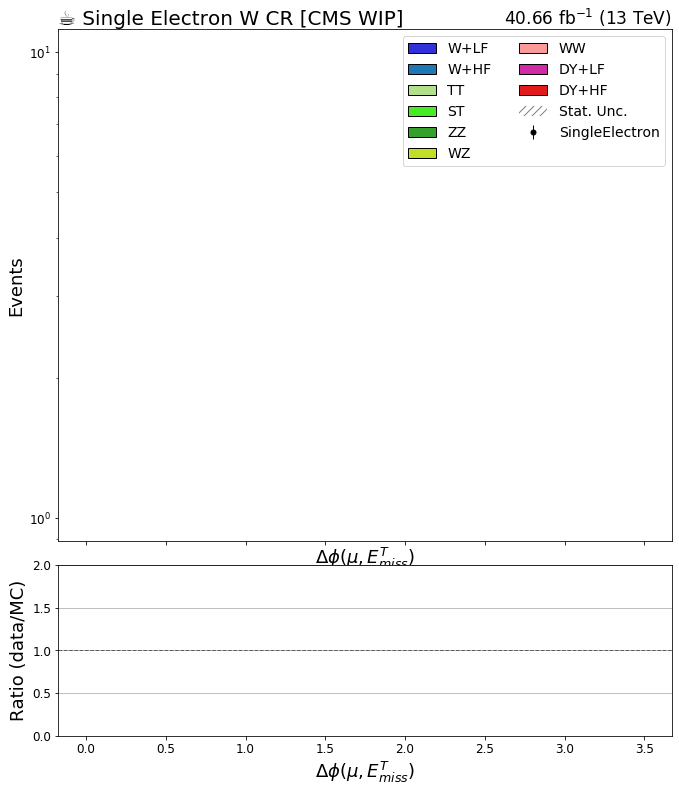

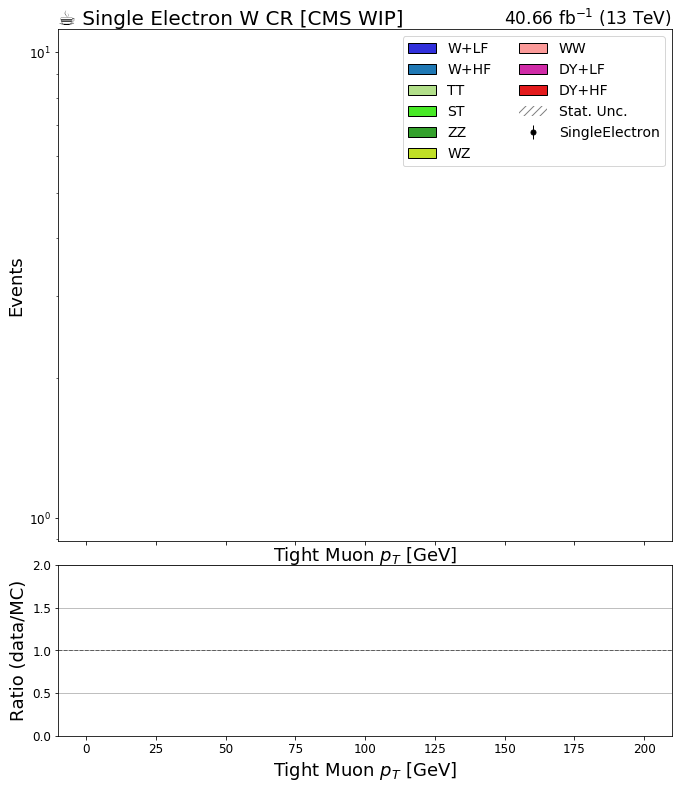

In [11]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2017'
region = 'wjete'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
#     if 'dphi' in key: continue
#     if key!='mT_corrected': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region) : continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = [ '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate('systematic','nominal').integrate('region',j)[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate('systematic','nominal').integrate('region',j),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('systematic','nominal').integrate('region',j).integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('systematic','nominal').integrate('region',j).sum('process'),
                   ax=rax,
#                    overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.,2.)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]]+ " [CMS WIP]", fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"40.66 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

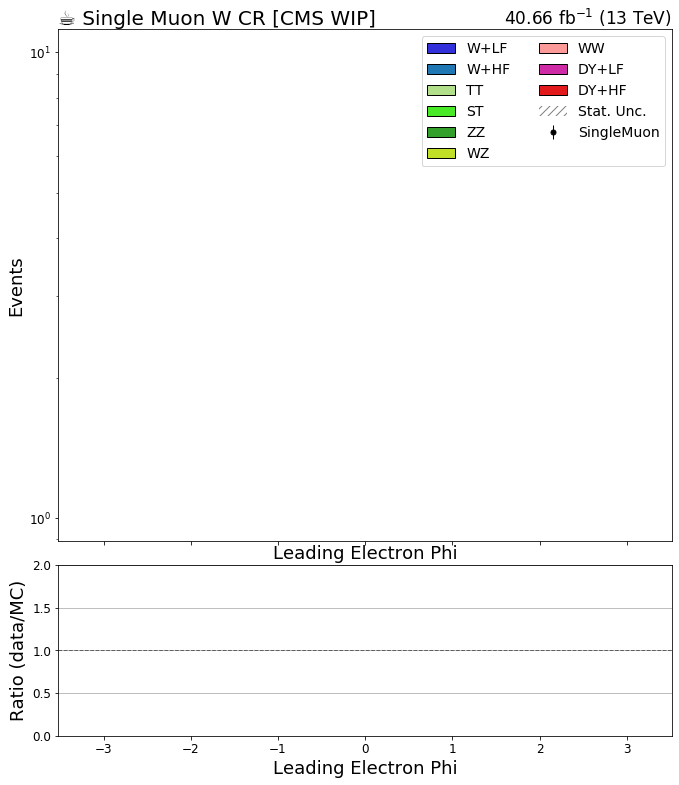

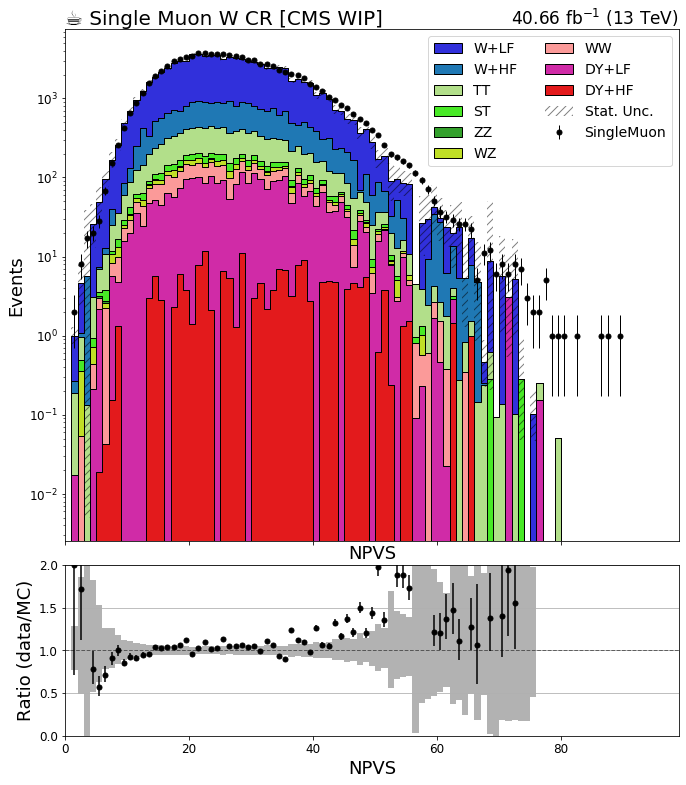

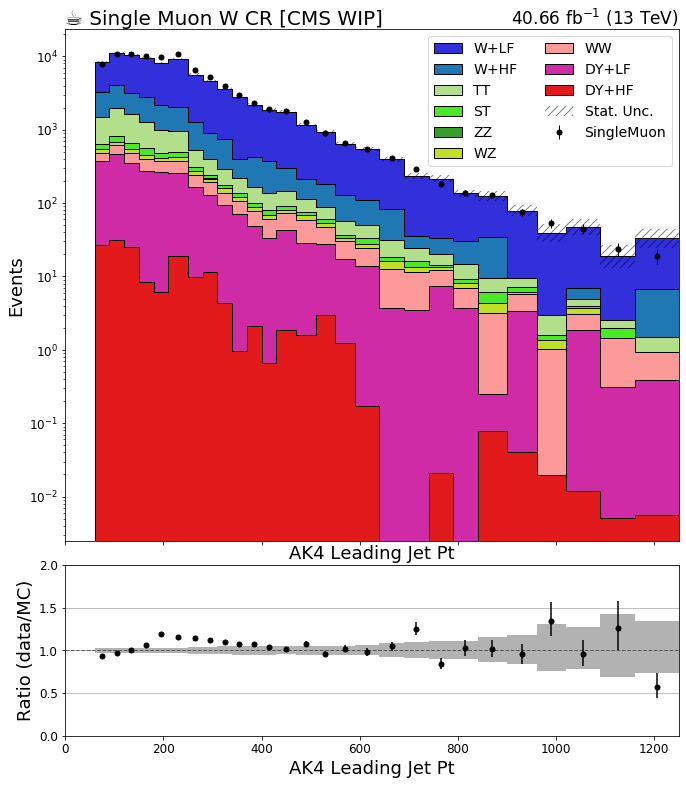

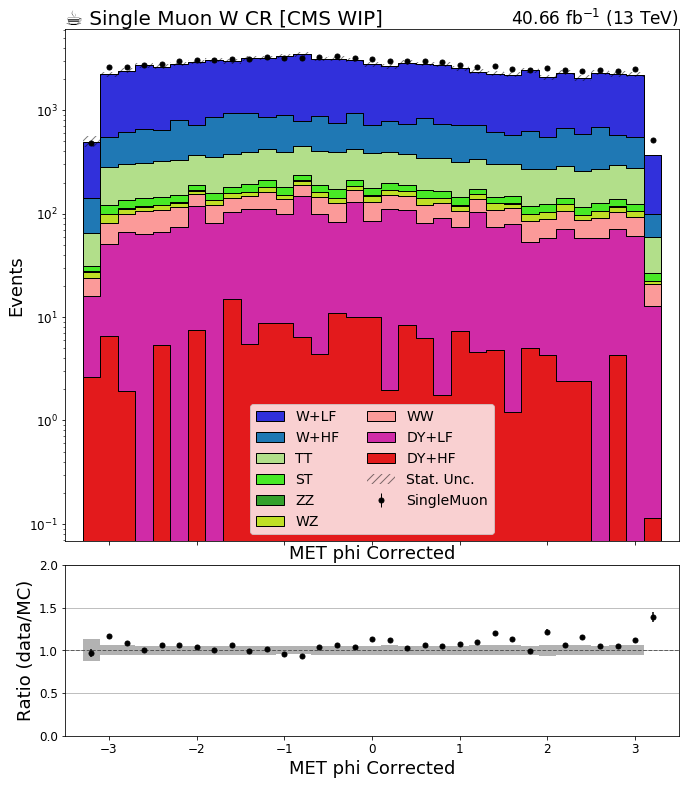

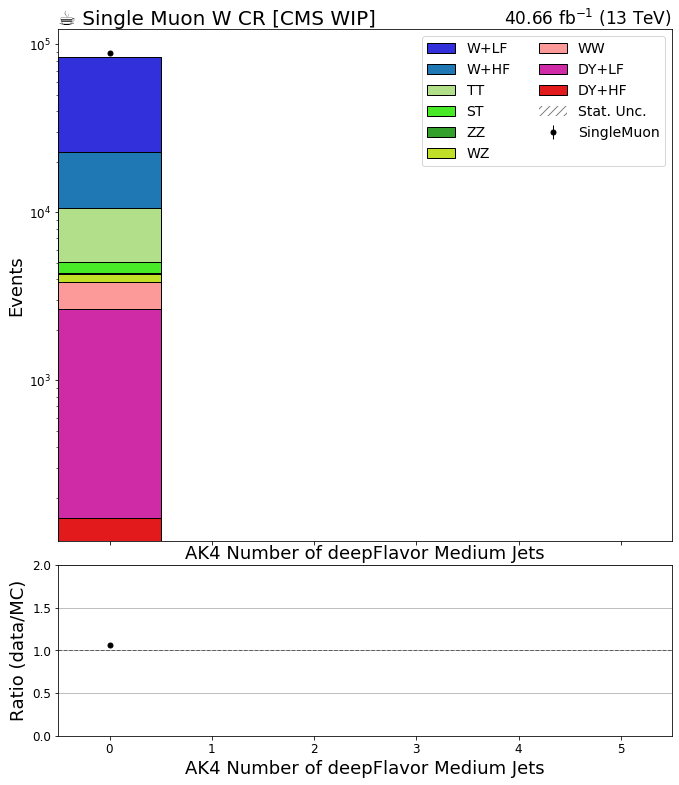

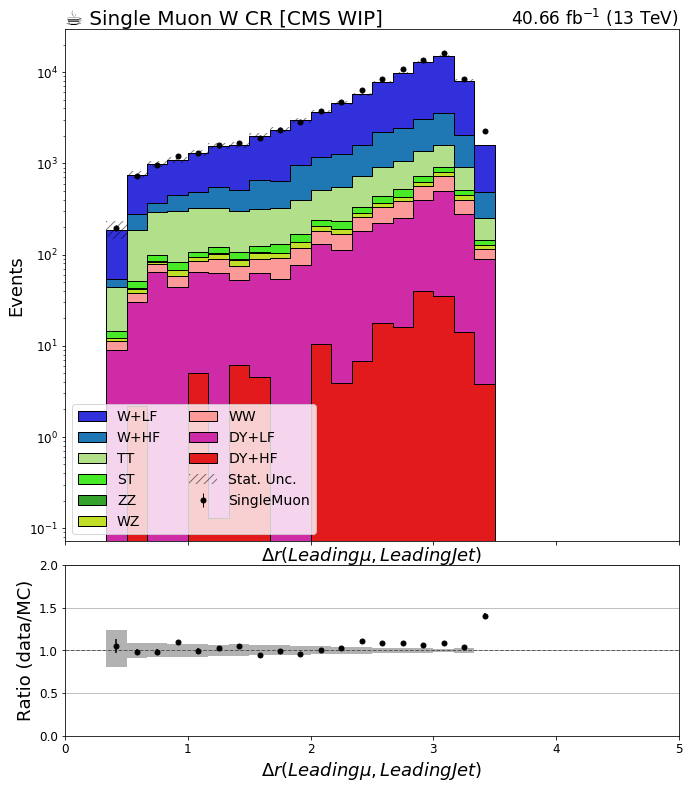

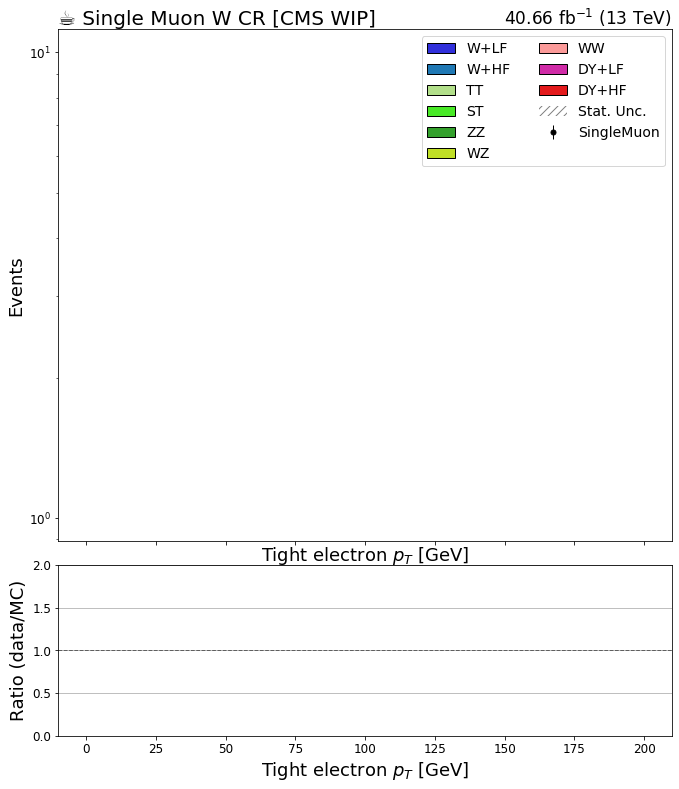

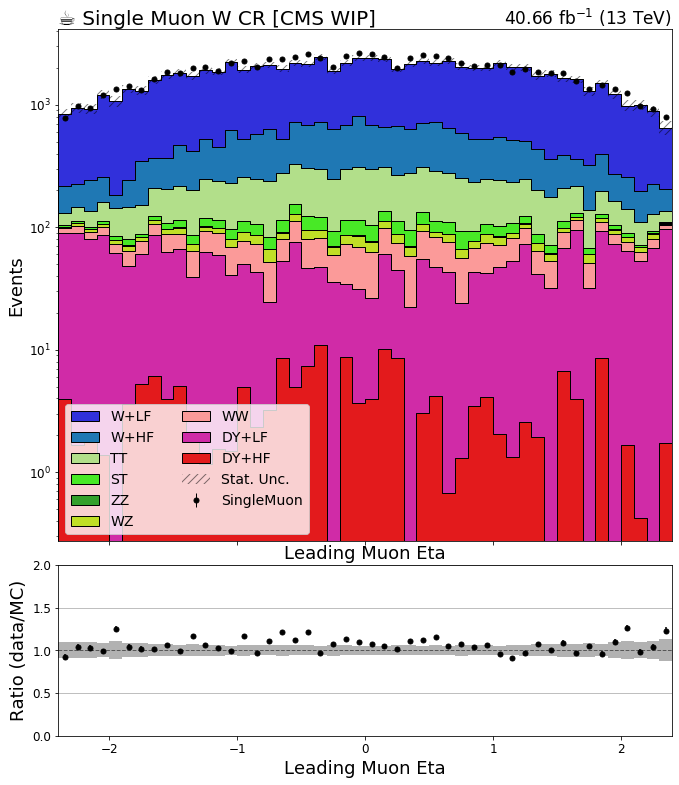

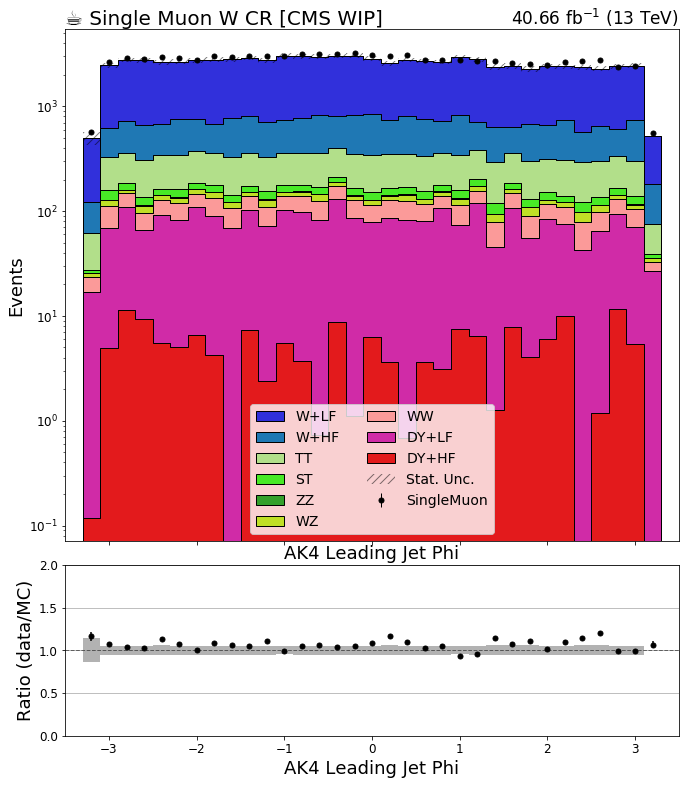

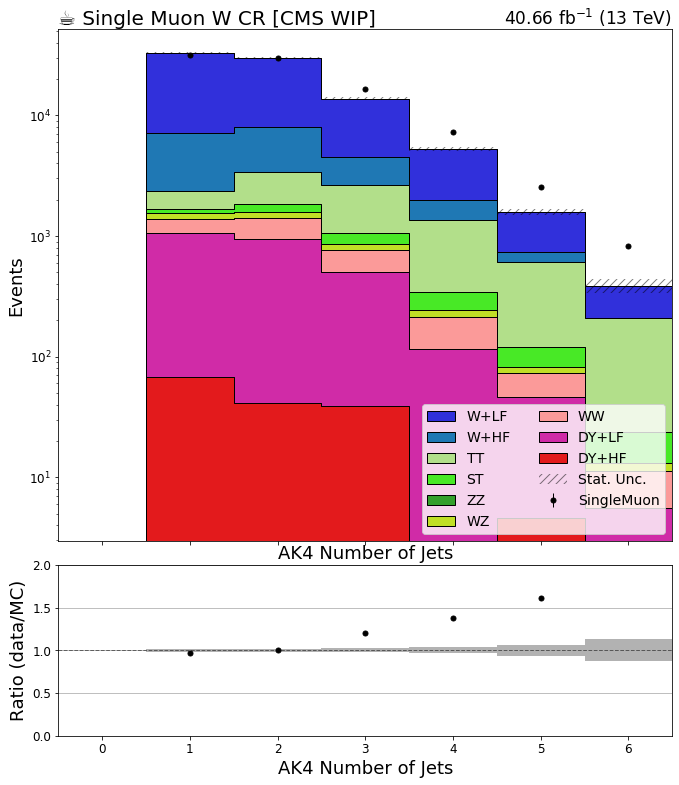

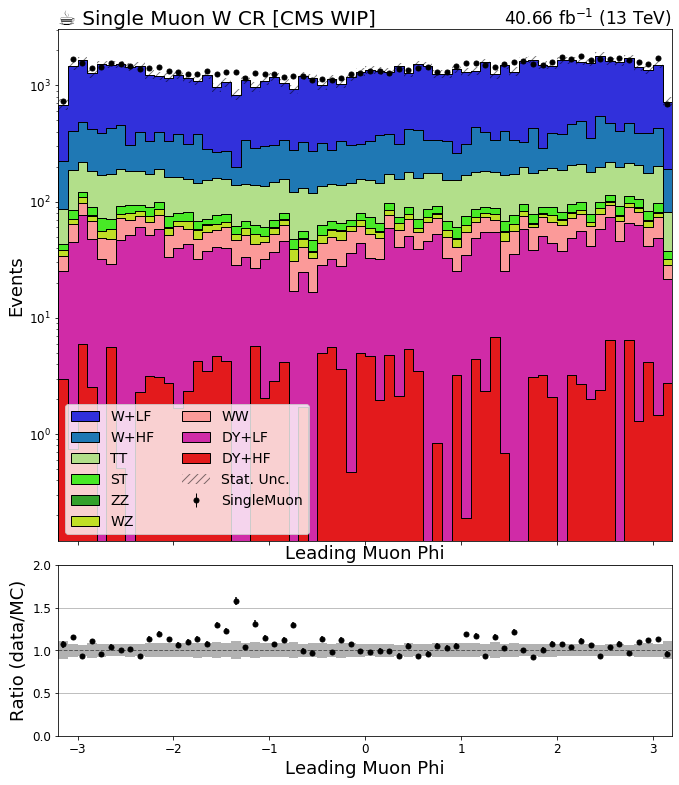

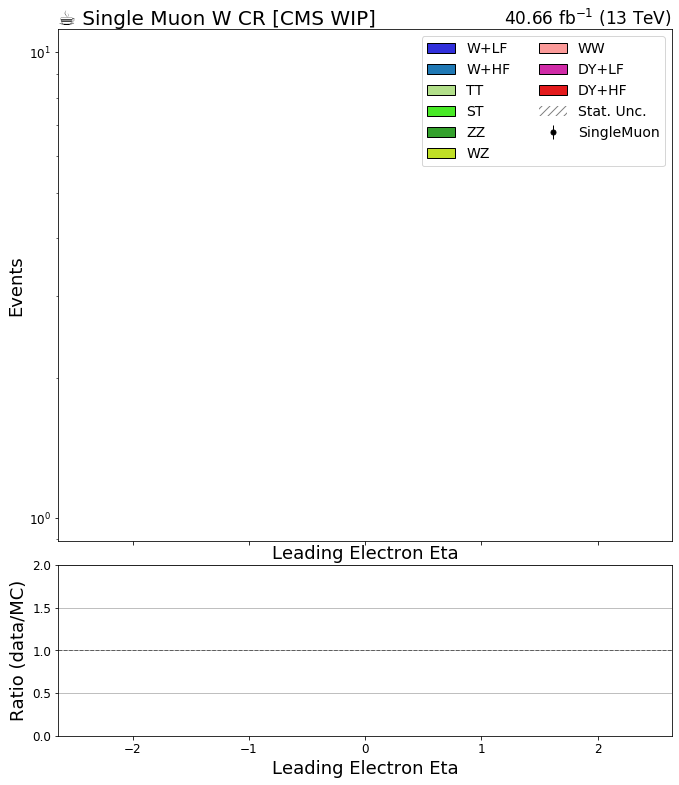

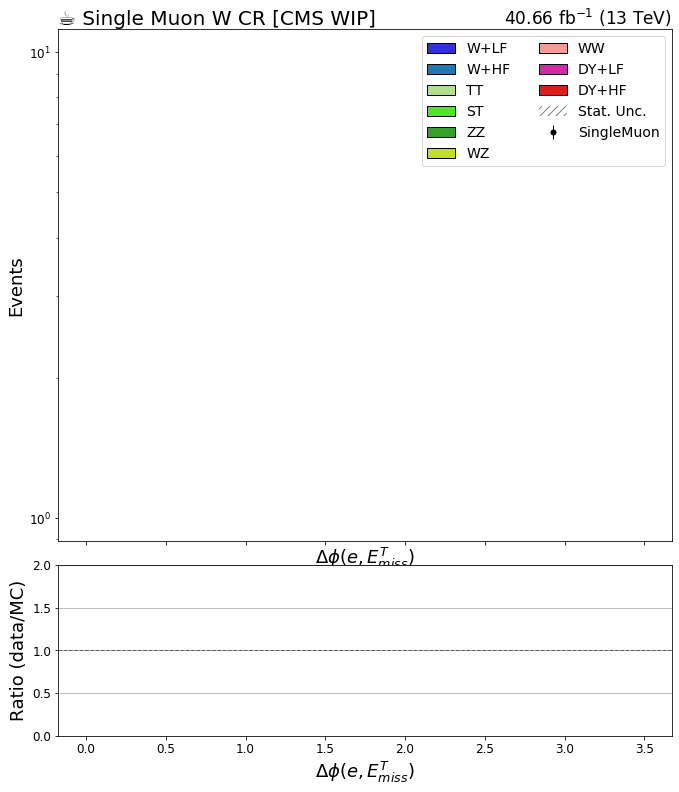

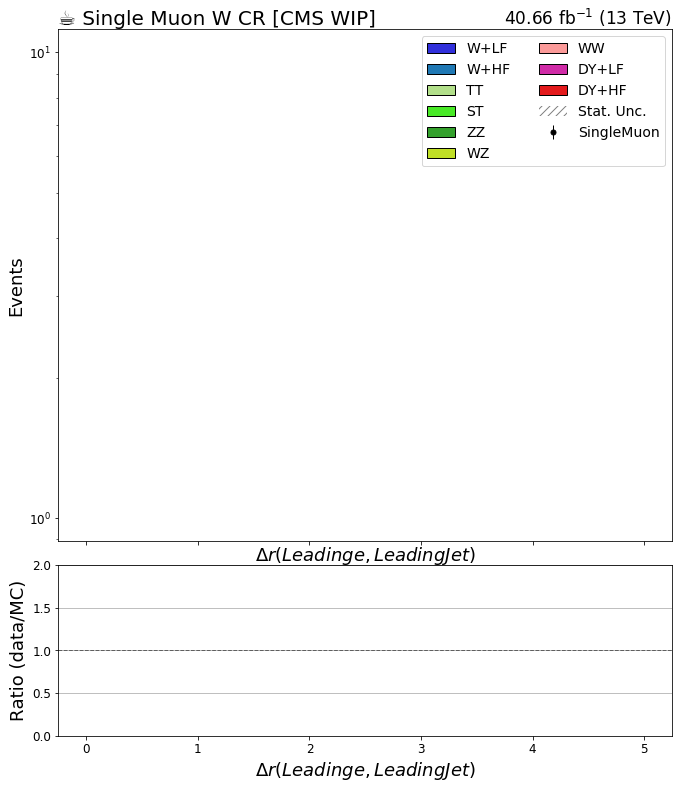

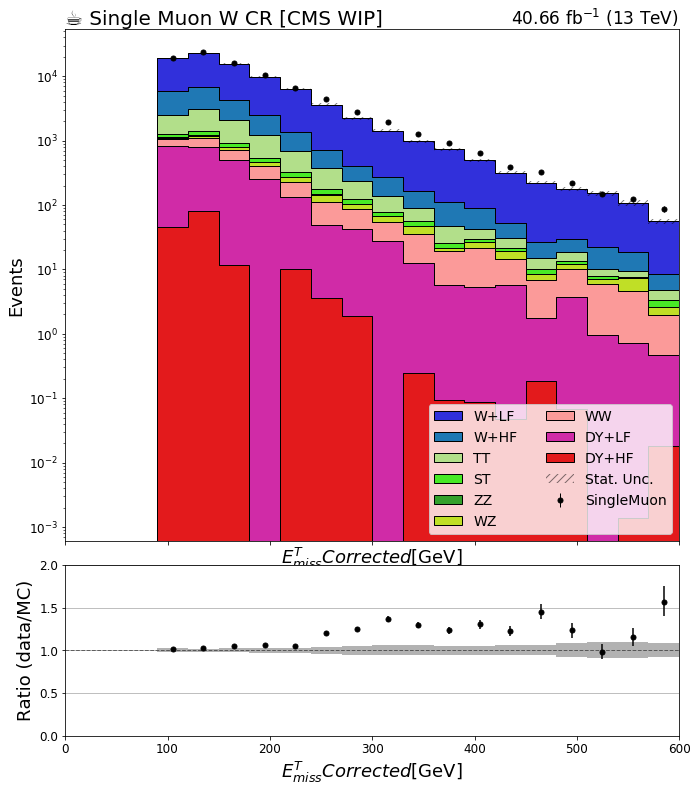

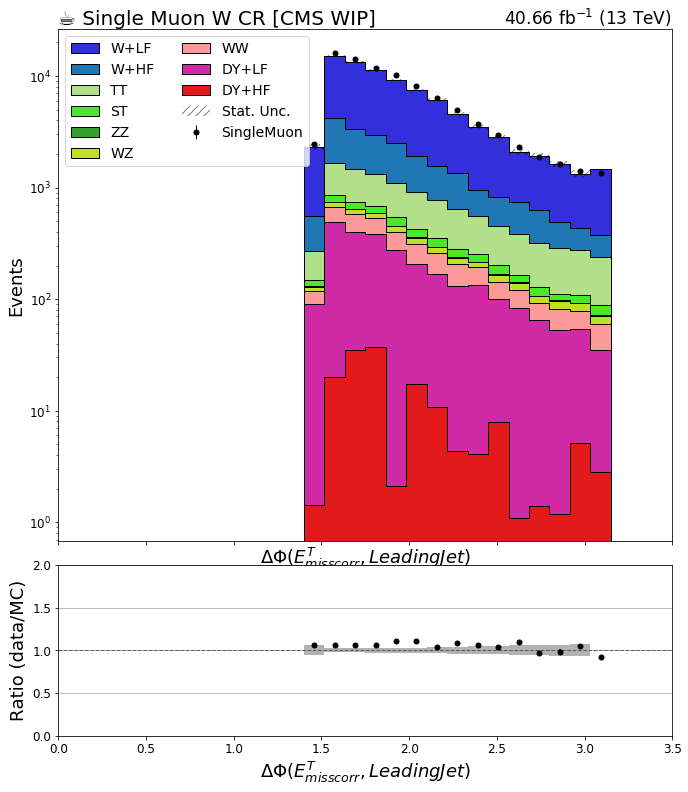

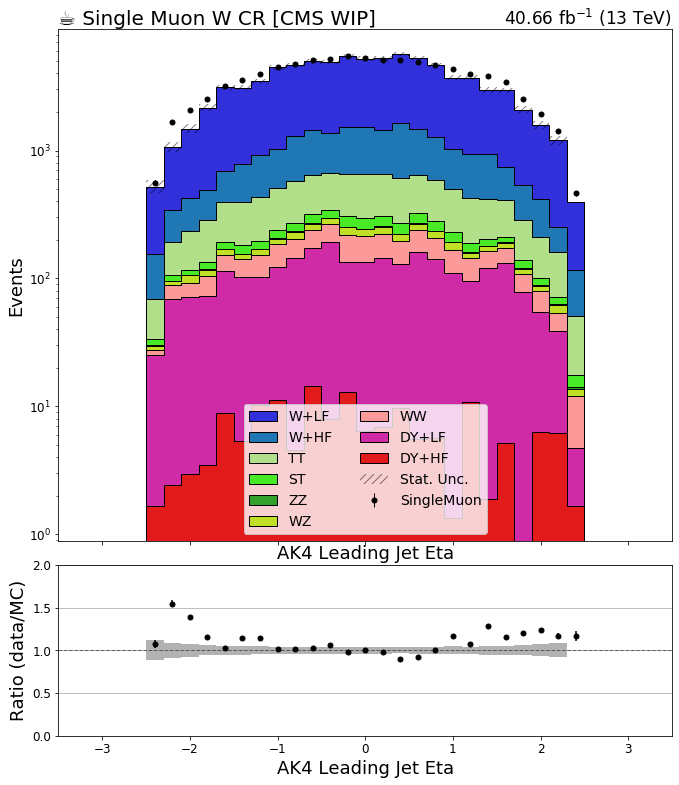

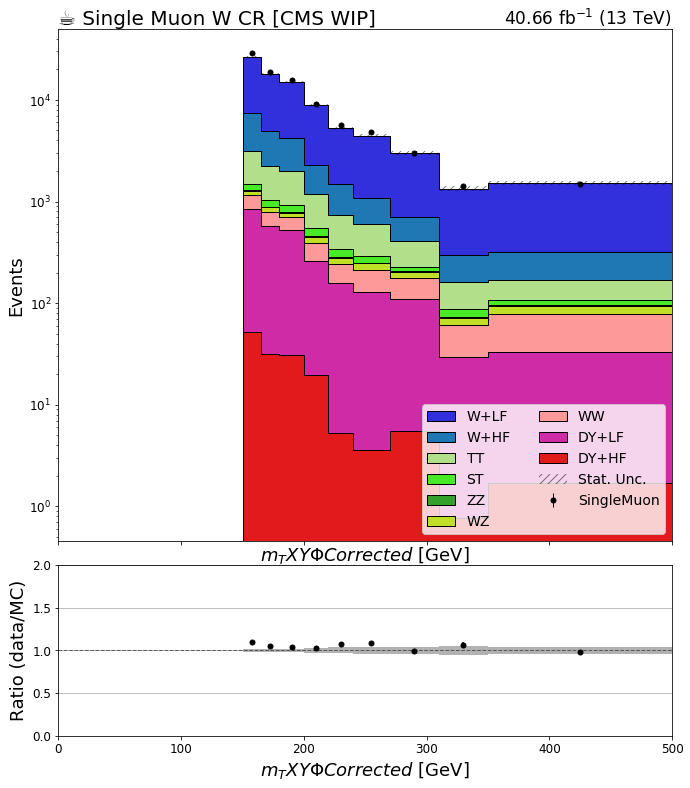

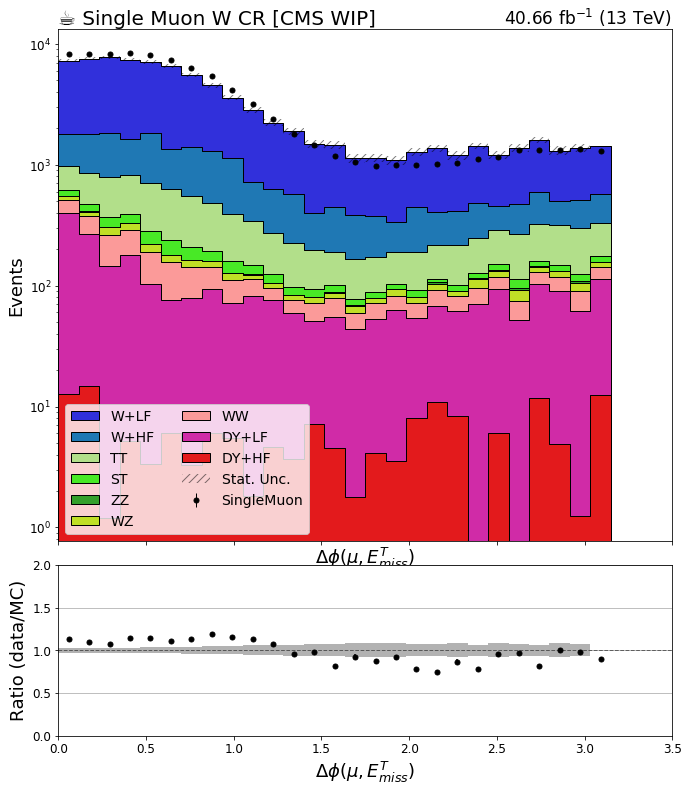

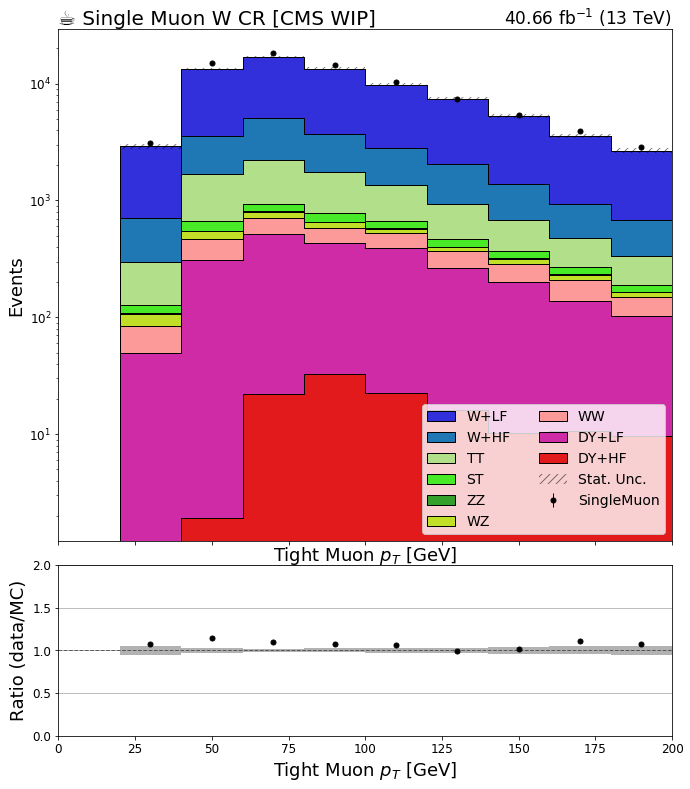

In [12]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2017'
region = 'wjetm'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
#     if 'dphi' in key: continue
#     if key!='mT_corrected': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region) : continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = [ '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate('systematic','nominal').integrate('region',j)[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate('systematic','nominal').integrate('region',j),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('systematic','nominal').integrate('region',j).integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('systematic','nominal').integrate('region',j).sum('process'),
                   ax=rax,
#                    overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.,2.)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]]+ " [CMS WIP]", fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"40.66 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

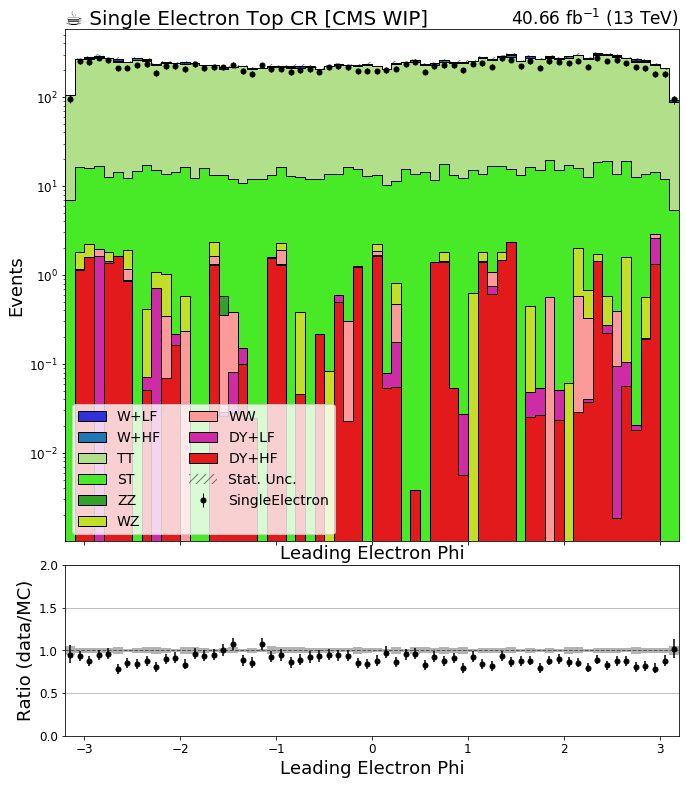

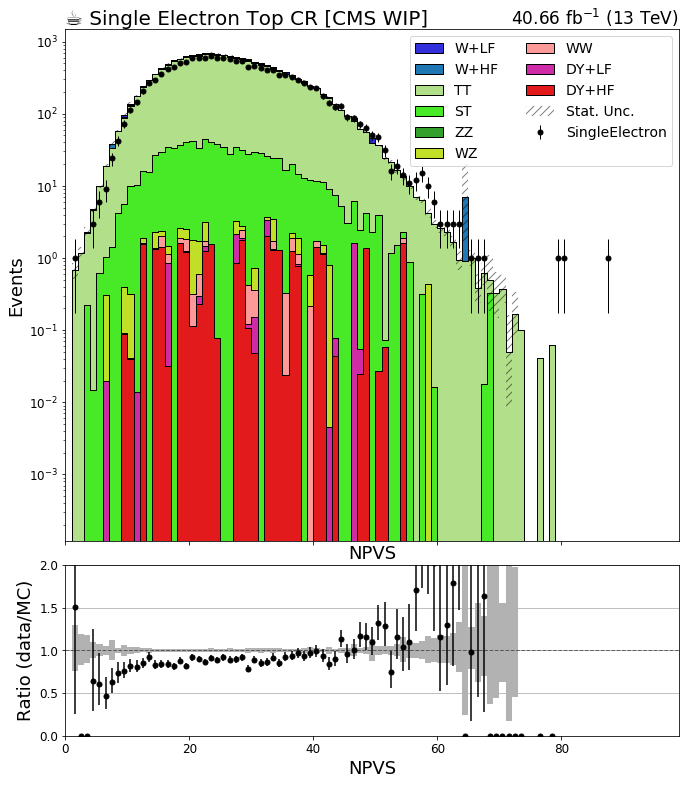

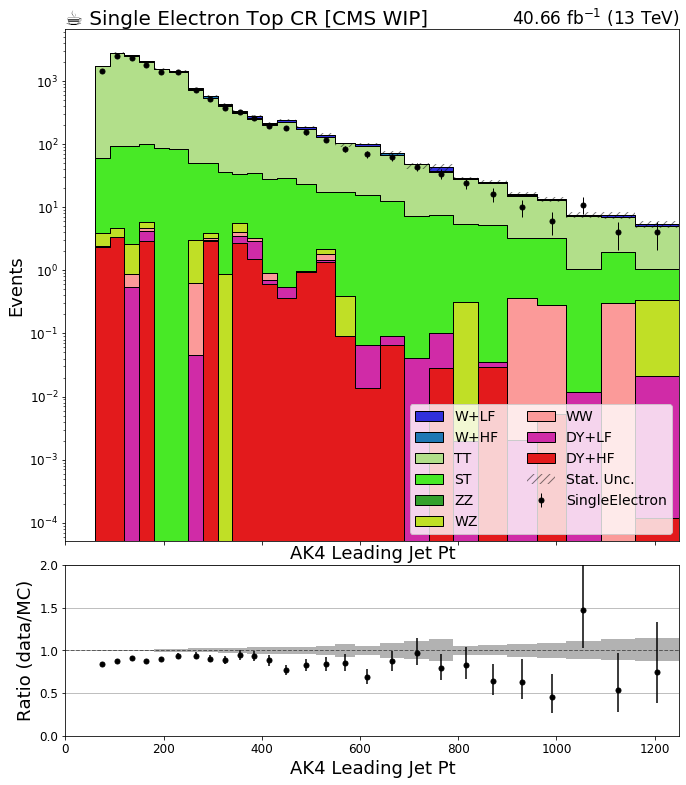

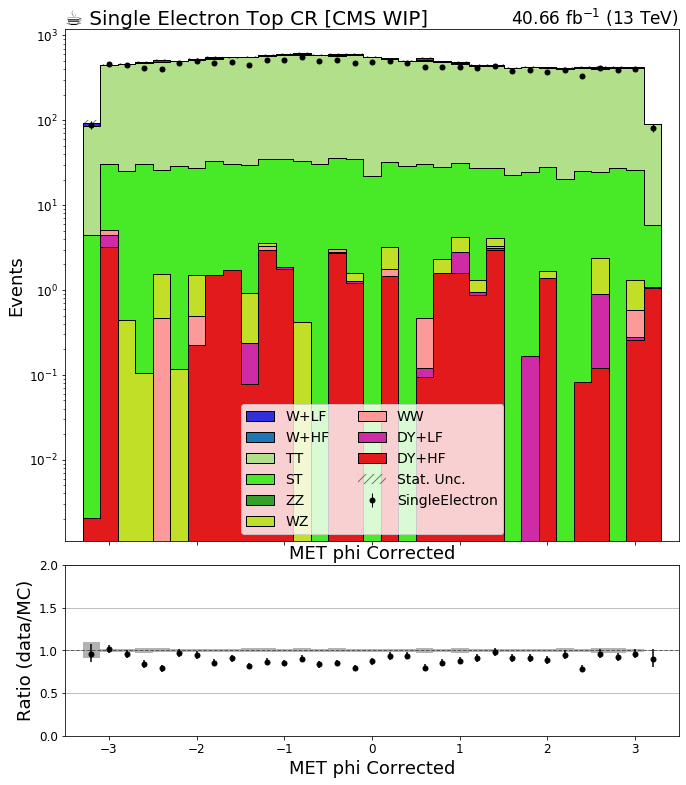

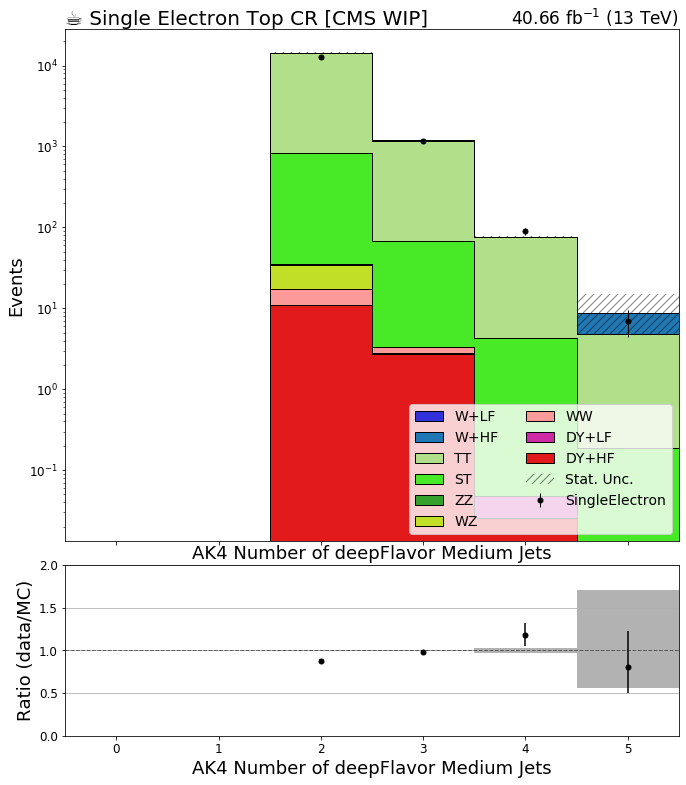

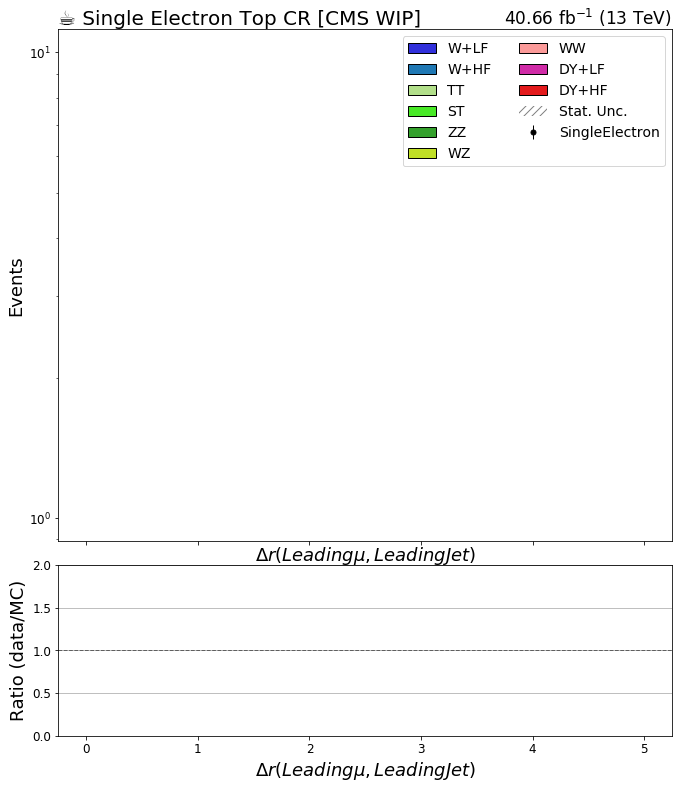

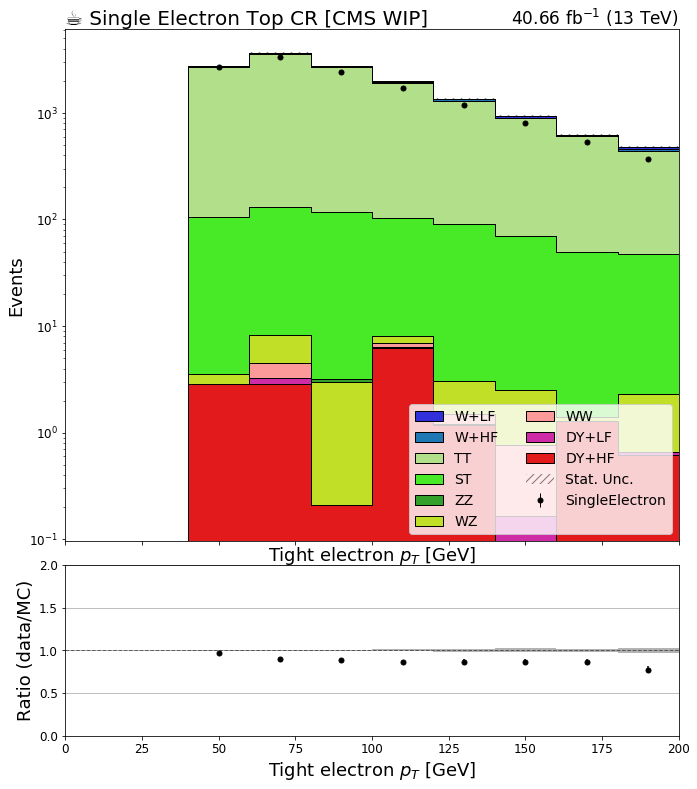

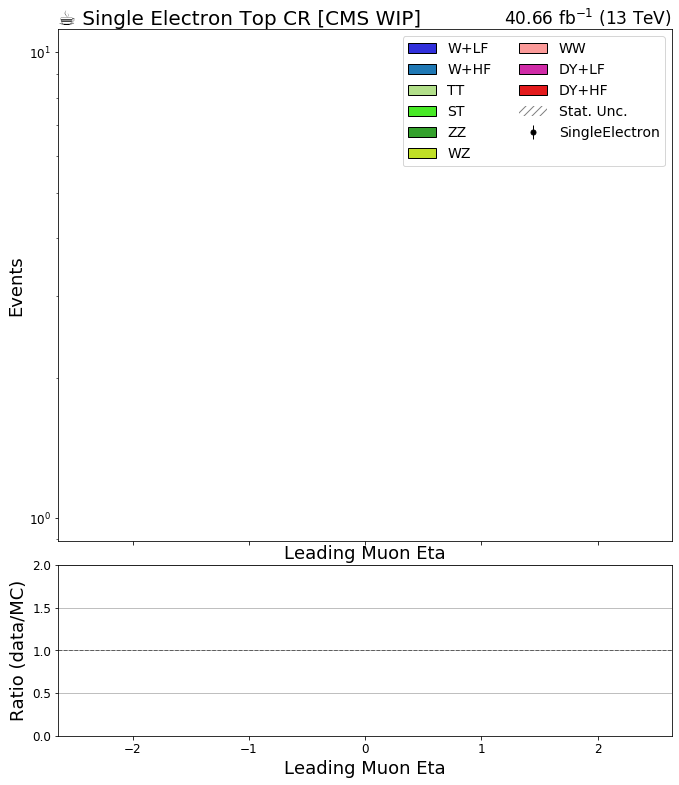

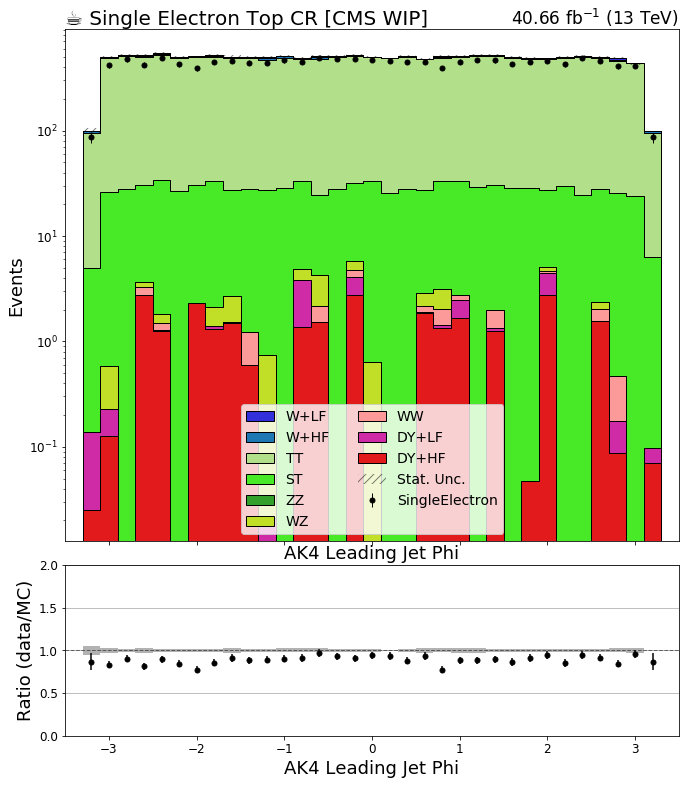

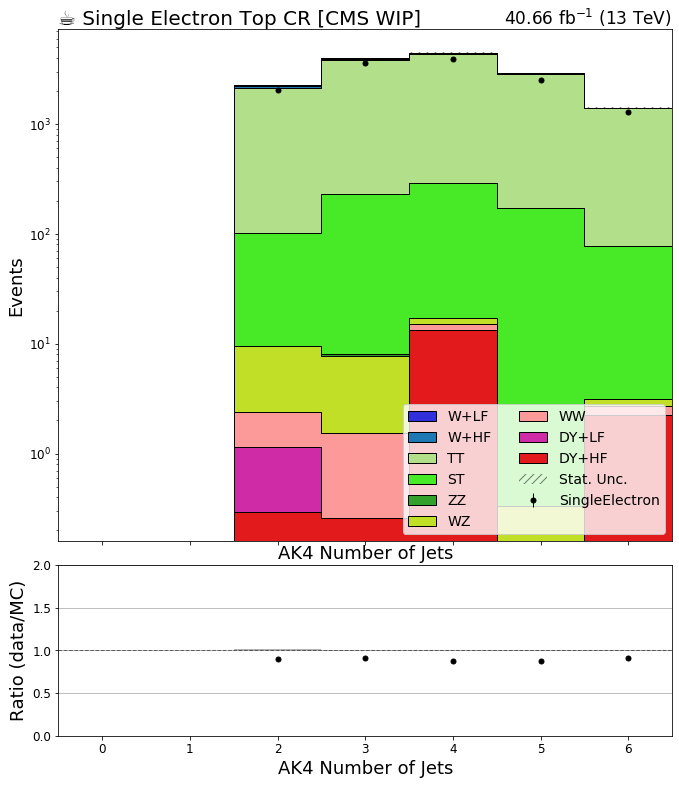

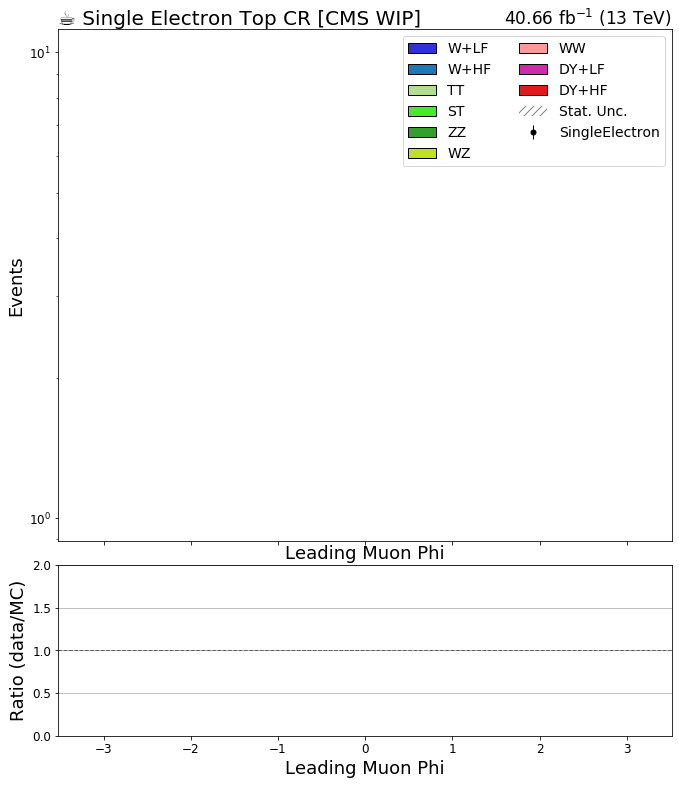

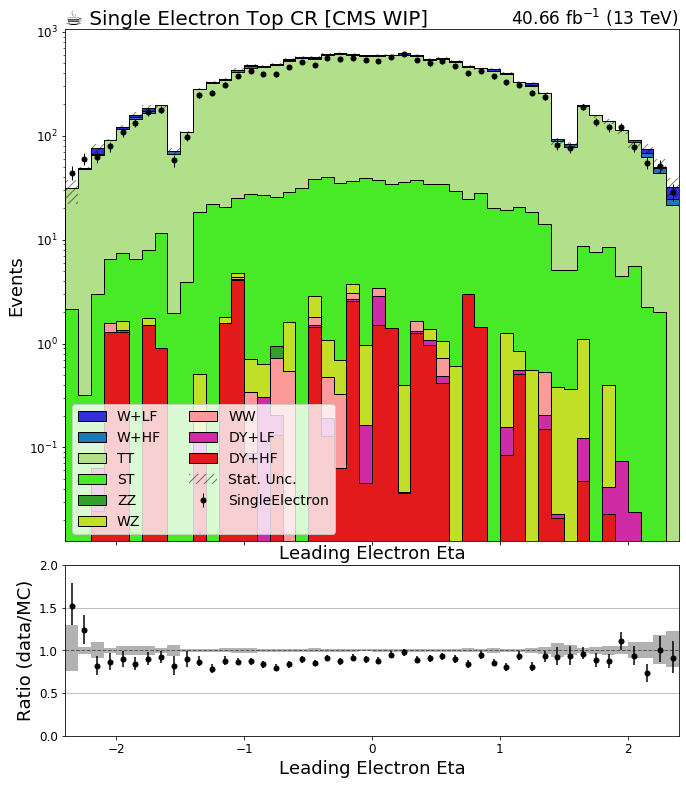

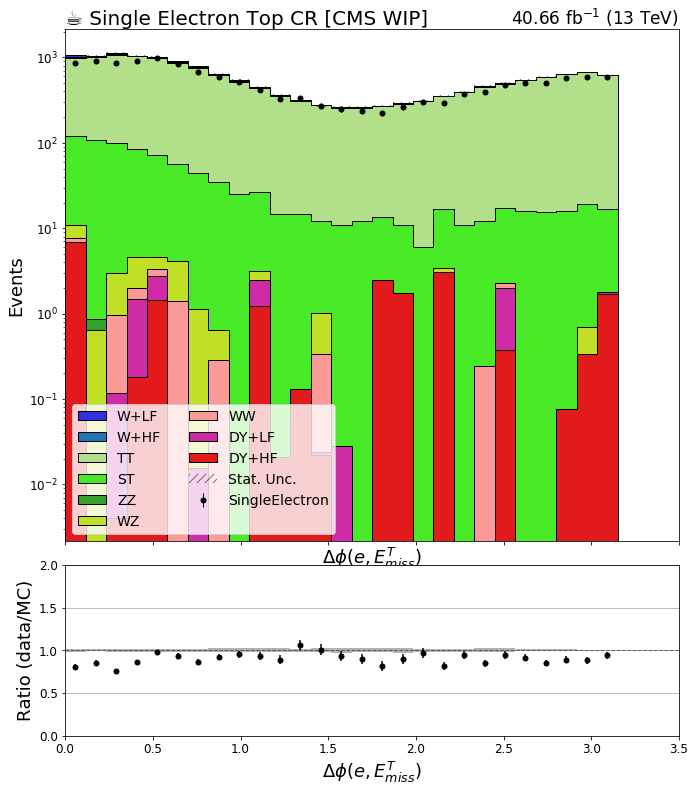

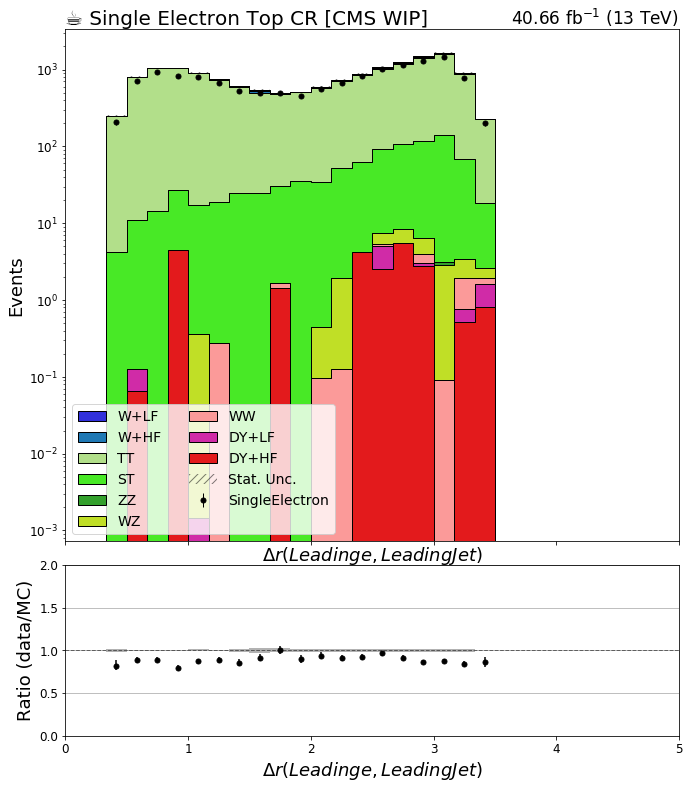

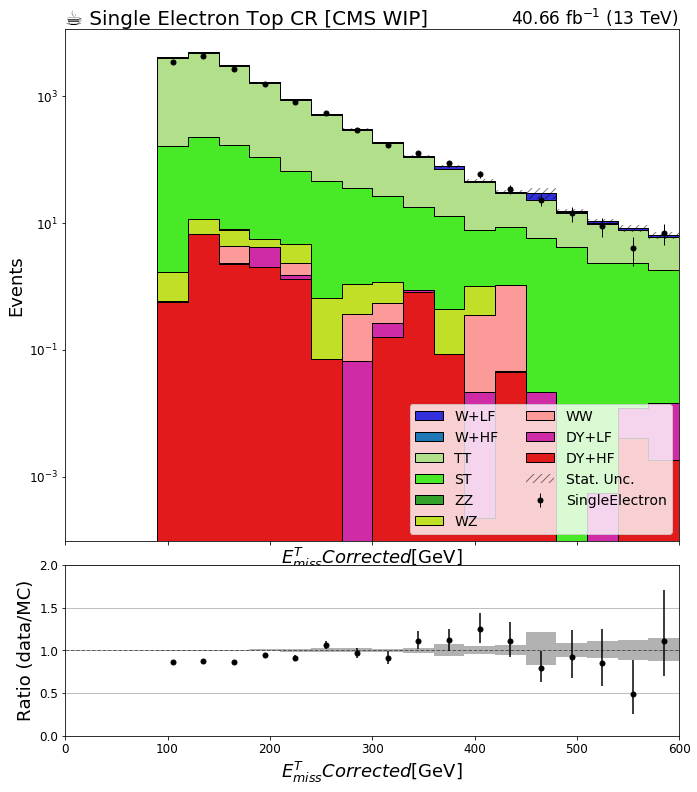

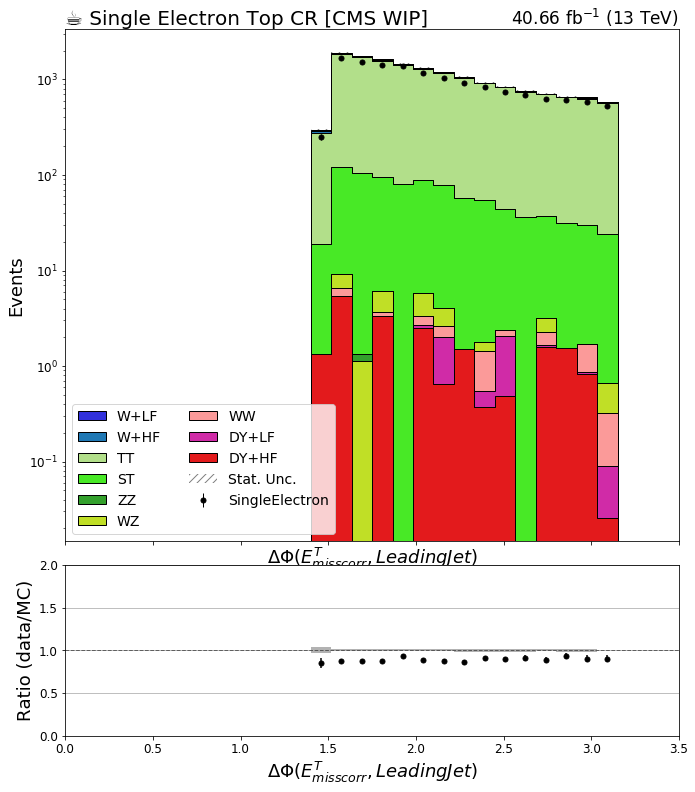

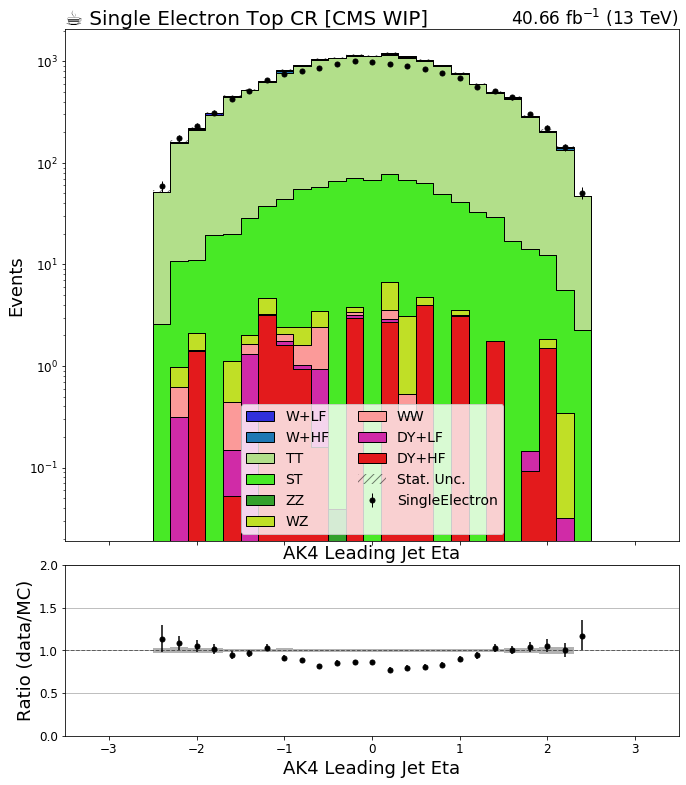

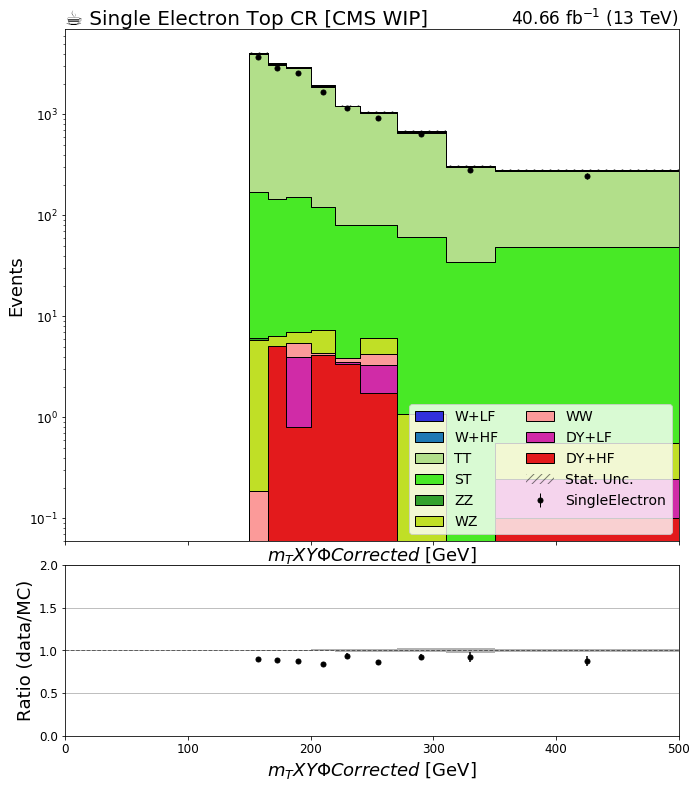

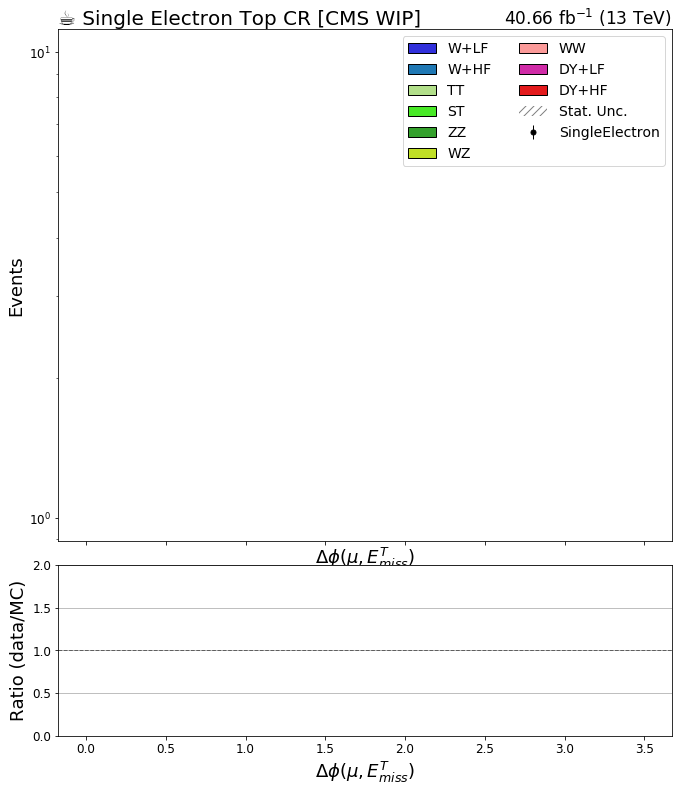

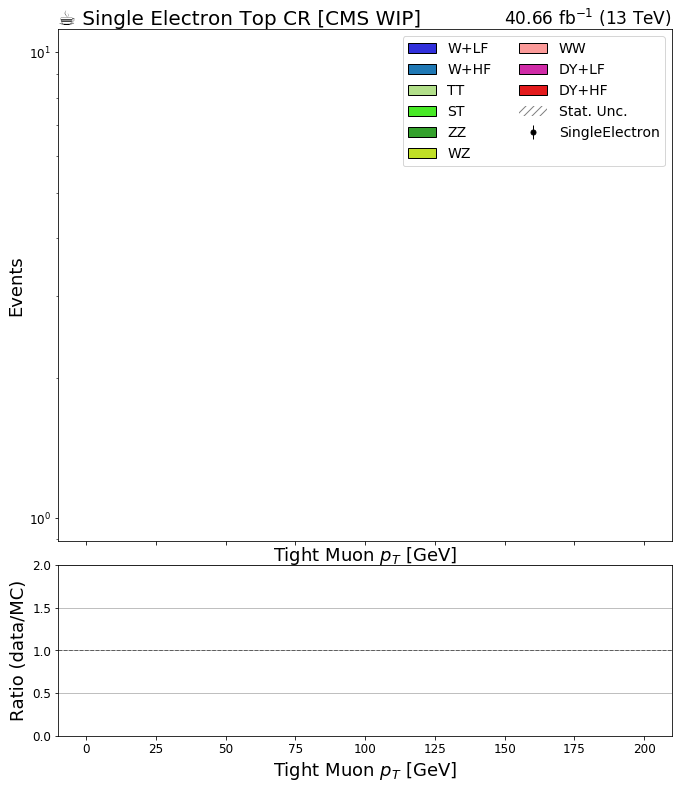

In [13]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2017'
region = 'ttbare'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
#     if 'dphi' in key: continue
#     if key!='mT_corrected': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region) : continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = [ '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate('systematic','nominal').integrate('region',j)[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate('systematic','nominal').integrate('region',j),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('systematic','nominal').integrate('region',j).integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('systematic','nominal').integrate('region',j).sum('process'),
                   ax=rax,
#                    overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.,2.)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]]+ " [CMS WIP]", fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"40.66 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

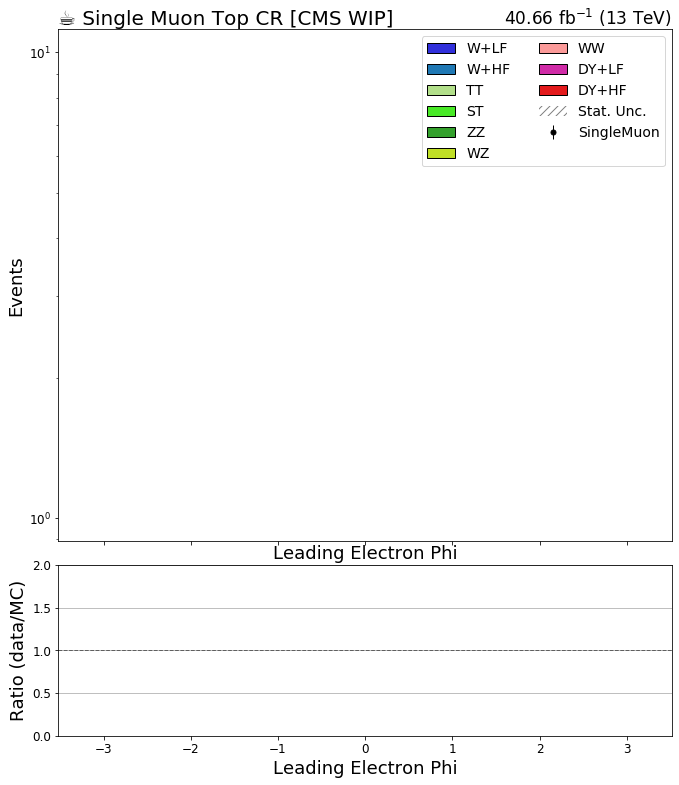

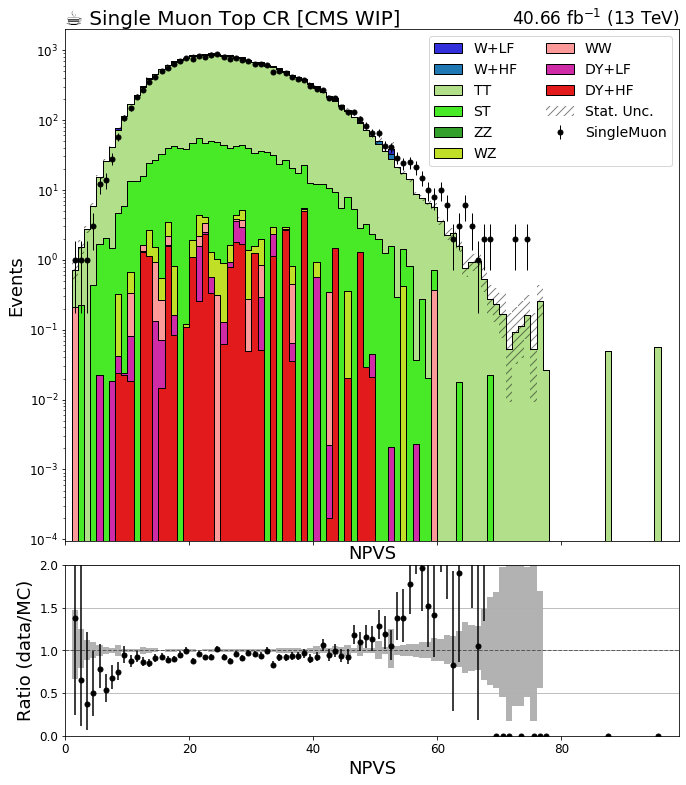

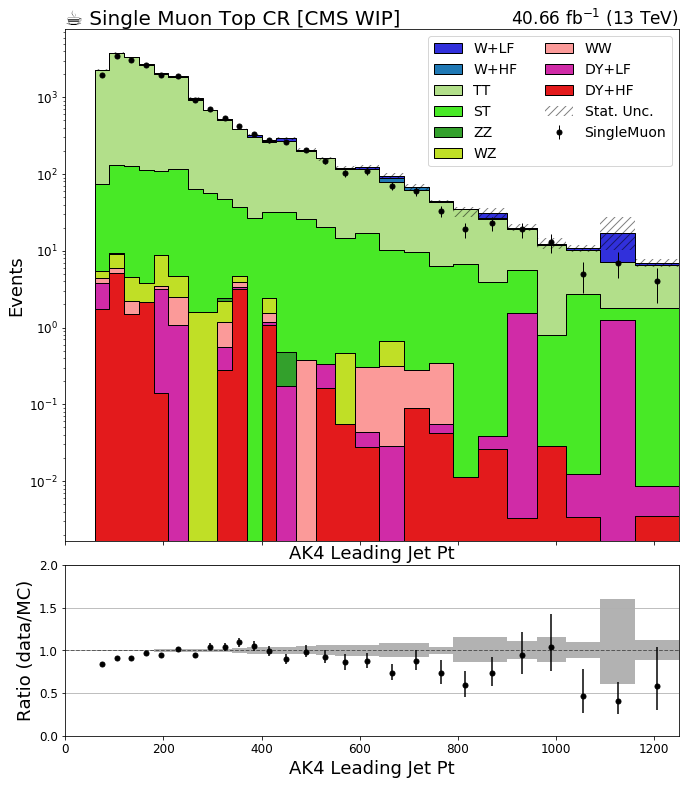

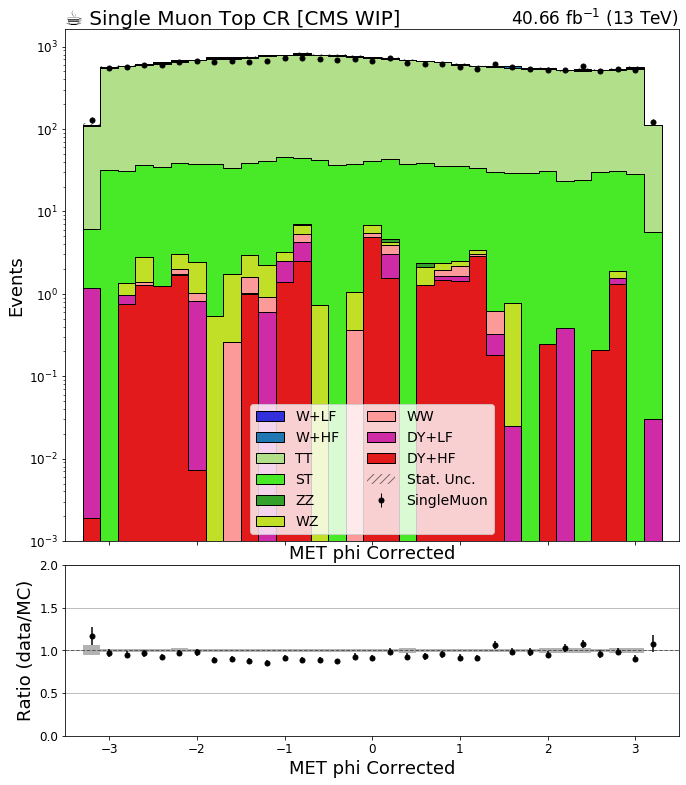

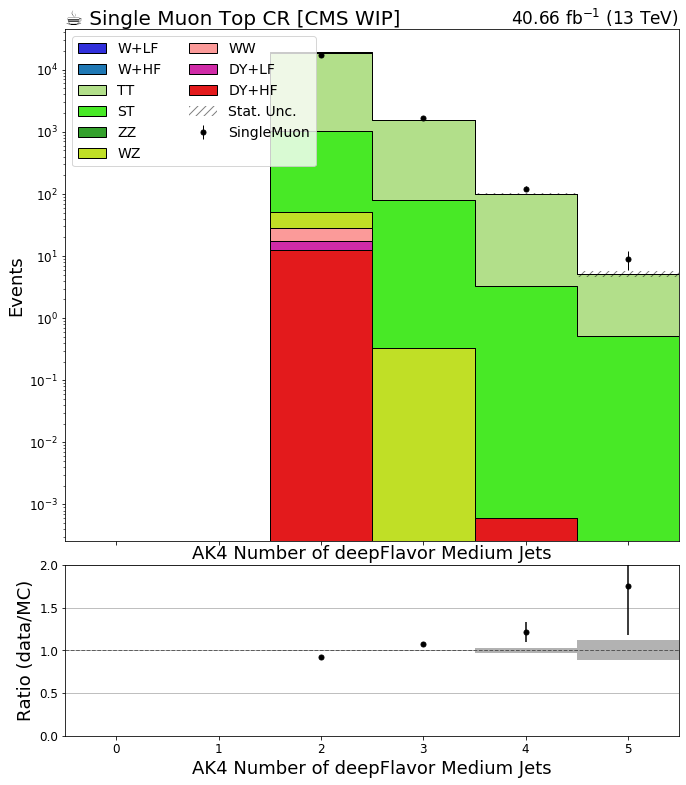

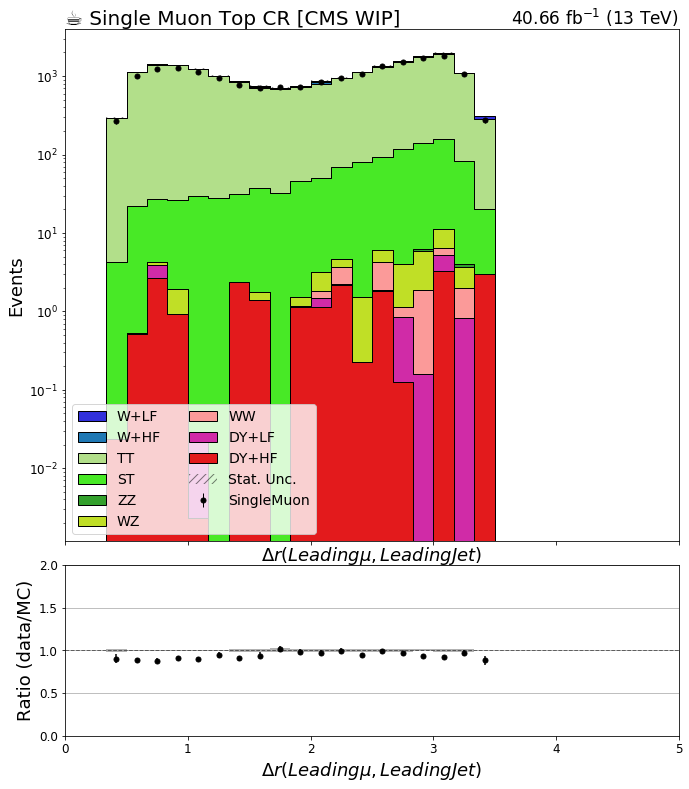

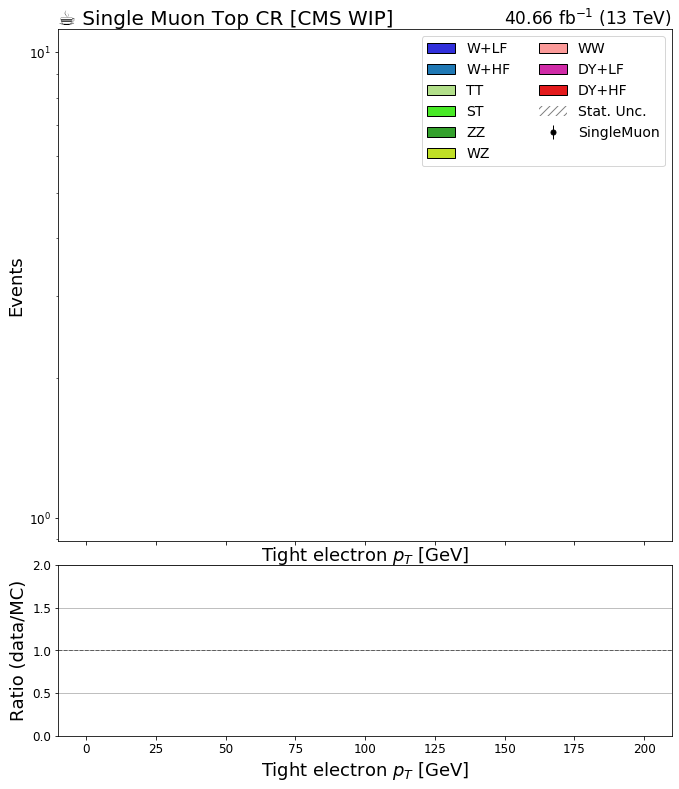

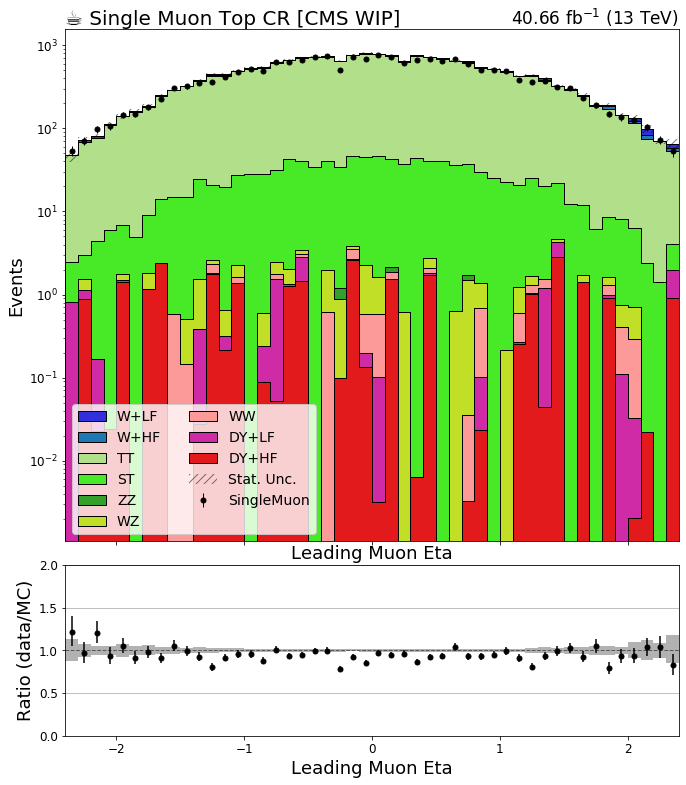

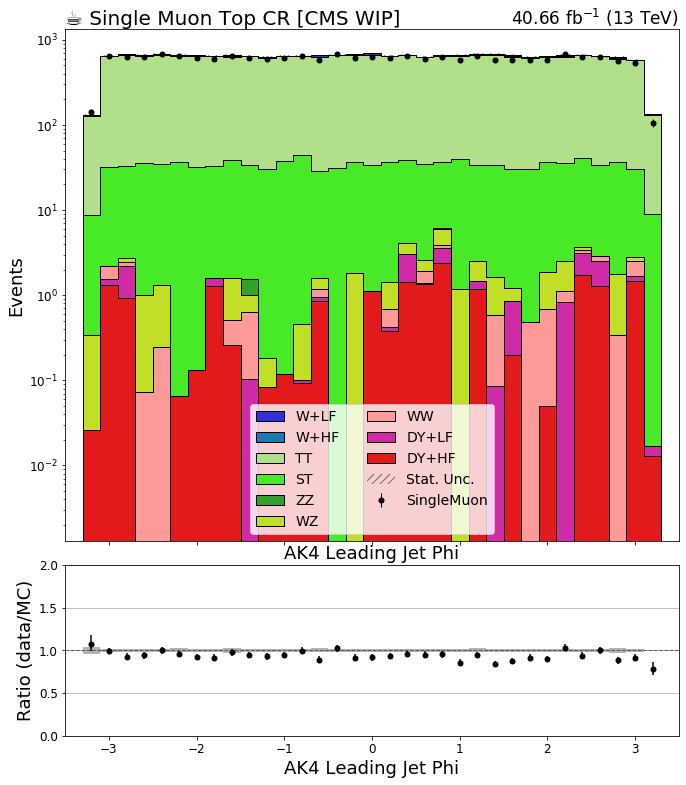

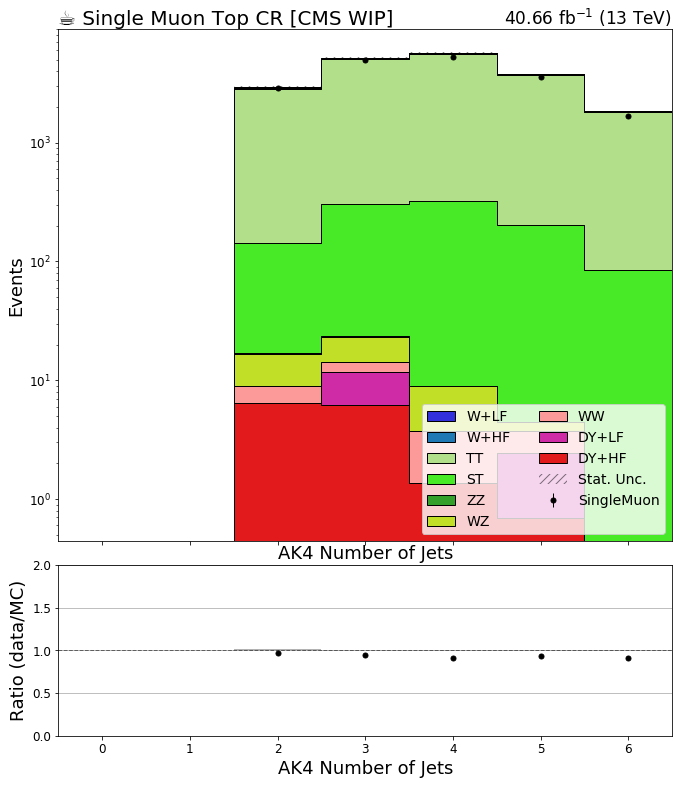

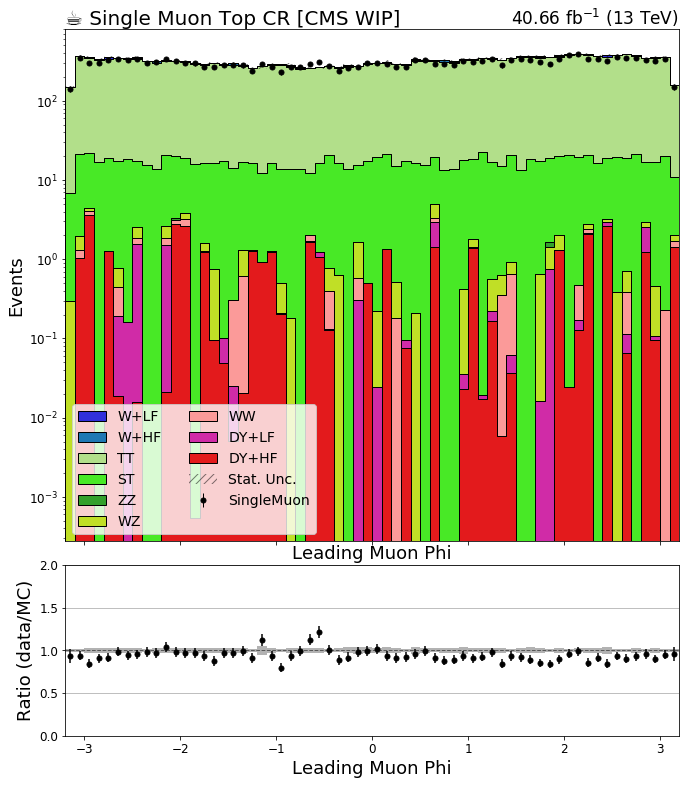

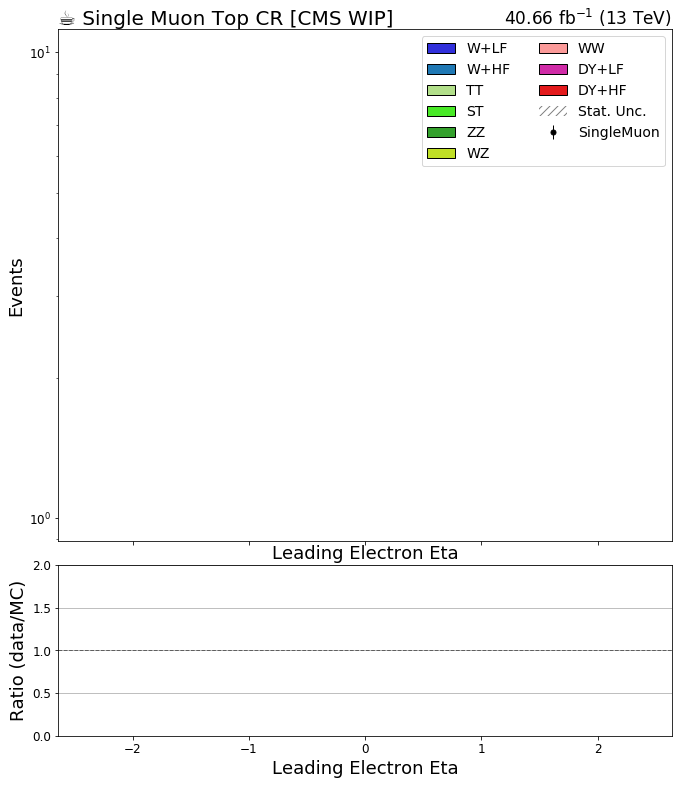

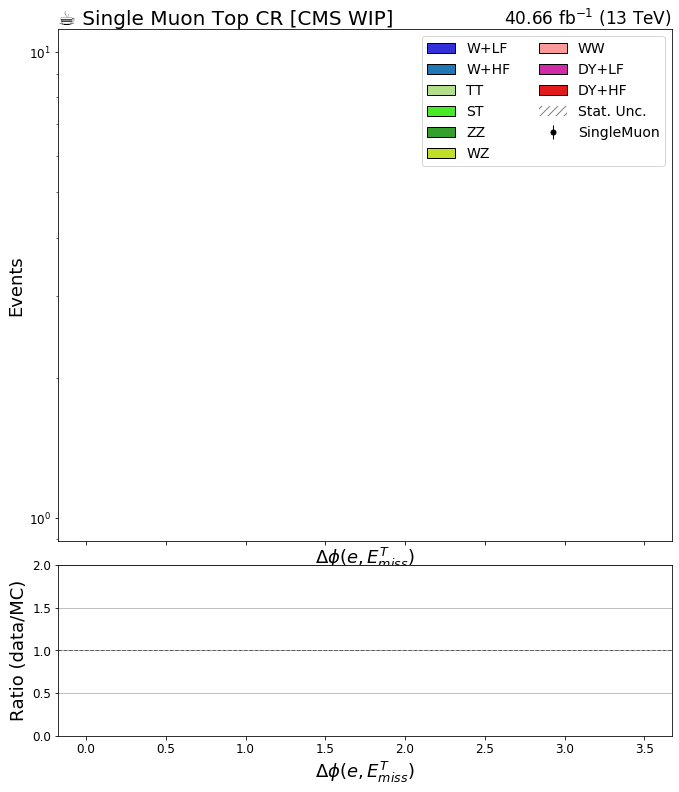

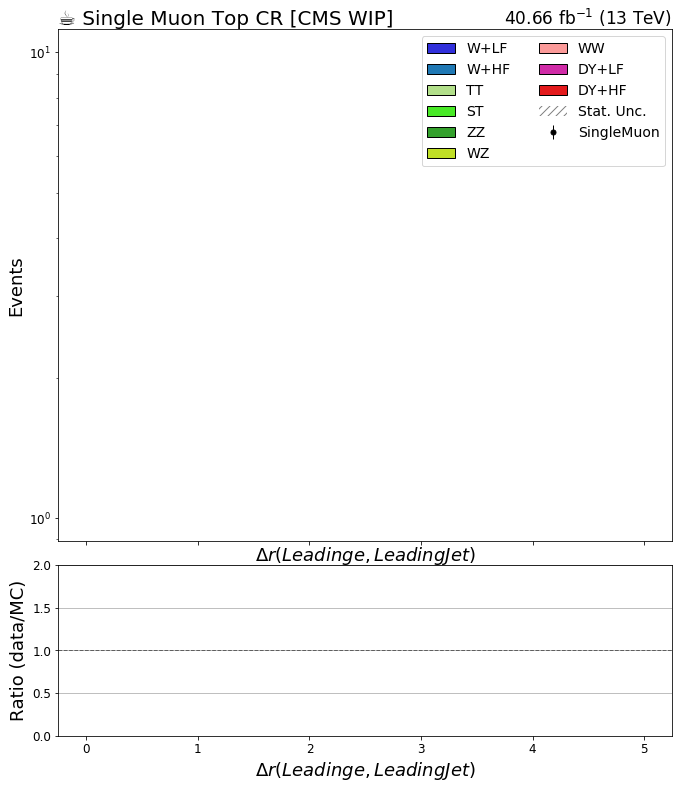

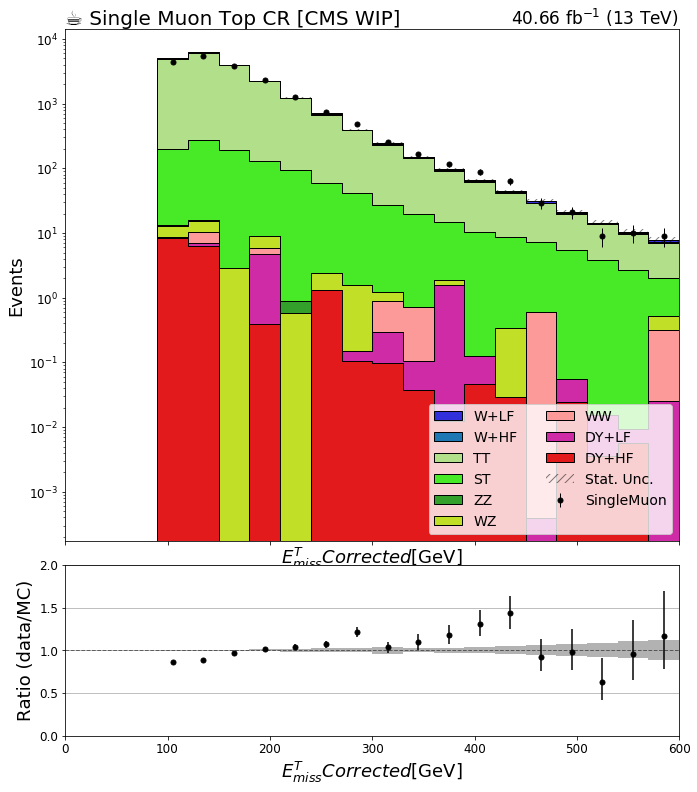

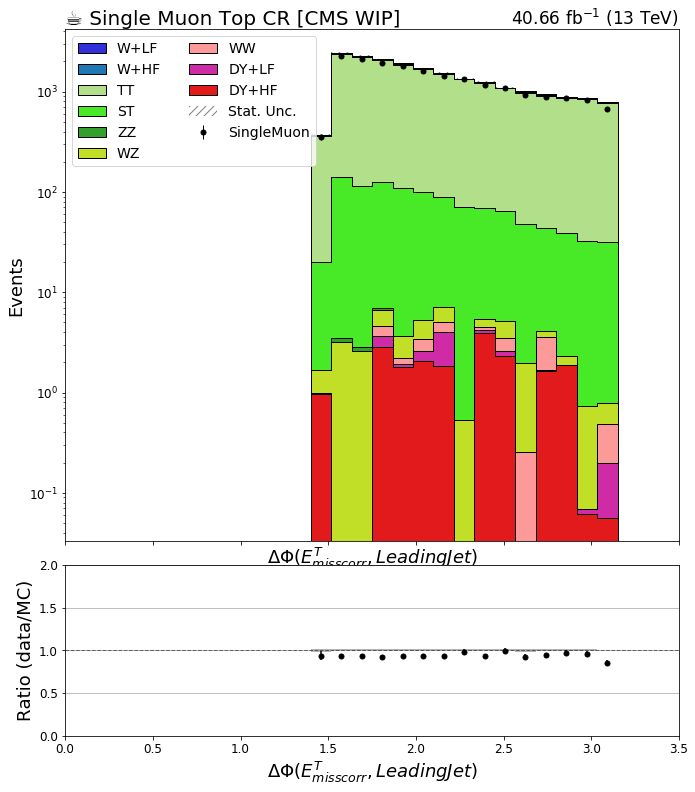

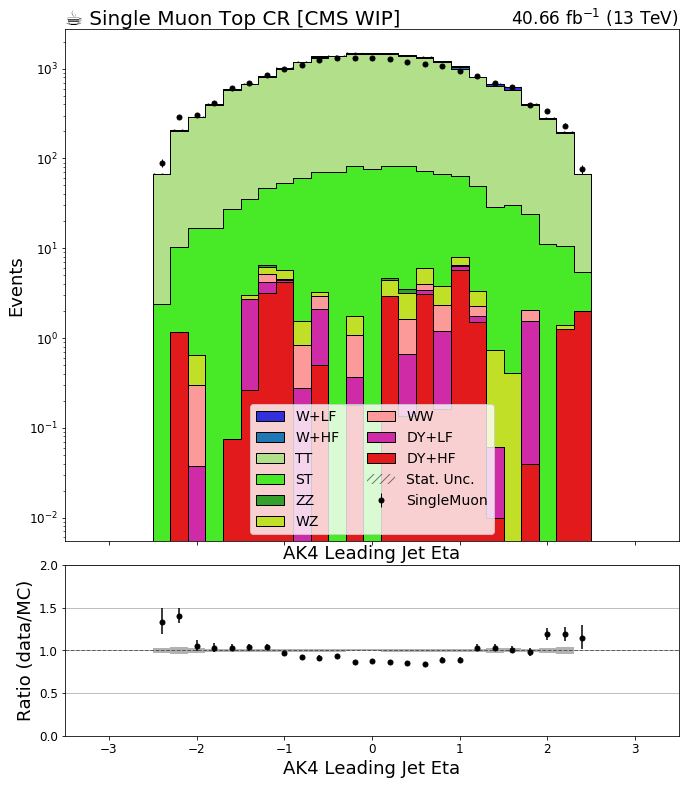

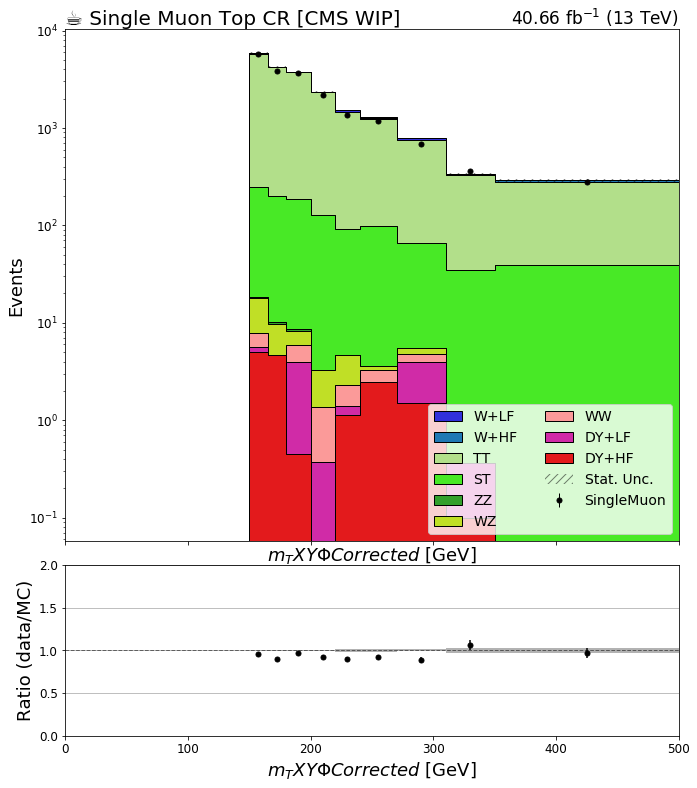

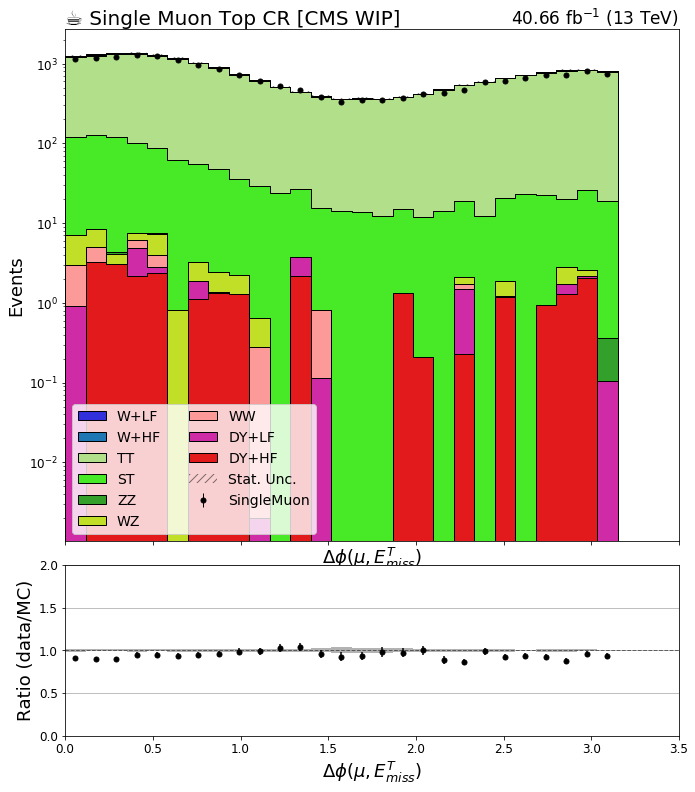

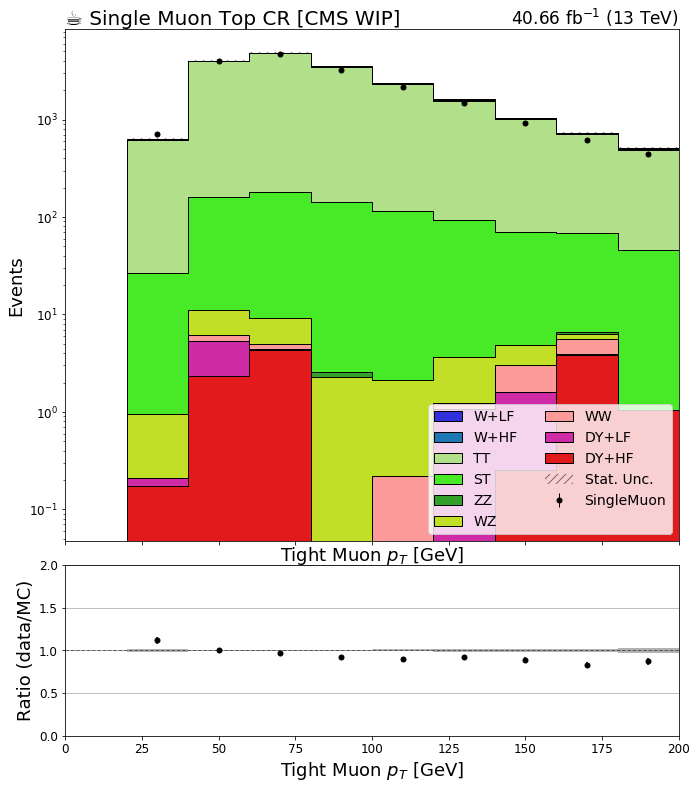

In [14]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2017'
region = 'ttbarm'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if key=='template': continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
#     if 'dphi' in key: continue
#     if key!='mT_corrected': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region) : continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = [ '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate('systematic','nominal').integrate('region',j)[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate('systematic','nominal').integrate('region',j),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate('systematic','nominal').integrate('region',j).integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate('systematic','nominal').integrate('region',j).sum('process'),
                   ax=rax,
#                    overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.,2.)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        if(key=='dilepmass'): ax.set_xlim(50, 130)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]]+ " [CMS WIP]", fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"40.66 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

In [ ]:
data

In [ ]:


from coffea.hist import plot
import matplotlib.pyplot as plt

R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
for _region in bkg_hists['template'].identifiers('region'):
    if not (str(_region) not  in ['sre', 'srm']): continue
    fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 0.2,}
#     legend_opts = {'Process':"hi"}
    error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
    # nostack_fill_opts = {'alpha': 0.2, 'label': 'hi'}
    data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k',  }#, 'elinewidth': 1, 'emarker': '_'}
    bkg_err_opts_up = {'linestyle':'None', 'marker': '+', 'markersize': 5., 'color':'blue', }#, 'elinewidth': 1, 'emarker': '_'}
    bkg_err_opts_down = {'linestyle':'None', 'marker': '*', 'markersize': 5., 'color':'g', }#, 'elinewidth': 1, 'emarker': '_'}
    bkg_err_opts = {'linestyle':'-.', 'marker': 'o', 'markersize': 5., 'color':'pink', }#, 'elinewidth': 1, 'emarker': '_'}

    fig, ax = plt.subplots(1,1, figsize=(10,10))
    #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
    colors = ['#a6cee3', '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                      '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                      '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']

    plot.plot1d(data_hists['template'].integrate('region',_region).integrate('systematic', 'nominal').integrate('mT_corrected')[data['2017'][str(_region)]],            
    #         overlay="process",
            ax=ax,
            clear=False,
            error_opts=data_err_opts,
#                 legend_opts=legend_opts
               )

    plot.plot1d(bkg_hists['template'].integrate('region',_region).integrate('systematic', 'nominal').integrate('mT_corrected').sum('process'),
#                 overlay="process",
                ax=ax,
                clear=False,
    #             stack=True,
    #             fill_opts=fill_opts,
                error_opts=bkg_err_opts,
#                 legend_opts=legend_opts
                   )
    plot.plot1d(bkg_hists['template'].integrate('region',_region).integrate('systematic', 'puUp').integrate('mT_corrected').sum('process'),
    #             overlay="process",
                ax=ax,
                clear=False,
    #             stack=True,
    #             fill_opts=fill_opts,
                error_opts=bkg_err_opts_up
                   )

    plot.plot1d(bkg_hists['template'].integrate('region',_region).integrate('systematic', 'puDown').integrate('mT_corrected').sum('process'),
    #             overlay="process",
                ax=ax,
                clear=False,
    #             stack=True,
    #             fill_opts=fill_opts,
                error_opts=bkg_err_opts_down,
                   )
    ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
    args = {'linestyle':'--', 'linewidth': 5}
    ax.autoscale(axis='x', tight=True)
    ax.set_yscale('log')
    # if(key=='dilepmass'): ax.set_xlim(50, 130)
    ax.set_ylim(.1, None)
    ax.autoscale()
    leg = ax.legend(ncol=1, loc='best')
    coffee = plt.text(0., 1., u"☕ "+R[str(_region).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
    lumi = plt.text(1., 1., r"40.66 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
plt.style.use(hep.style.ROOT)

j = 'wjete'
bins = bkg_hists['template'].integrate('region', j).integrate("systematic","pileupDown").axis("mT_corrected").edges()[()]
data = data_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
down = bkg_hists['template'].integrate('region',j).integrate('systematic', 'pileupDown').integrate('npvs').integrate('process').values()[()]
nom = bkg_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
up = bkg_hists['template'].integrate('region',j).integrate('systematic', 'pileupUp').integrate('npvs').integrate('process').values()[()]

f, ax = plt.subplots(figsize=[10,10])
hep.histplot(data, bins,color='black',histtype='errorbar',
label="Egamma")
hep.histplot(up, bins, color='red',
label="up")
hep.histplot(down, bins, color='green',
label="down")
hep.histplot(nom, bins, color='cyan',histtype='errorbar',
label="nom")
ax.legend()
ax.set_yscale('log')
ax.set_ylabel("counts")
ax.set_xlabel("mT Corrected $[GeV]")
ax.set_title("2017 "+j)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
plt.style.use(hep.style.ROOT)

j = 'wjetm'
bins = bkg_hists['template'].integrate('region', j).integrate("systematic","puDown").axis("mT_corrected").edges()[()]
data = data_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
down = bkg_hists['template'].integrate('region',j).integrate('systematic', 'puDown').integrate('npvs').integrate('process').values()[()]
nom = bkg_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
up = bkg_hists['template'].integrate('region',j).integrate('systematic', 'puUp').integrate('npvs').integrate('process').values()[()]

f, ax = plt.subplots(figsize=[10,10])
hep.histplot(data, bins,color='black',histtype='errorbar',
label="SingleMuon")
hep.histplot(up, bins, color='red',
label="up")
hep.histplot(down, bins, color='green',
label="down")
hep.histplot(nom, bins, color='cyan',histtype='errorbar',
label="nom")
ax.legend()
ax.set_yscale('log')
ax.set_ylabel("counts")
ax.set_xlabel("mT Corrected $[GeV]")
ax.set_title("2017 "+j)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
# plt.style.use(hep.style.ROOT)

j = 'ttbare'
bins = bkg_hists['template'].integrate('region', j).integrate("systematic","puDown").axis("mT_corrected").edges()[()]
data = data_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
down = bkg_hists['template'].integrate('region',j).integrate('systematic', 'puDown').integrate('npvs').integrate('process').values()[()]
nom = bkg_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
up = bkg_hists['template'].integrate('region',j).integrate('systematic', 'puUp').integrate('npvs').integrate('process').values()[()]

f, ax = plt.subplots(figsize=[10,10])
hep.histplot(data, bins,color='black',histtype='errorbar',
label="Egamma")
hep.histplot(up, bins, color='red',
label="up")
hep.histplot(down, bins, color='green',
label="down")
hep.histplot(nom, bins, color='cyan',histtype='errorbar',
label="nom")
ax.legend()
ax.set_yscale('log')
ax.set_ylabel("counts")
ax.set_xlabel("mT Corrected $[GeV]")
ax.set_title("2017 "+j)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
plt.style.use(hep.style.ROOT)

j = 'ttbarm'
bins = bkg_hists['template'].integrate('region', j).integrate("systematic","pileupDown").axis("mT_corrected").edges()[()]
data = data_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
down = bkg_hists['template'].integrate('region',j).integrate('systematic', 'pileupDown').integrate('npvs').integrate('process').values()[()]
nom = bkg_hists['template'].integrate('region',j).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
up = bkg_hists['template'].integrate('region',j).integrate('systematic', 'pileupUp').integrate('npvs').integrate('process').values()[()]

f, ax = plt.subplots(figsize=[10,10])
hep.histplot(data, bins,color='black',histtype='errorbar',
label="Egamma")
hep.histplot(up, bins, color='red',
label="up")
hep.histplot(down, bins, color='green',
label="down")
hep.histplot(nom, bins, color='cyan',histtype='errorbar',
label="nom")
ax.legend()
ax.set_yscale('log')
ax.set_ylabel("counts")
ax.set_xlabel("mT Corrected $[GeV]")
ax.set_title("2017 "+j)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
import re
cr = 'wjetm'
systematics = []
for syst in bkg_hists['template'].integrate('region', cr).identifiers('systematic'):
    if (re.search("Up$", str(syst))):
        systematics.append(str(syst)[:-2])


for sys in systematics:
#     print(sys)
    bins = bkg_hists['template'].integrate('region', cr).integrate("systematic",sys+"Down").axis("mT_corrected").edges()[()]
    data = data_hists['template'].integrate('region',cr).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
    down = bkg_hists['template'].integrate('region',cr).integrate('systematic', sys+'Down').integrate('npvs').integrate('process').values()[()]
    nom = bkg_hists['template'].integrate('region',cr).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
    up = bkg_hists['template'].integrate('region',cr).integrate('systematic', sys+'Up').integrate('npvs').integrate('process').values()[()]
    if "e" in cr[-1]:
        label_data = "EGamma"
    else: label_data = "SingleMuon"
    f, ax = plt.subplots(figsize=[10,10])
    hep.histplot(data, bins,color='black',histtype='errorbar',
    label=label_data)
    hep.histplot(up, bins, color='red',
    label=sys+"up")
    hep.histplot(down, bins, color='green',
    label=sys+"down")
    hep.histplot(nom, bins, color='cyan',histtype='errorbar',
    label="nom")
    ax.legend()
    ax.set_yscale('log')
    ax.set_ylabel("counts")
    ax.set_xlabel("mT Corrected $[GeV]$")
    ax.set_title("2017 "+cr)

In [26]:

def remap_histograms(hists):
    
#     mT_corrected_binning_dict = {
# #     "2018":np.linspace(0, 600, 21),
# #     "2017":np.linspace(0, 600, 21),
# #     "2016":np.linspace(0, 600, 21)
#     "2018": np.array([100.0,125.0,150.0, 165.0, 180.0, 200.0, 220.0, 240.0, 270.0, 310.0, 350.0, 500]),
#     "2017": np.array([100.0,125.0,150.0, 165.0, 180.0, 200.0, 220.0, 240.0, 270.0, 310.0, 350.0, 500]),
#     "2016": np.array([100.0,125.0,150.0, 165.0, 180.0, 200.0, 220.0, 240.0, 270.0, 310.0, 350.0, 500])
# }
    data_hists = {}
    bkg_hists = {}
    signal_hists = {}

    process = hist.Cat("process", "Process", sorting="placement")
    cats = ("process",)
    sig_map = OrderedDict()
    bkg_map = OrderedDict()
    data_map = OrderedDict()
    bkg_map["Hbb"] = ("Hbb*",)
    bkg_map["DY+jets"] = ("DY+*",)
#     bkg_map["DY+HF"] = ("DY+HF",)
#     bkg_map["DY+LF"] = ("DY+LF",)
    bkg_map["VV"] = (["WW", "WZ", "ZZ"],)
#     bkg_map["WW"] = ("WW")
#     bkg_map["WZ"] = ("WZ")
#     bkg_map["ZZ"] = ("ZZ")
    bkg_map["ST"] = ("ST*",)
    bkg_map["TT"] = ("TT*",)
    bkg_map["W+jets"] = ("W+*")
#     bkg_map["W+HF"] = ("W+HF",)
#     bkg_map["W+LF"] = ("W+LF",)
#     bkg_map["Z+jets"] = ("Z+*",)
#     bkg_map["Z+HF"] = ("Z+HF",)
#     bkg_map["Z+LF"] = ("Z+LF",)
#     bkg_map["G+jets"] = ("G+*",)
#     bkg_map["QCD"] = ("QCD*",)
    data_map["SingleElectron"] = ("SingleElectron",)
    data_map["SingleMuon"] = ("SingleMuon",)
    data_map["EGamma"] = ("EGamma",)
    sig_map['Mphi-1000_Mchi-1000'] = ('*Mphi-1000_Mchi-1000*')
    sig_map['Mphi-1000_Mchi-150'] = ('*Mphi-1000_Mchi-150*')
    sig_map['Mphi-1250_Mchi-150'] = ('*Mphi-1250_Mchi-150*')
    sig_map['Mphi-1495_Mchi-750'] = ('*Mphi-1495_Mchi-750*')
    sig_map['Mphi-1500_Mchi-1000'] = ('*Mphi-1500_Mchi-1000*')
    sig_map['Mphi-1500_Mchi-150'] = ('*Mphi-1500_Mchi-150*')
    sig_map['Mphi-1700_Mchi-800'] = ('*Mphi-1700_Mchi-800*')
    sig_map['Mphi-1750_Mchi-150'] = ('*Mphi-1750_Mchi-150*')
    sig_map['Mphi-1750_Mchi-700'] = ('*Mphi-1750_Mchi-700*')
    sig_map['Mphi-195_Mchi-100'] = ('*Mphi-195_Mchi-100*')
    sig_map['Mphi-1995_Mchi-1000'] = ('*Mphi-1995_Mchi-1000*')
    sig_map['Mphi-2000_Mchi-1500'] = ('*Mphi-2000_Mchi-1500*')
    sig_map['Mphi-2000_Mchi-150'] = ('*Mphi-2000_Mchi-150*')
    sig_map['Mphi-2000_Mchi-500'] = ('*Mphi-2000_Mchi-500*')
    sig_map['Mphi-200_Mchi-150'] = ('*Mphi-200_Mchi-150*')
    sig_map['Mphi-200_Mchi-50'] = ('*Mphi-200_Mchi-50*')
    sig_map['Mphi-2495_Mchi-1250'] = ('*Mphi-2495_Mchi-1250*')
    sig_map['Mphi-2500_Mchi-2000'] = ('*Mphi-2500_Mchi-2000*')
    sig_map['Mphi-2500_Mchi-750'] = ('*Mphi-2500_Mchi-750*')
    sig_map['Mphi-295_Mchi-150'] = ('*Mphi-295_Mchi-150*')
    sig_map['Mphi-2995_Mchi-1500'] = ('*Mphi-2995_Mchi-1500*')
    sig_map['Mphi-3000_Mchi-1000'] = ('*Mphi-3000_Mchi-1000*')
    sig_map['Mphi-3000_Mchi-2000'] = ('*Mphi-3000_Mchi-2000*')
    sig_map['Mphi-300_Mchi-100'] = ('*Mphi-300_Mchi-100*')
    sig_map['Mphi-300_Mchi-300'] = ('*Mphi-300_Mchi-300*')
    sig_map['Mphi-495_Mchi-250'] = ('*Mphi-495_Mchi-250*')
    sig_map['Mphi-500_Mchi-150'] = ('*Mphi-500_Mchi-150*')
    sig_map['Mphi-500_Mchi-500'] = ('*Mphi-500_Mchi-500*')
    sig_map['Mphi-750_Mchi-150'] = ('*Mphi-750_Mchi-150*')
    sig_map['Mphi-995_Mchi-500'] = ('*Mphi-995_Mchi-500*')
#     haven't processed signal yet
    for signal in hists['sig']['template'].identifiers('process'):
        if 'mchi' not in str(signal): continue
        sig_map[str(signal)] = (str(signal),)  ## signals

    for key in hists["data"].keys():
        bkg_hists[key] = hists["bkg"][key].group(cats, process, bkg_map)
        signal_hists[key] = hists["sig"][key].group(cats, process, sig_map)
        data_hists[key] = hists["data"][key].group(cats, process, data_map)

    print('initial mT_corrected binning',bkg_hists["template"].axis("mT_corrected").edges())


    bkg_hists["template"] = bkg_hists["template"].rebin(
        "mT_corrected", hist.Bin("mT_corrected", "mT_corrected", mT_corrected_binning)
    )
    signal_hists["template"] = signal_hists["template"].rebin(
        "mT_corrected", hist.Bin("mT_corrected", "mT_corrected", mT_corrected_binning)
    )
    data_hists["template"] = data_hists["template"].rebin(
        "mT_corrected", hist.Bin("mT_corrected", "mT_corrected", mT_corrected_binning)
    )

    hists = {"bkg": bkg_hists, "data": data_hists, "sig":signal_hists}
    print('new mT_corrected binning',bkg_hists["template"].axis("mT_corrected").edges())
    return hists

In [33]:
year = '2017'

mT_corrected_binning_dict = {
    "2018":np.array([120., 150., 180., 210.,  270., 390.,
        510.]),
    "2017":np.array([120., 150., 180., 210.,  270., 390.,
        510.]),
    "2016":np.array([120., 150., 180., 210.,  270., 390.,
        510.])

}
mT_corrected_binning = mT_corrected_binning_dict[year]
mT_correctedbins = np.array(mT_corrected_binning)
nmT_corrected = len(mT_correctedbins) - 1

###
# Extract histograms from input file
###

print("Grouping histograms")
hists = load("../../../hists/UL_lep_monotop_v1_test_" + year + "_HEM.scaled")
hists = remap_histograms(hists)
data_hists = hists["data"]
bkg_hists = hists["bkg"]
signal_hists = hists["sig"]

###
# Preparing histograms for fit
##

# data = {}
# for r in data_hists["template"].identifiers("region"):
#     data[str(r)] = data_hists["template"].integrate("region", r)

# background = {}
# for r in bkg_hists["template"].identifiers("region"):
#     background[str(r)] = bkg_hists["template"].integrate("region", r)

# signal = {}
# for r in signal_hists["template"].identifiers("region"):
#     signal[str(r)] = signal_hists["template"].integrate("region", r)

Grouping histograms
initial mT_corrected binning [120. 150. 180. 210. 240. 270. 300. 330. 360. 390. 420. 450. 480. 510.
 540. 570. 600.]
new mT_corrected binning [120. 150. 180. 210. 270. 390. 510.]


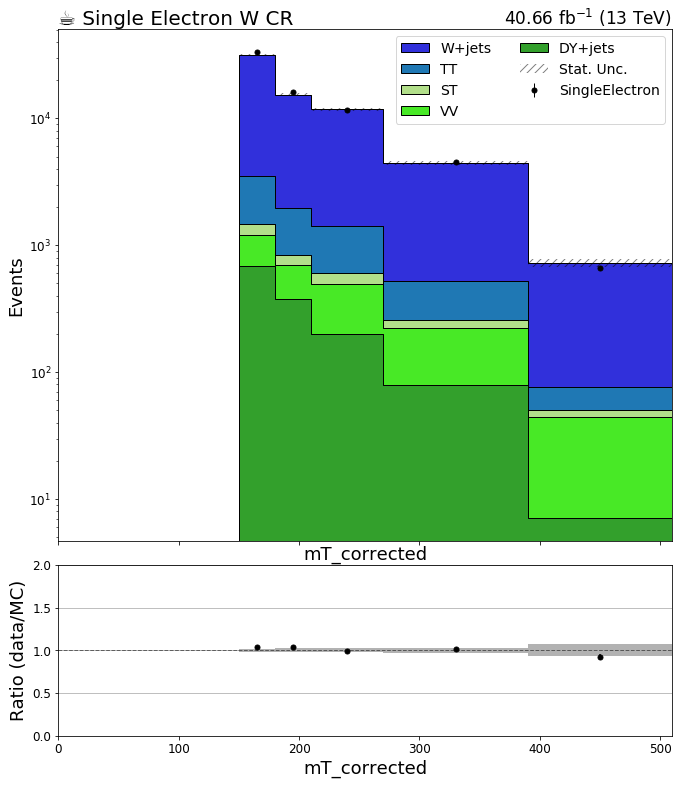

In [34]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2017'
region = 'wjete'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if 'template' not in key: continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
#     if 'mT_corrected' not in key:continue
    #if key!='fjmass': continue
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = [ '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']


        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
       
        plot.plot1d(data_hists[key].integrate("systematic", sys).integrate('region',j).integrate('npvs')[data[year][str(j)]],            
                overlay="process",
                ax=ax,
                clear=False,
                error_opts=data_err_opts
                   )

        plot.plot1d(bkg_hists[key].integrate("systematic", sys).integrate('region',j).integrate('npvs'),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )
        
        plot.plotratio(data_hists[key].integrate("systematic", sys).integrate('region',j).integrate('npvs').integrate('process',data[year][str(j)]), 
                   bkg_hists[key].integrate("systematic", sys).integrate('region',j).integrate('npvs').sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
        ax.set_xlim(100, 600)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')
        
        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]], fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"40.66 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
#         os.system('mkdir -p ../plots/leptonic_preVFP'+year+'/'+str(j)+'/')
#         plot_path = os.path.abspath('../plots/leptonic_preVFP'+year+'/'+str(j)+'/') 
#         plot_name = 'stack_'+key+'.png'
#         fig.savefig(os.path.join(plot_path, plot_name))

In [34]:
bkg_hists['template'].integrate('region', 'wjete').integrate("systematic",sys+"Down").axis("mT_corrected").edges()[()]

array([120., 150., 180., 210., 270., 390., 510.])

DY+jets
nom:  [   0.         1448.98655603  631.76003241  397.55113637  151.35355103
   15.73471517]
sumw2:  [   0.         2875.43345607 1179.19620536  714.55887257  183.67281603
   17.93610032]
sqrtsumw2:  [ 0.         53.62306832 34.3394264  26.73123403 13.55259444  4.23510334]

VV
nom:  [  0.         751.76790769 372.03710384 324.14854774 162.62197212
  39.15967727]
sumw2:  [  0.         228.65745575 112.10220408  97.86361712  48.53098402
  11.83424804]
sqrtsumw2:  [ 0.         15.12142373 10.58783283  9.89260416  6.96641831  3.44009419]

ST
nom:  [  0.         361.06769402 177.56444278 148.03936317  44.50098786
   6.35697095]
sumw2:  [ 0.         88.39716733 43.4478772  35.95074619 10.50495478  1.54542167]
sqrtsumw2:  [0.         9.40197678 6.59150038 5.99589411 3.2411348  1.2431499 ]

TT
nom:  [   0.         2864.27493164 1419.47347807  982.06089686  295.35929154
   25.16383121]
sumw2:  [  0.         113.21076594  55.43143234  37.568169    11.02722457
   0.95509333]
sqrtsumw2:  [

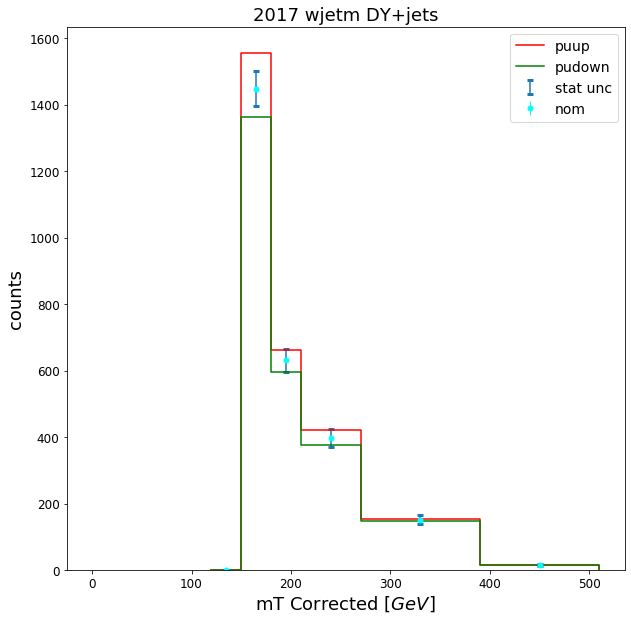

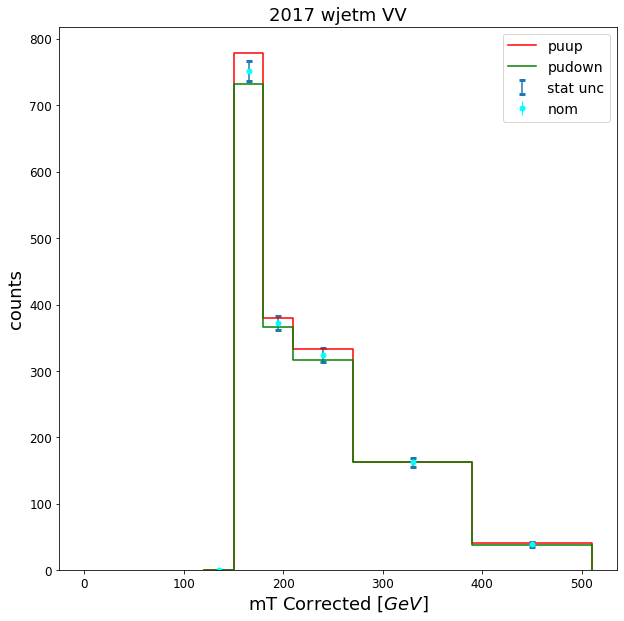

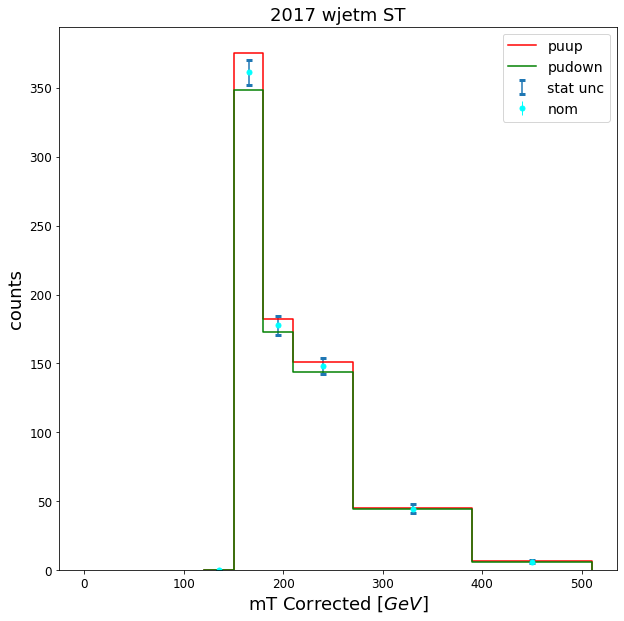

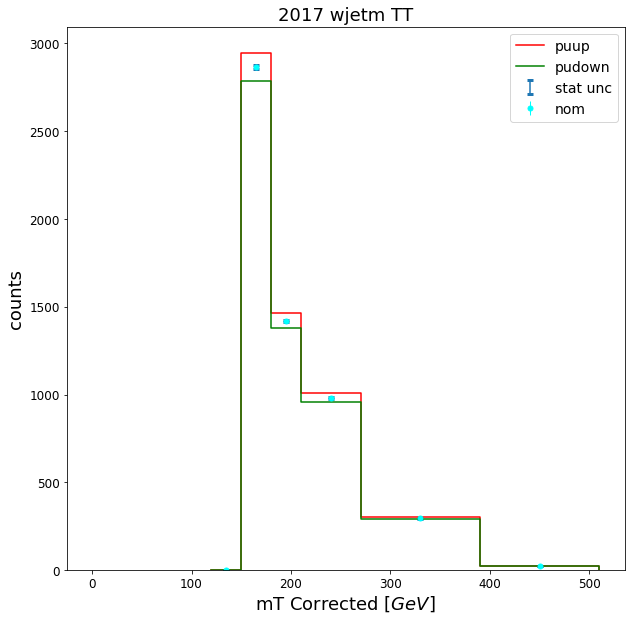

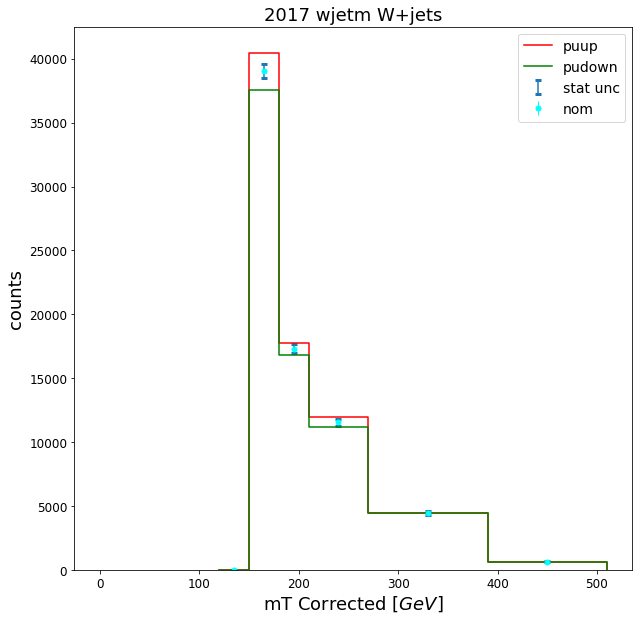

In [44]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
import re
cr = 'wjetm'
# p ='DY+jets'
for p in bkg_hists['template'].integrate("region", cr).identifiers('process'):
    systematics = []
#     if "TT" not in str(p): continue
    for syst in bkg_hists['template'].integrate('region', cr).integrate('process', p).identifiers('systematic'):
        if (re.search("Up$", str(syst))):
            systematics.append(str(syst)[:-2])
    # sys = 'pu'


    for sys in systematics:
        if ("pu" in sys):pass
#         elif ("JES" in sys):pass
#         elif ("JER" in sys):pass
#         elif ("METuncl" in sys): pass
        else: continue
        bins = bkg_hists['template'].integrate('region', cr).integrate("systematic",sys+"Down").axis("mT_corrected").edges()[()]
        down = bkg_hists['template'].integrate('region',cr).integrate('systematic', sys+'Down').integrate('process',p).integrate('npvs').values()[()]
        nom, sumw2 = bkg_hists['template'].integrate('region',cr).integrate('systematic', 'nominal').integrate('process',p).integrate('npvs').values(sumw2=True)[()]
        up = bkg_hists['template'].integrate('region',cr).integrate('systematic', sys+'Up').integrate('process',p).integrate('npvs').values()[()]
#         data = data_hists['template'].integrate('region',cr).integrate('systematic', 'nominal').integrate('npvs').integrate('process').values()[()]
        bins_ = [135, 165, 195, 240, 330, 450]
        print(p)
        print("nom: ",nom)
        print("sumw2: ",sumw2)
        print("sqrtsumw2: ",np.sqrt(sumw2))
        print()
        if "e" in cr[-1]:
            label_data = "EGamma"
        else: label_data = "SingleMuon"
        f, ax = plt.subplots(figsize=[10,10])
#         hep.histplot(data, bins,color='black',histtype='errorbar',
#         label=label_data)
        plt.errorbar(bins_, nom, yerr=np.sqrt(sumw2), label='stat unc',  ls='none',capsize=3, capthick=3)
        hep.histplot(up, bins, color='red',
        label=sys+"up")
        hep.histplot(down, bins, color='green',
        label=sys+"down")
        hep.histplot(nom, bins, color='cyan',histtype='errorbar',
        label="nom")
        ax.legend()
#         ax.set_yscale('log')
        ax.set_ylabel("counts")
        ax.set_xlabel("mT Corrected $[GeV]$")
        ax.set_title("2017 "+cr+" "+str(p))

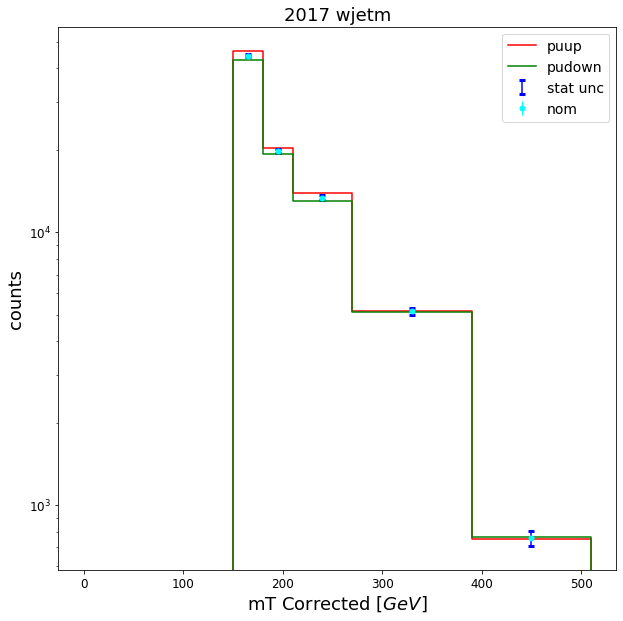

In [40]:
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep
import re
cr = 'wjetm'
# p ='DY+jets'
for p in bkg_hists['template'].integrate("region", cr).identifiers('process'):
    systematics = []
    for syst in bkg_hists['template'].integrate('region', cr).integrate('process', p).identifiers('systematic'):
        if (re.search("Up$", str(syst))):
            systematics.append(str(syst)[:-2])
    # sys = 'pu'


for sys in systematics:
    if ("pu" in sys):pass
#         elif ("JES" in sys):pass
    else: continue
    bins = bkg_hists['template'].integrate('region', cr).integrate("systematic",sys+"Down").axis("mT_corrected").edges()[()]
    down = bkg_hists['template'].integrate('region',cr).integrate('systematic', sys+'Down').integrate('process',).integrate('npvs').values()[()]
    nom, sumw2 = bkg_hists['template'].integrate('region',cr).integrate('systematic', 'nominal').integrate('process',).integrate('npvs').values(sumw2=True)[()]
    up = bkg_hists['template'].integrate('region',cr).integrate('systematic', sys+'Up').integrate('process',).integrate('npvs').values()[()]
    if "e" in cr[-1]:
        label_data = "EGamma"
    else: label_data = "SingleMuon"
        
    bins_ = [135, 165, 195, 240, 330, 450]
    f, ax = plt.subplots(figsize=[10,10])
#     hep.histplot(data, bins,color='black',histtype='errorbar',
#     label=label_data)
    hep.histplot(up, bins, color='red',
    label=sys+"up")
    plt.errorbar(bins_, nom, yerr=np.sqrt(sumw2), label='stat unc',  ls='none',capsize=3, capthick=3, ecolor="blue")
    hep.histplot(down, bins, color='green',
    label=sys+"down")
    hep.histplot(nom, bins, color='cyan',histtype='errorbar',
    label="nom")
    ax.legend()
    ax.set_yscale('log')
    ax.set_ylabel("counts")
    ax.set_xlabel("mT Corrected $[GeV]$")
    ax.set_title("2017 "+cr)

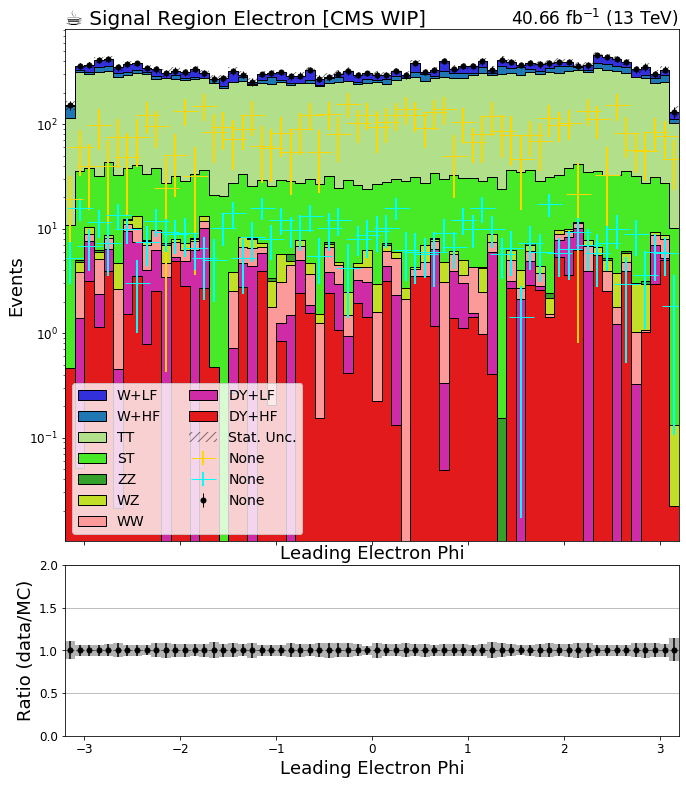

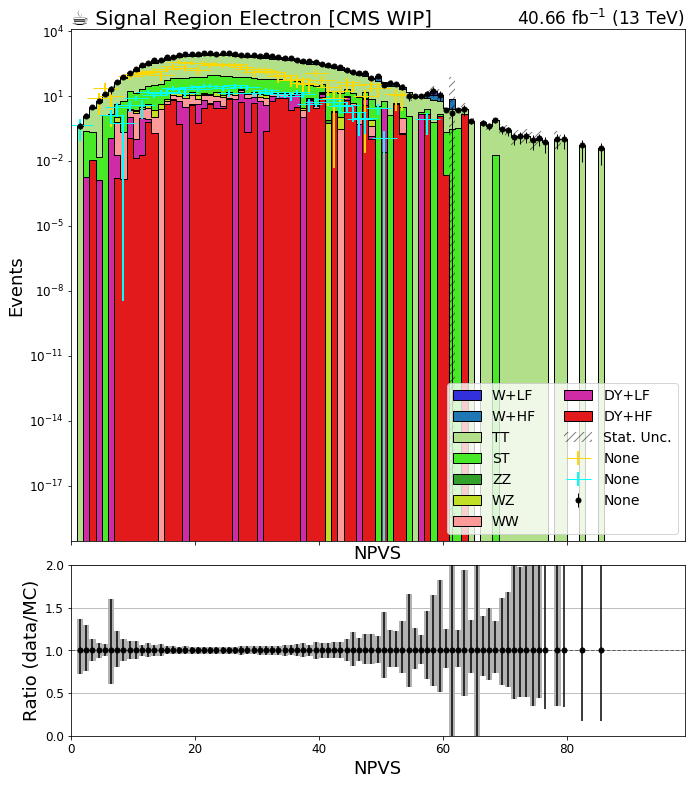

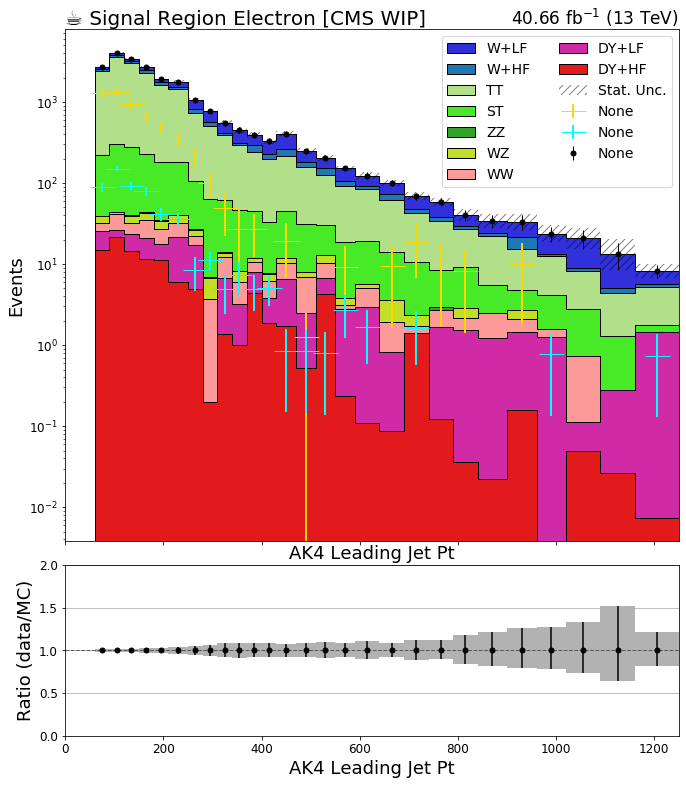

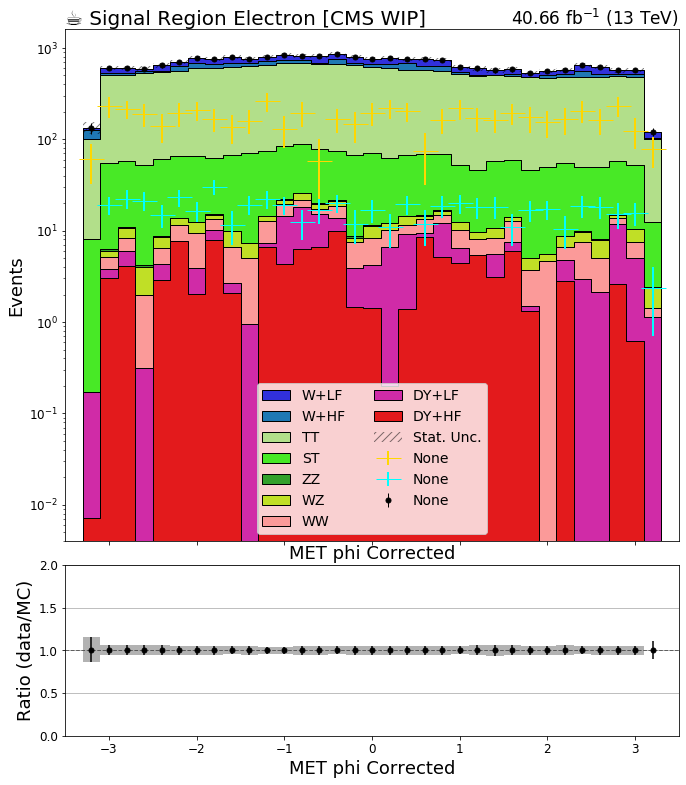

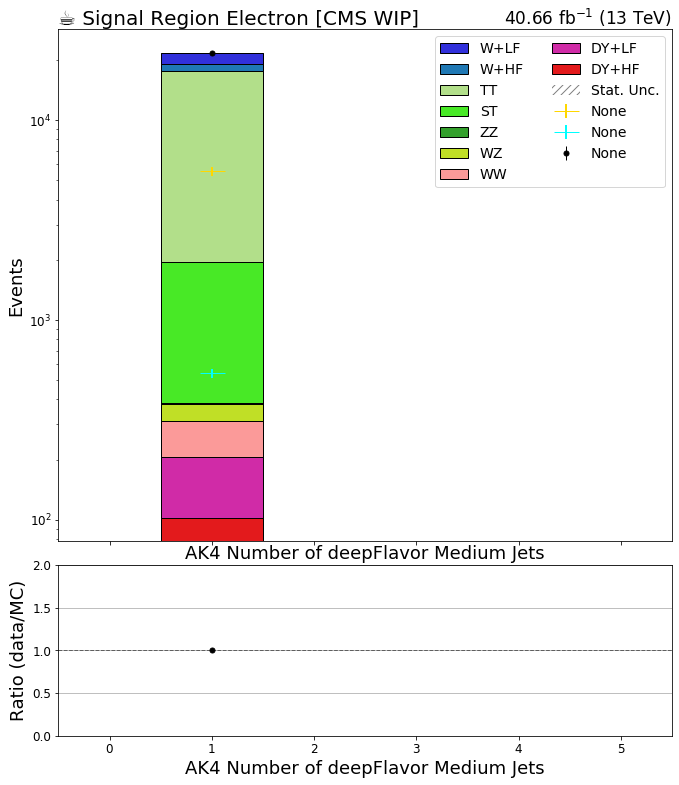

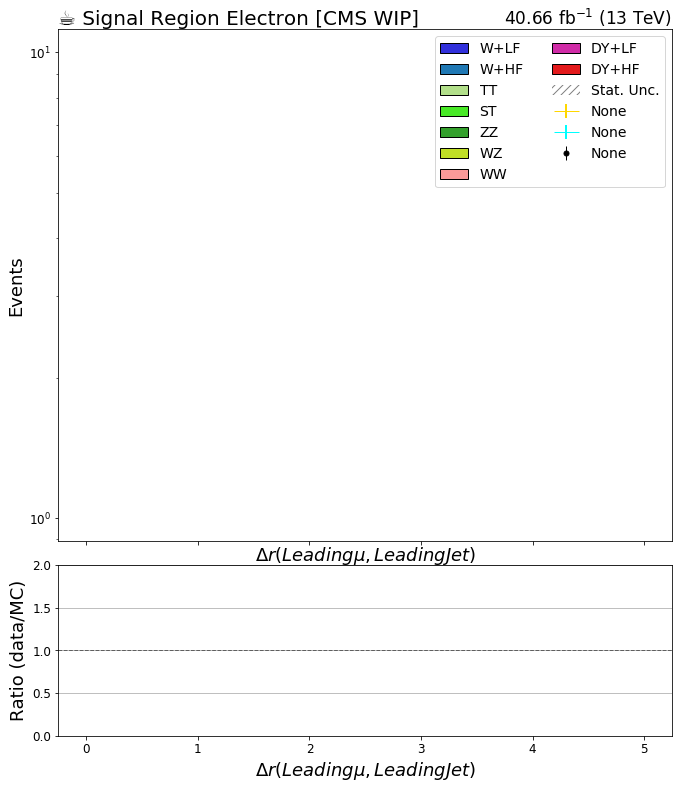

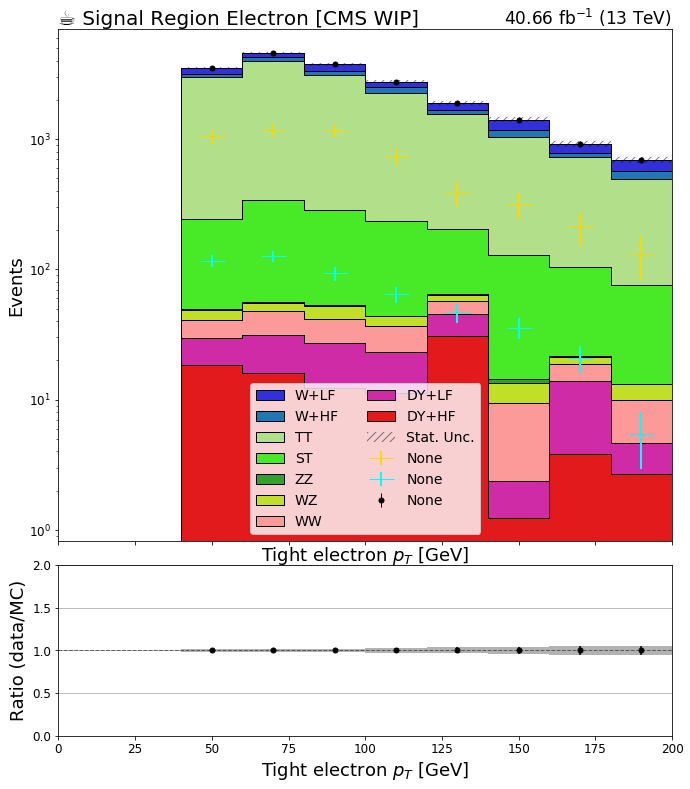

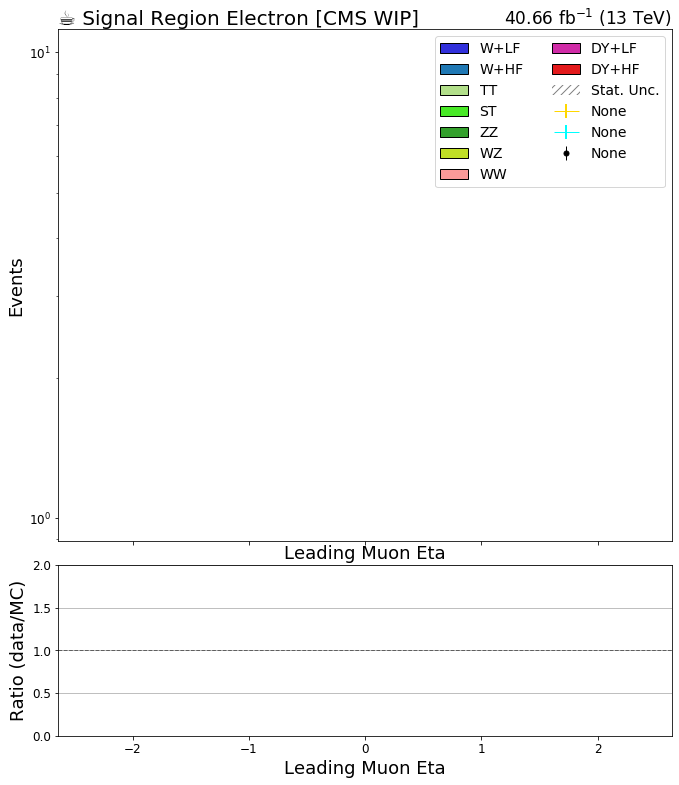

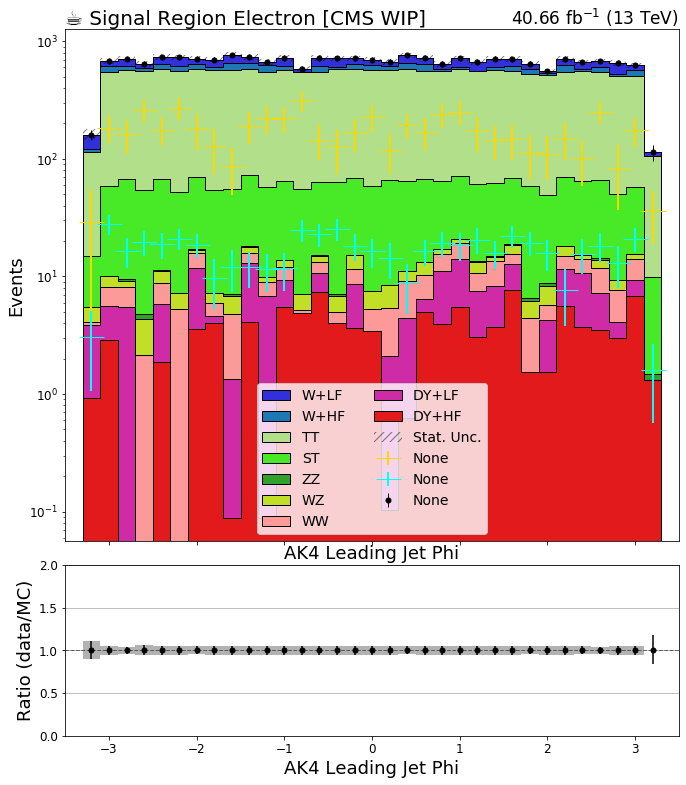

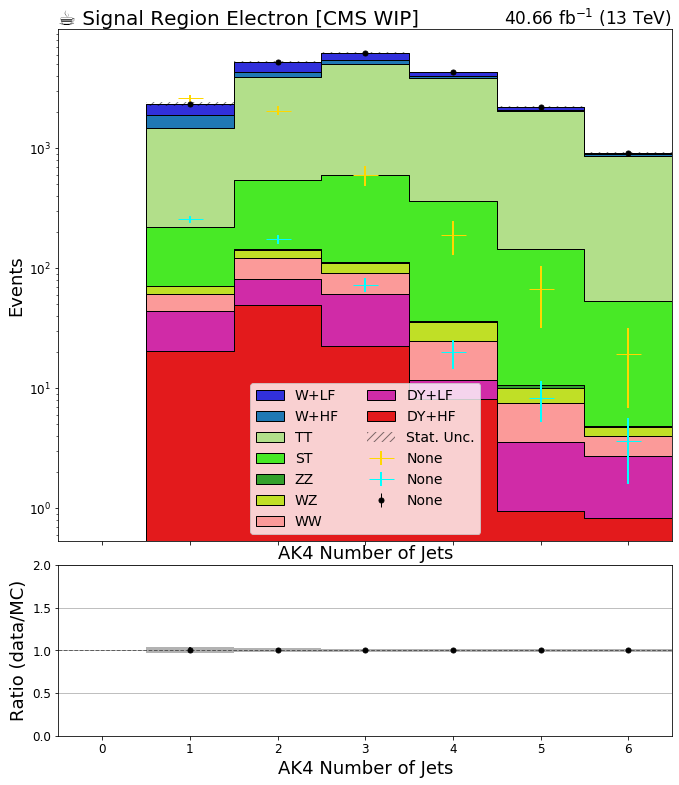

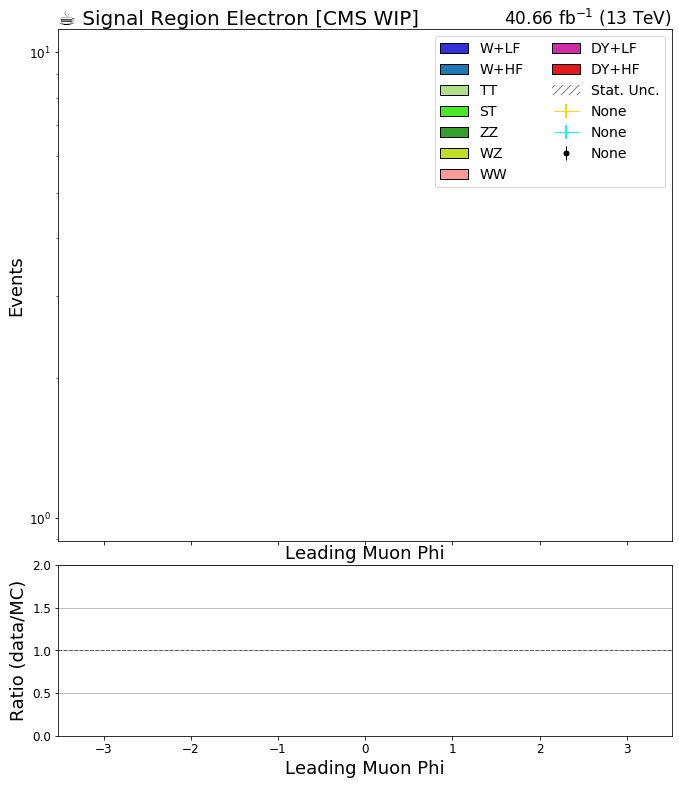

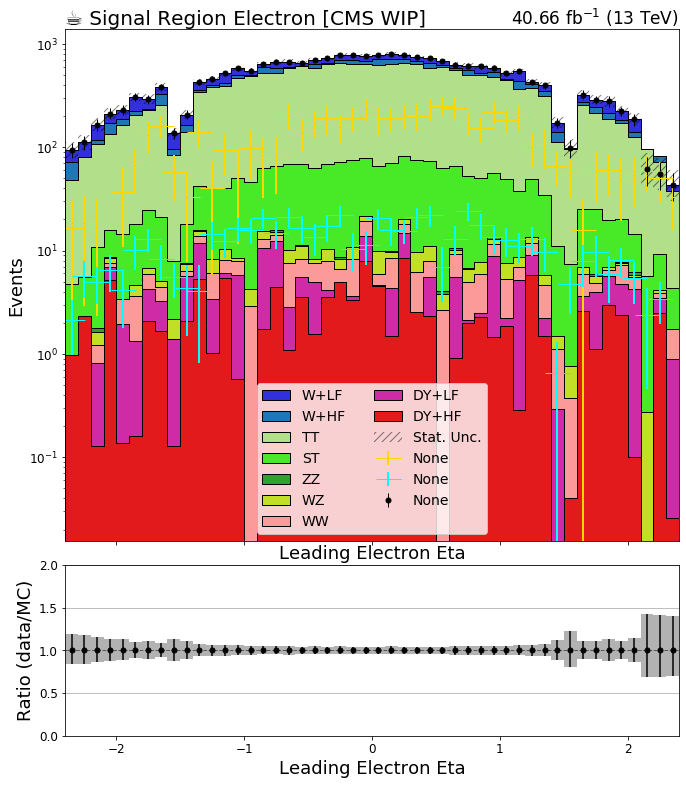

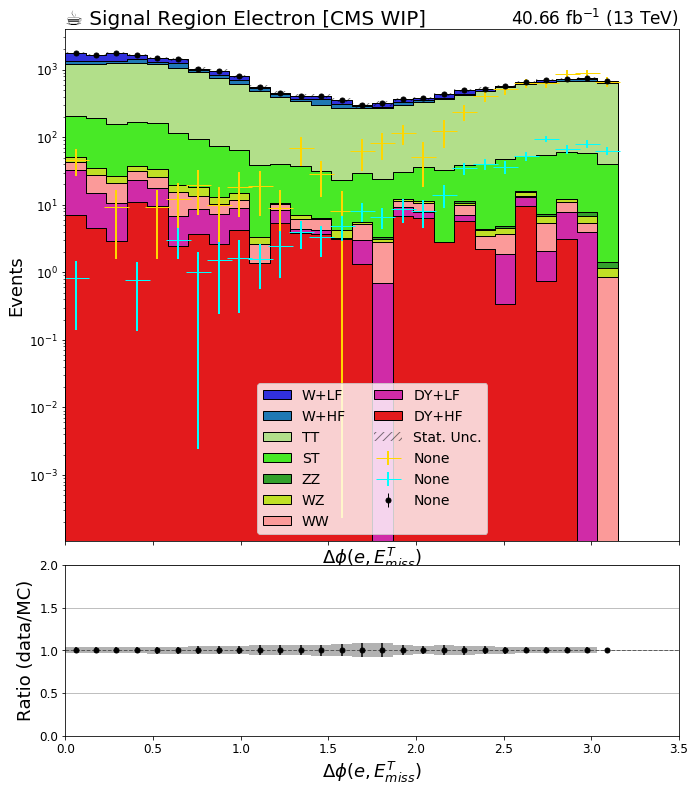

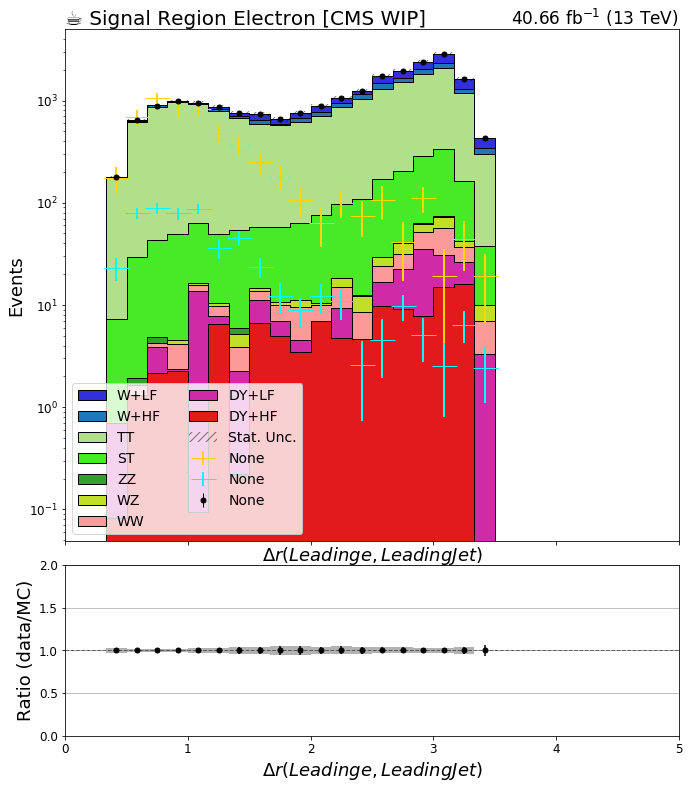

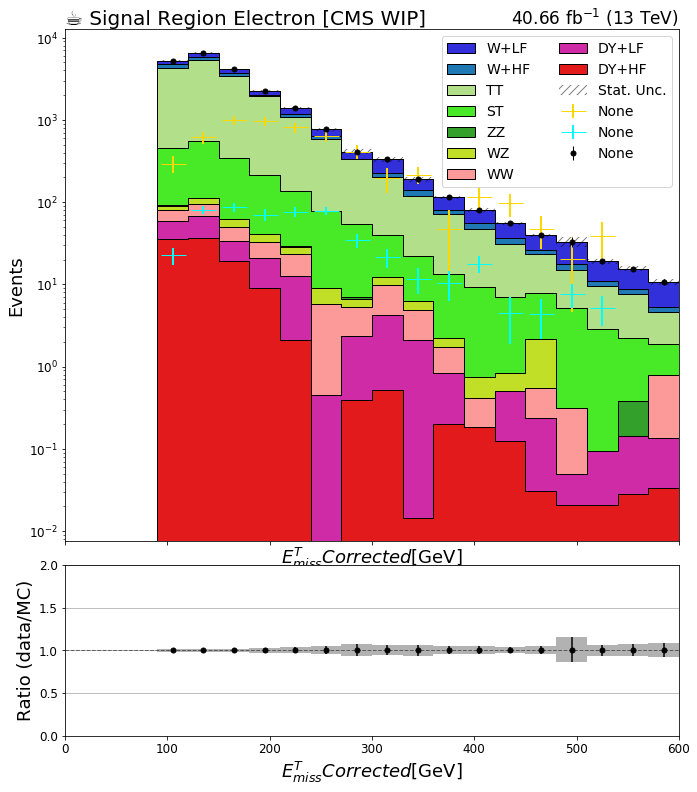

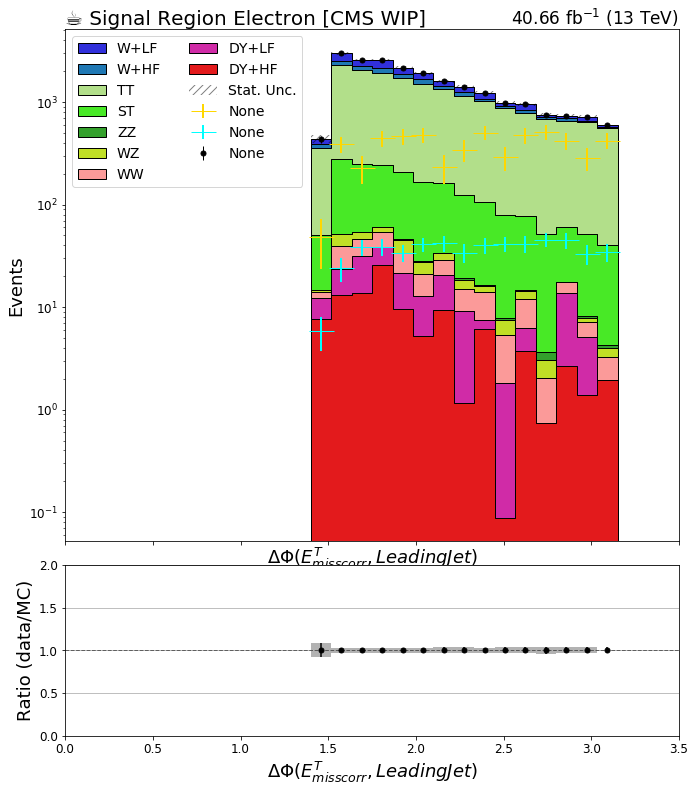

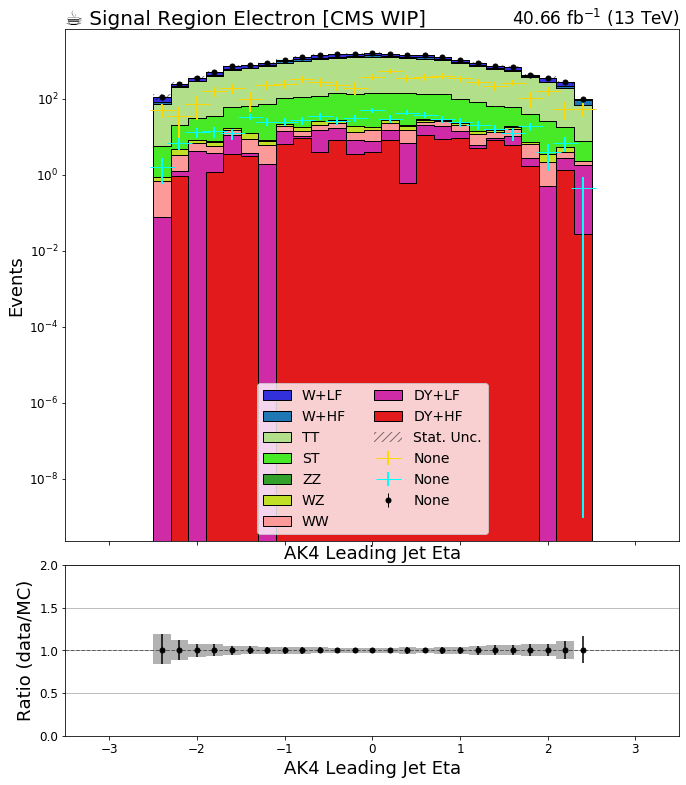

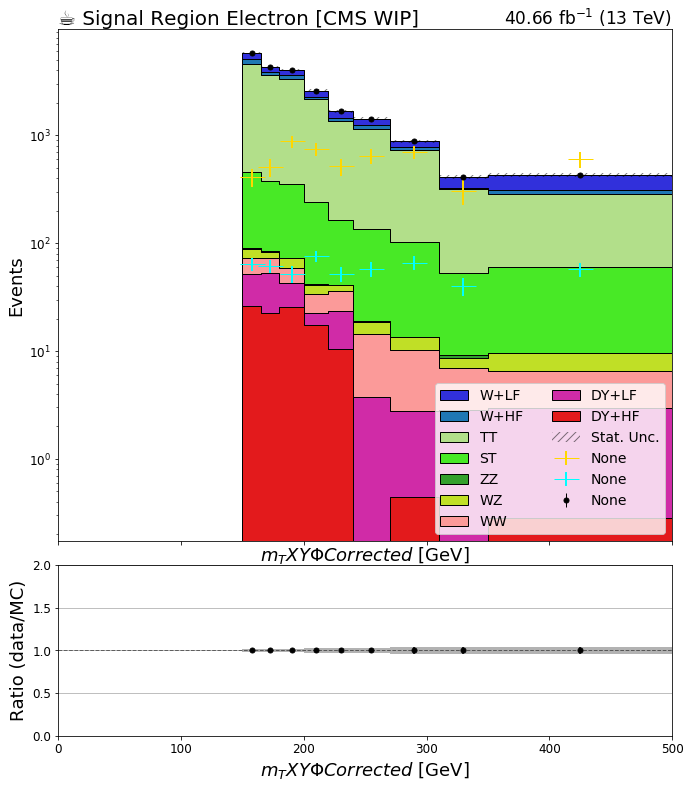

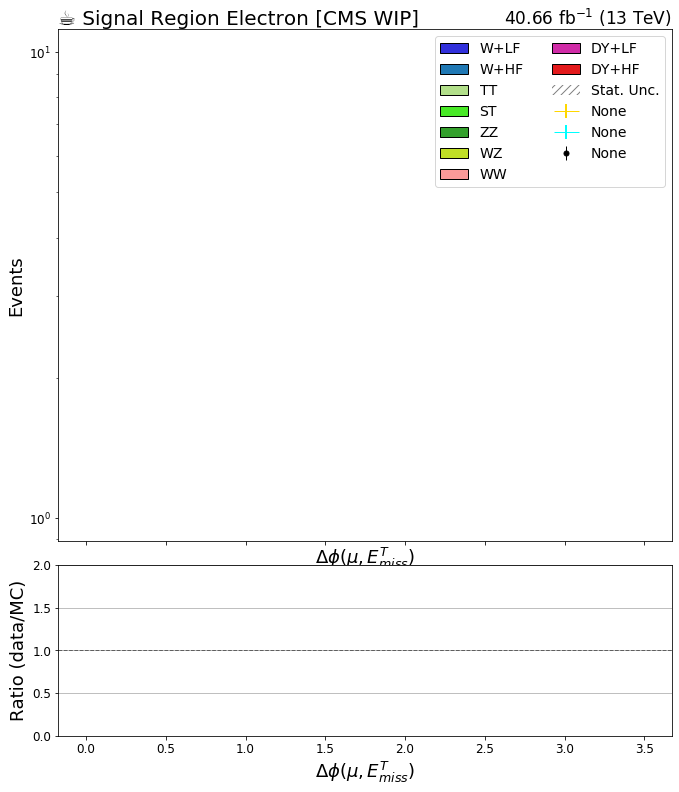

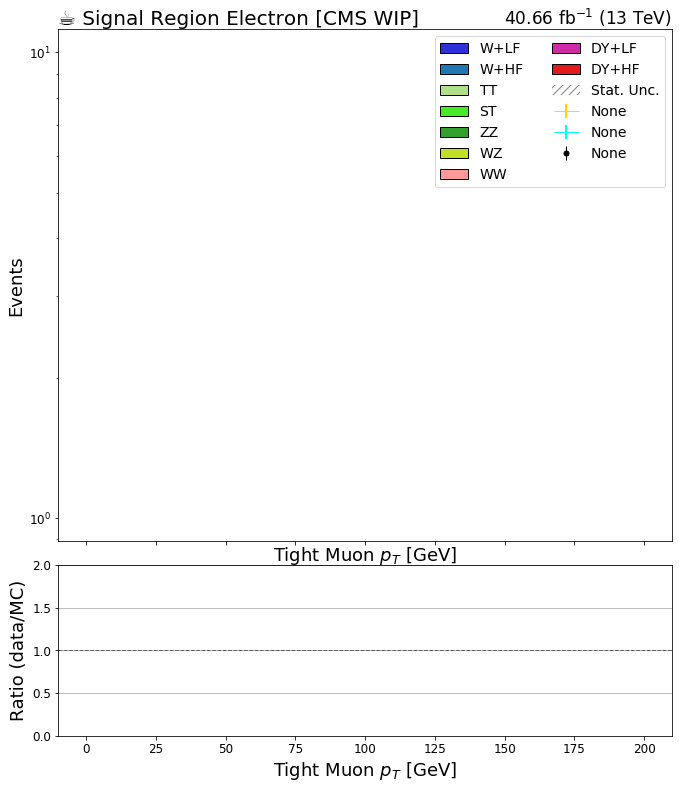

In [15]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2017'
region = 'sre'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if 'template'  in key: continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
#     if 'mT_corrected' not in key:continue
    #if key!='fjmass': continue
#     print(key)
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = [ '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']
        test_err_opts1 = {'marker': '_', 'markersize': 25., 'color':'gold', 'elinewidth': 2 }#, 'elinewidth': 1, 'emarker': '_'}
        fill_opts_tesst = {'edgecolor': (0,0,0,0.3)}
        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
        
        test_err_opts2 = {'marker': '_', 'markersize': 25., 'color':'cyan', 'elinewidth': 2 }#, 'elinewidth': 1, 'emarker': '_'}

#         bins = bkg_hists[key].integrate('region', cr).integrate("systematic",sys).axis("mT_corrected").edges()[()]
        mphi200_Mchi50 = signal_hists[key].integrate('region',j).integrate('systematic', 'nominal').integrate('process','Mphi-200_Mchi-50')
        plot.plot1d(mphi200_Mchi50,          
#                 overlay="process",
#                     label='pseudo',
                    stack=False,
                    ax=ax, 
                    error_opts=test_err_opts1,
                    clear=False,            
           )
        mphi195_Mchi100 = signal_hists[key].integrate('region',j).integrate('systematic', 'nominal').integrate('process','Mphi-195_Mchi-100')
        plot.plot1d(mphi195_Mchi100,          
#                 overlay="process",
#                     label='pseudo',
                    stack=False,
                    ax=ax, 
                    error_opts=test_err_opts2,
                    clear=False,            
           )        
        
        plot.plot1d(bkg_hists[key].integrate("systematic", sys).integrate('region',j).integrate('process'),            
#                 overlay="process",
#                     label='pseudo',
                ax=ax,
                clear=False,
                error_opts=data_err_opts, 
                   )

        plot.plot1d(bkg_hists[key].integrate("systematic", sys).integrate('region',j),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )

        plot.plotratio(bkg_hists[key].integrate("systematic", sys).integrate('region',j).integrate('process'), 
                   bkg_hists[key].integrate("systematic", sys).integrate('region',j).sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
#         if(key=='mT_corrected'): plt.set_xlim(150, None)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')



        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]]+ " [CMS WIP]", fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"40.66 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))

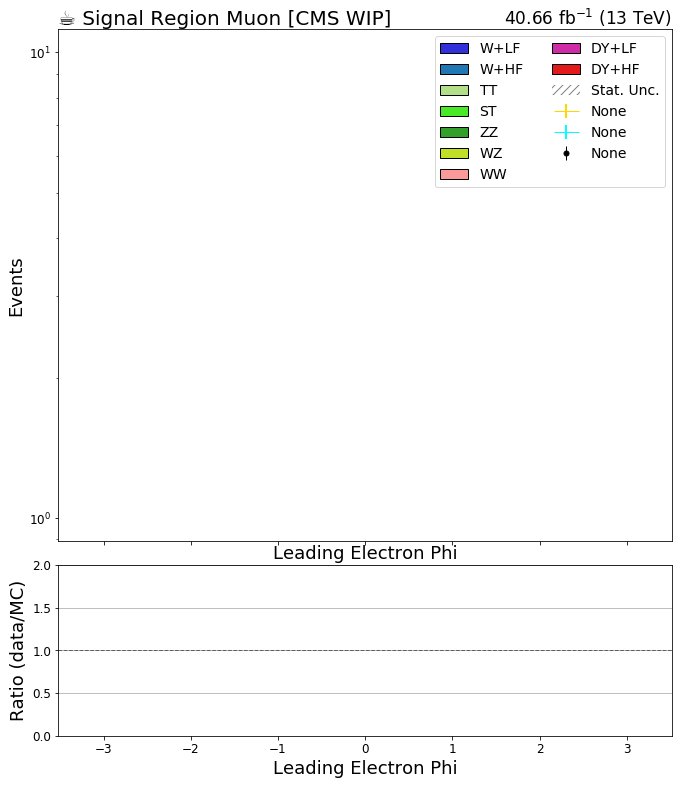

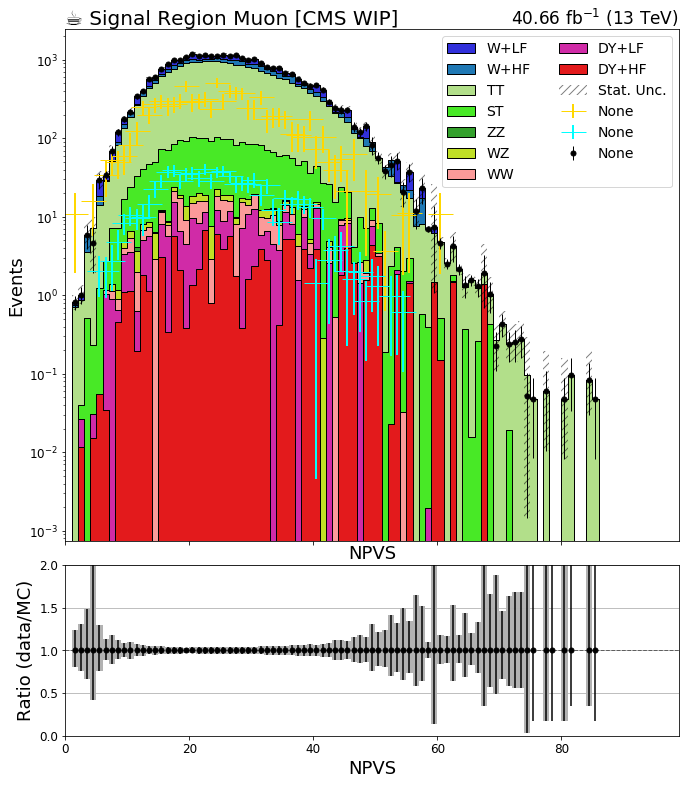

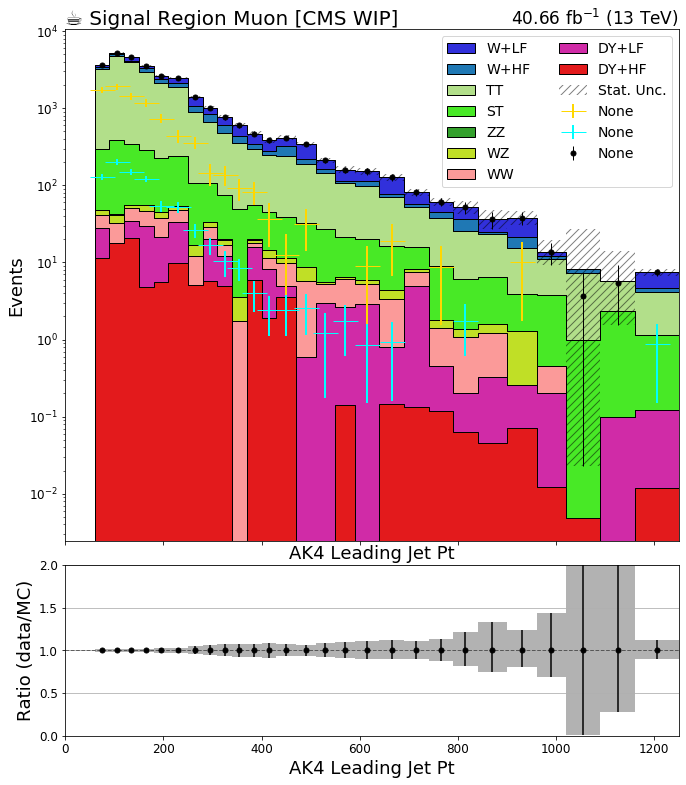

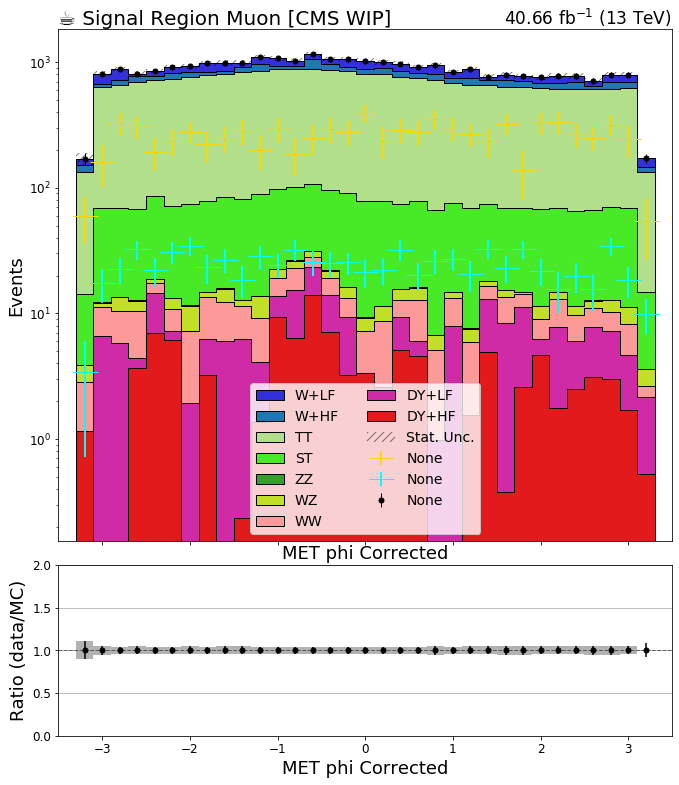

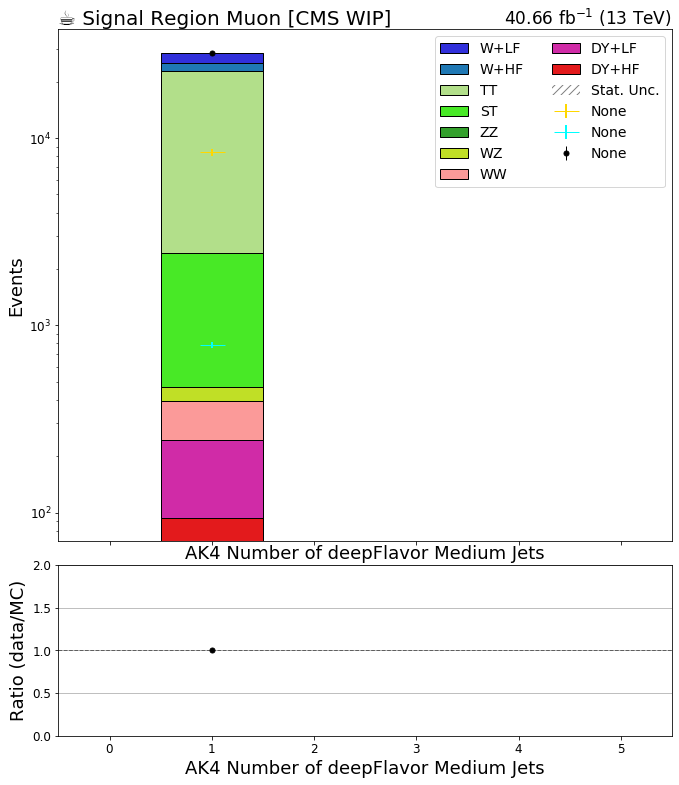

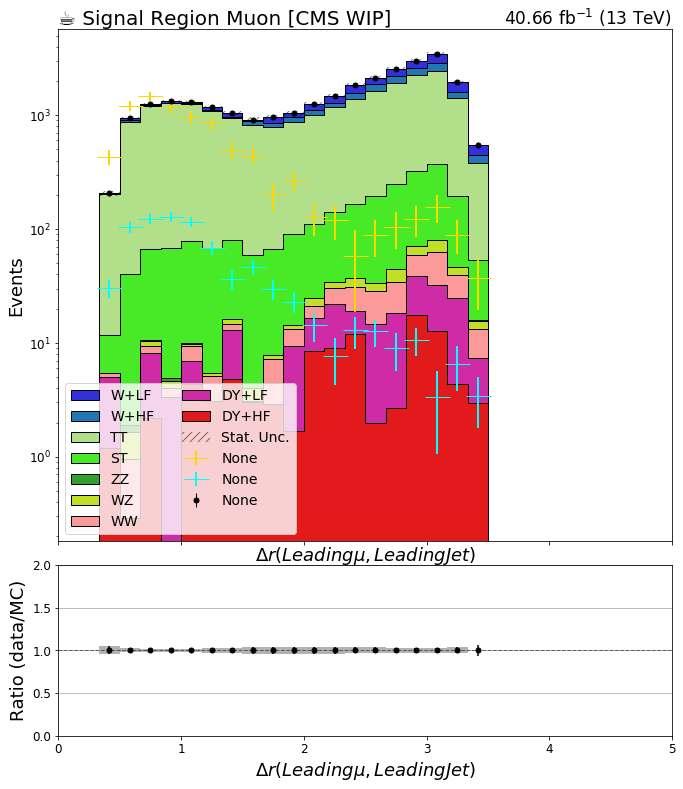

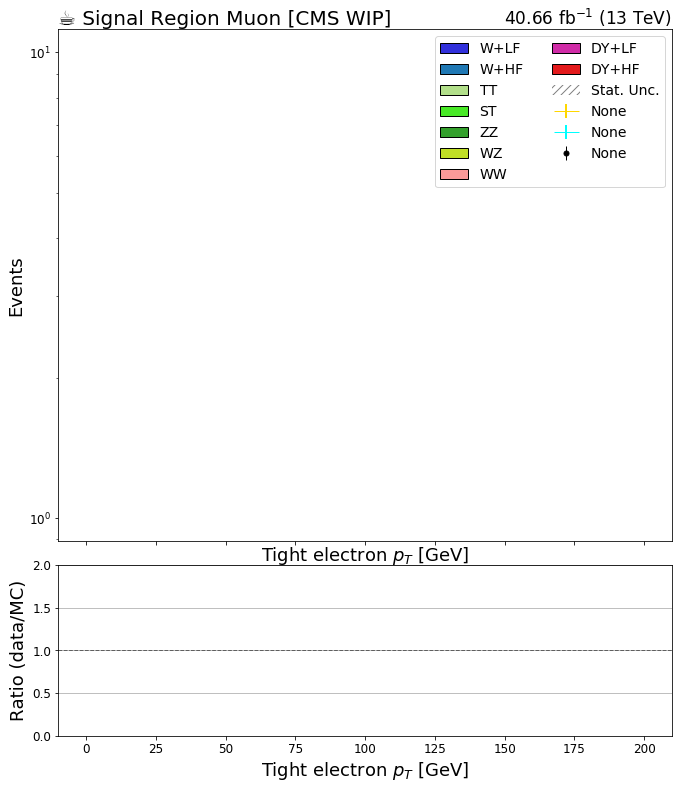

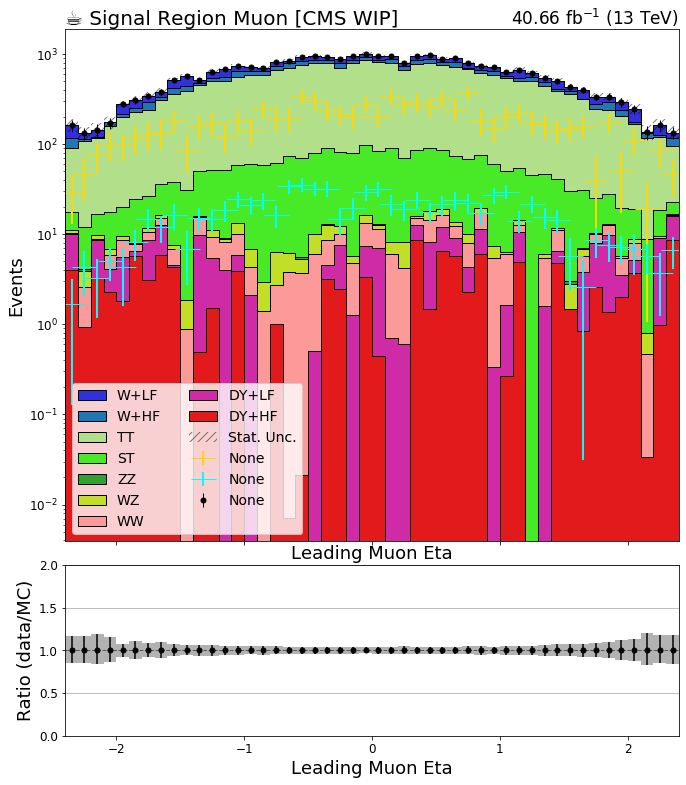

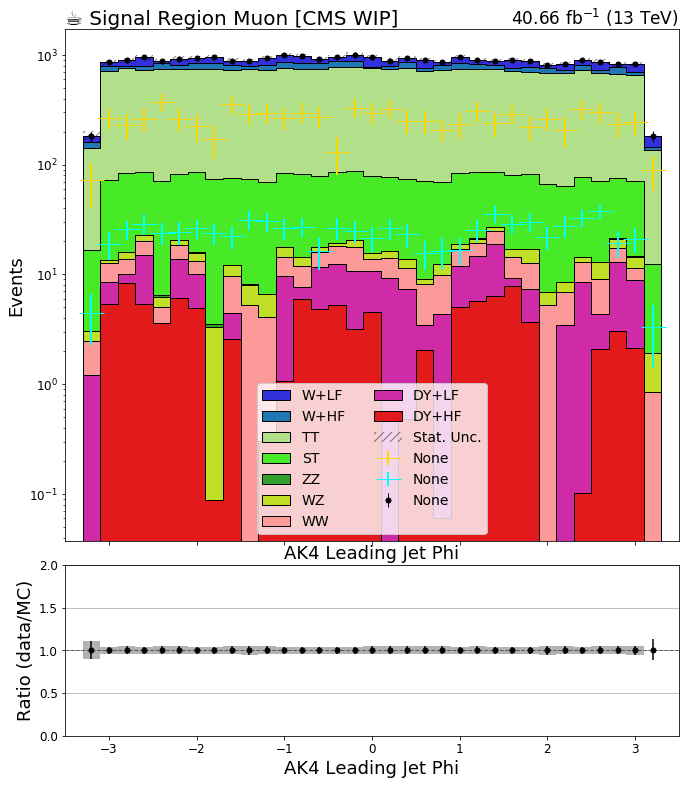

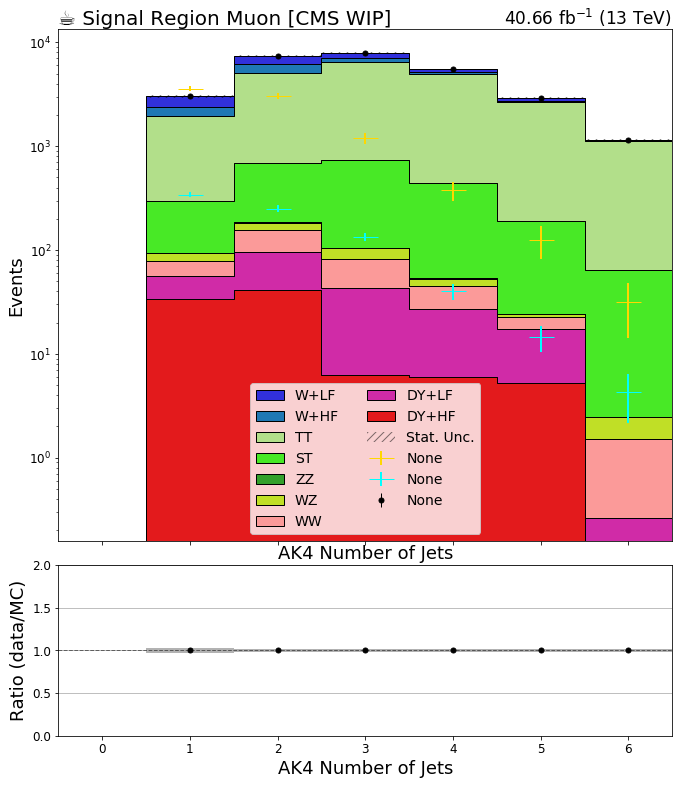

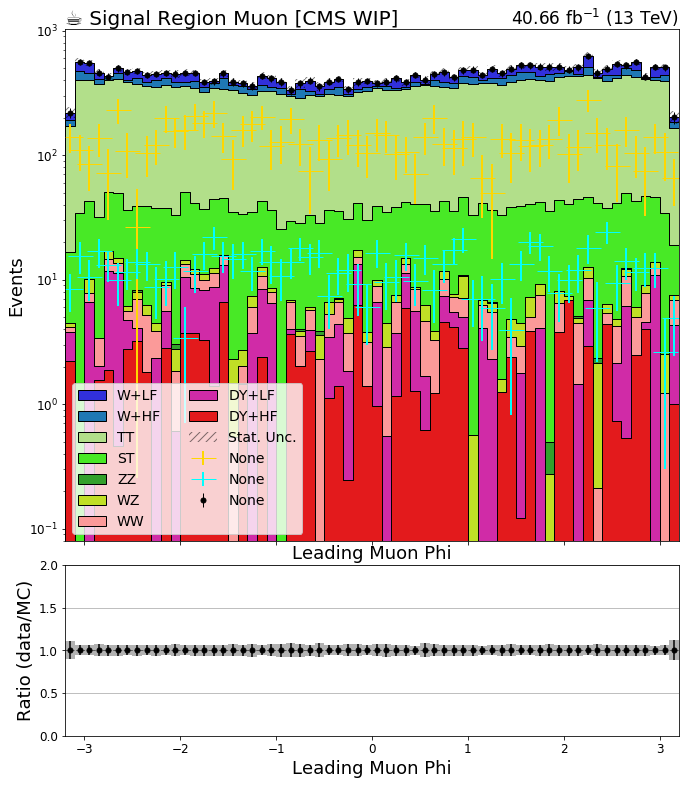

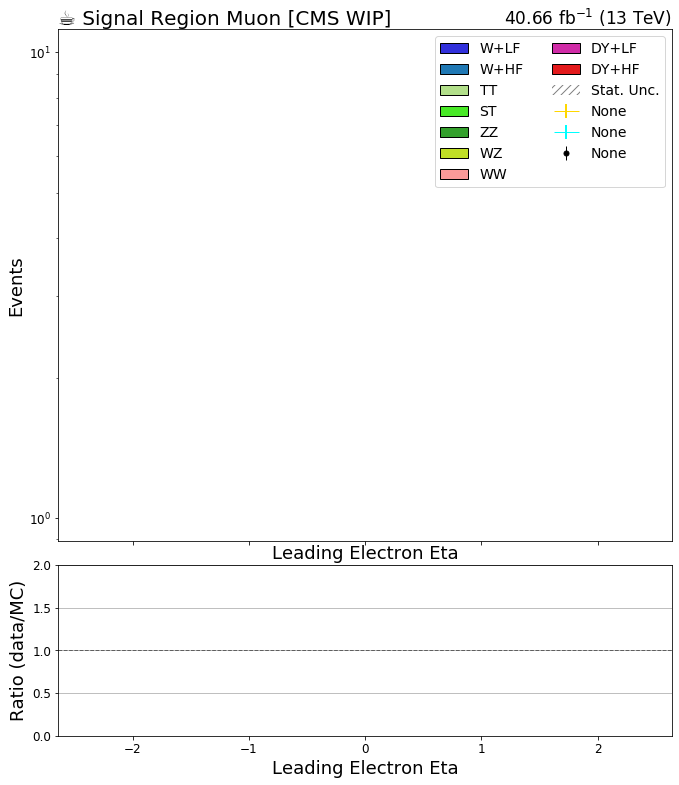

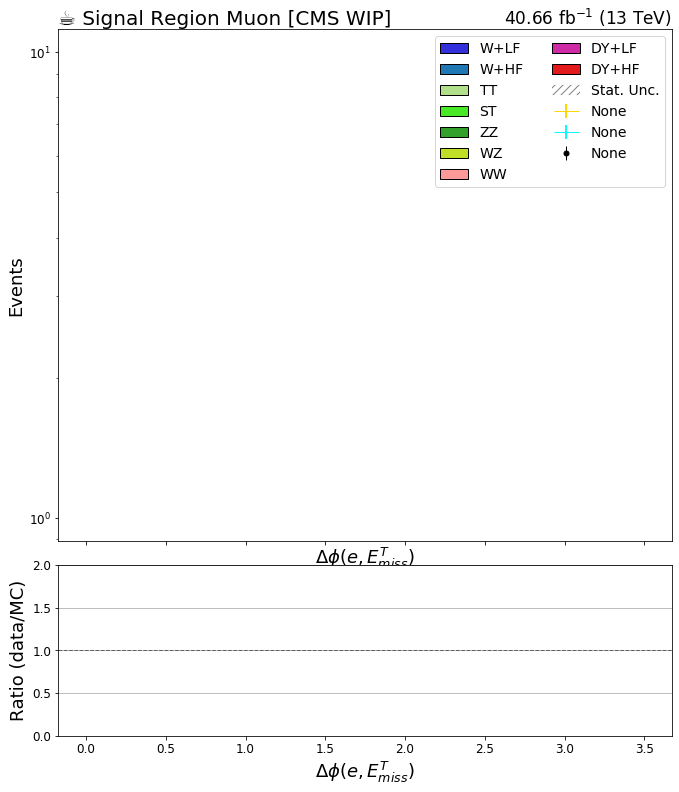

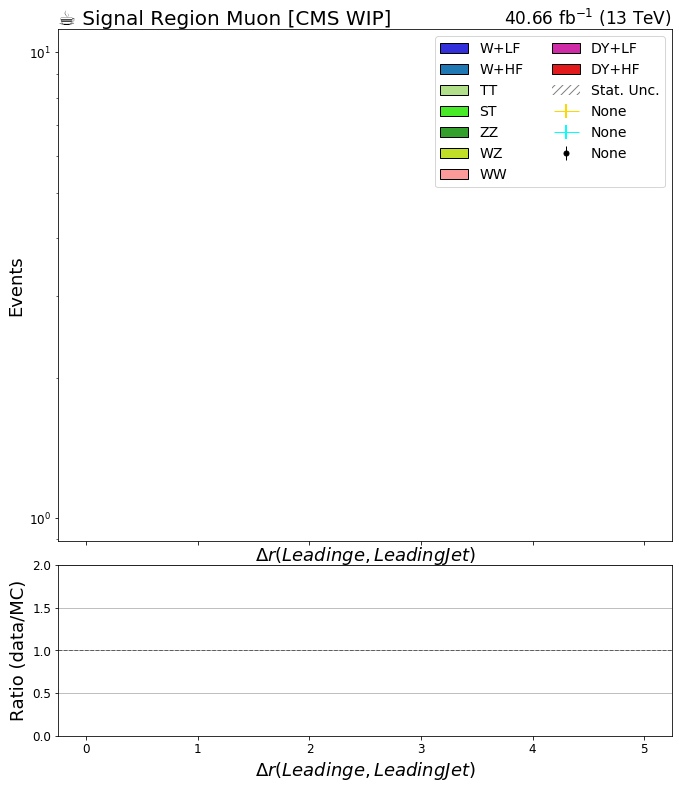

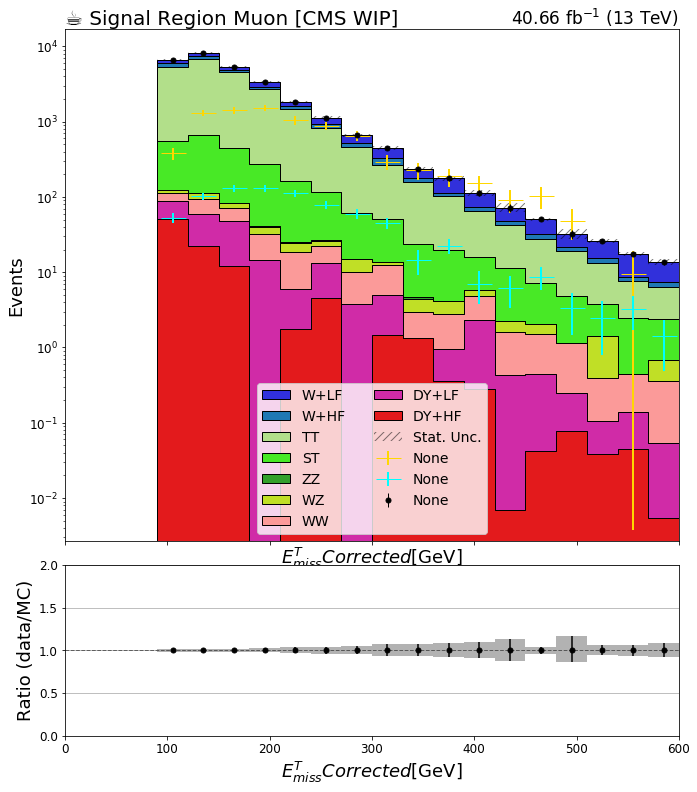

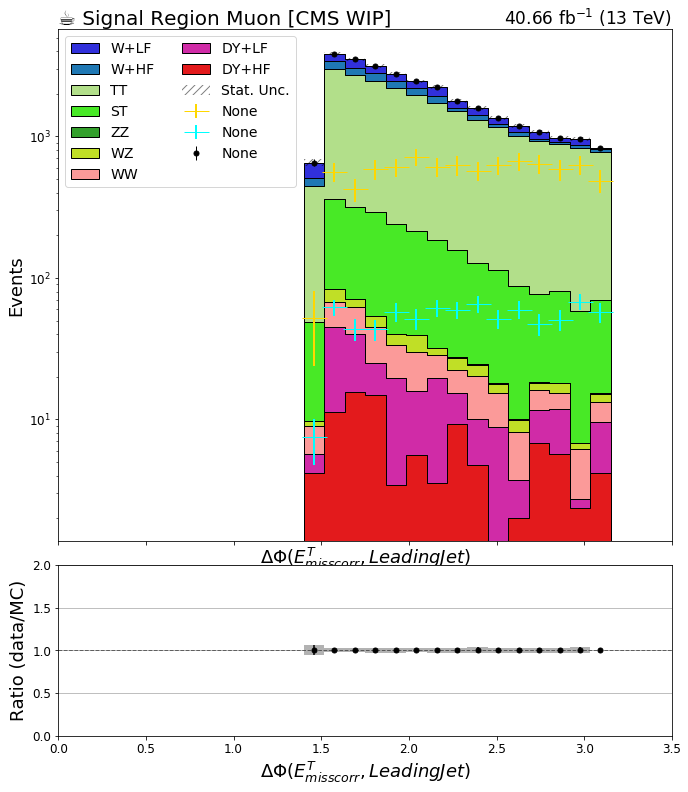

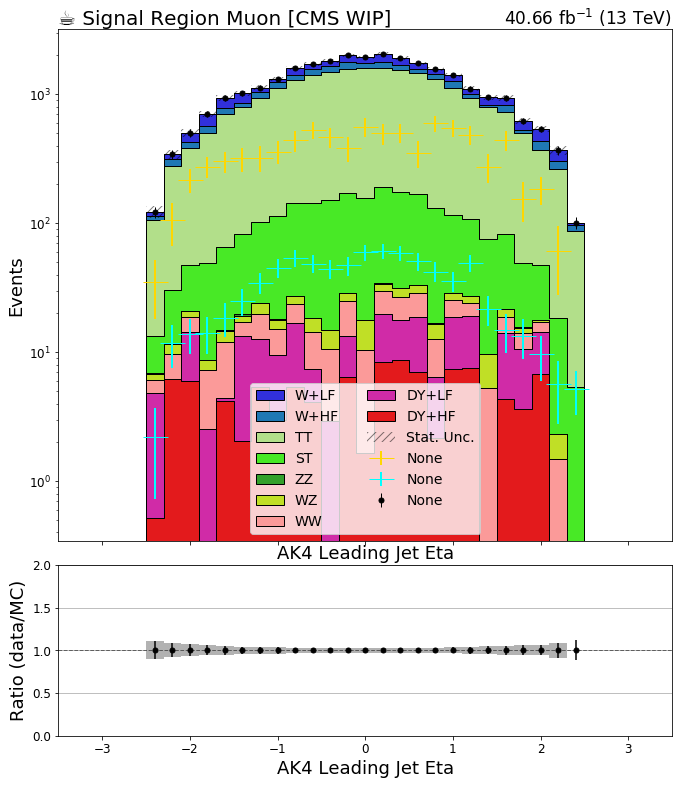

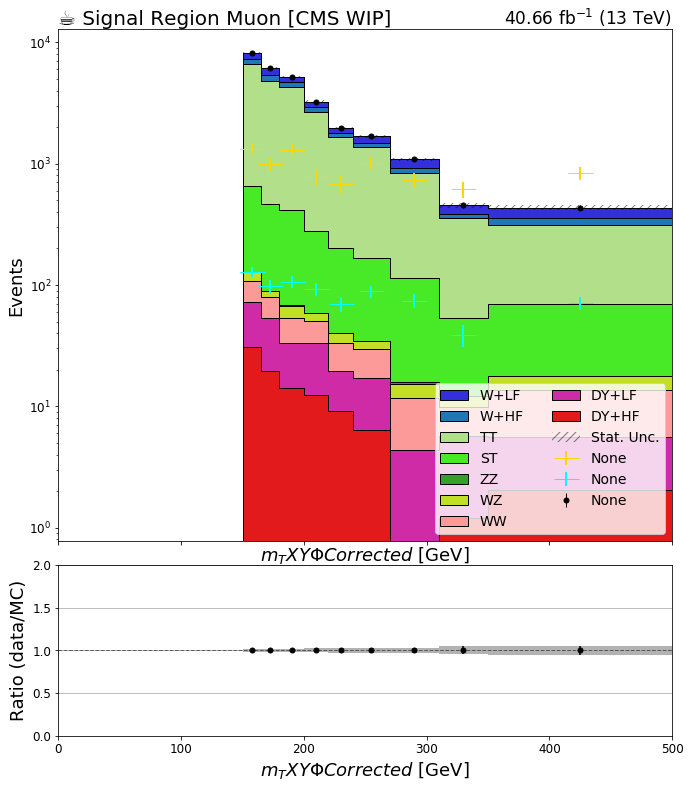

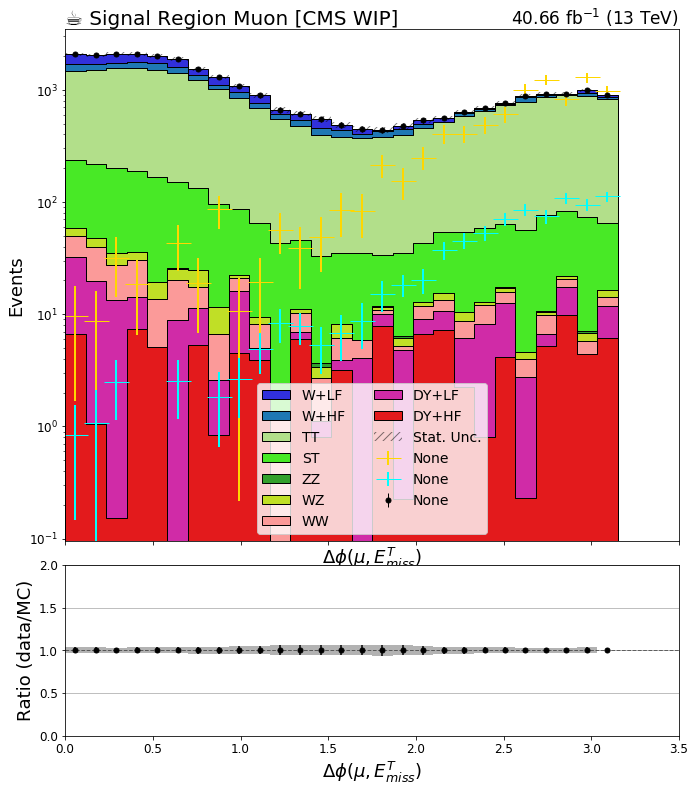

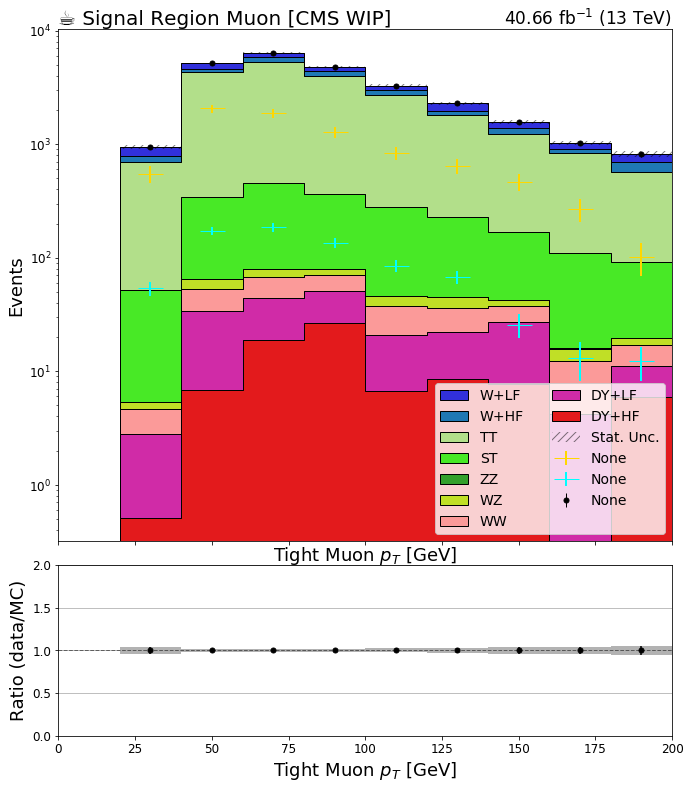

In [16]:
#http://colorbrewer2.org/#type=qualitative&scheme=Paired&n=6 : colors
from cycler import cycler
year = '2017'
region = 'srm'
sys = 'nominal'



if not os.path.exists('../plots'):
    os.makedirs('../plots')
R = {}
R['sre'] = 'Signal Region Electron'
R['srm'] = 'Signal Region Muon'
R['wjetm'] = 'Single Muon W CR'
R['ttbarm'] = 'Single Muon Top CR'
R['wjete'] = 'Single Electron W CR'
R['ttbare'] = 'Single Electron Top CR'
# R['zecr'] = 'Double Electron Z CR'
# R['zmcr'] = 'Double Muon Z CR'
# R['gcr'] = 'Single Photon CR'

for key in bkg_hists.keys():
    if key=='sumw': continue
    if 'template'  in key: continue
    if key=='cutflow': continue
    if key=='W_gen_pT':continue
    if key=='Z_gen_pT': continue
#     if 'mT_corrected' not in key:continue
    #if key!='fjmass': continue
#     print(key)
    for j in bkg_hists[key].identifiers('region'):
        if not (str(j) == region): continue
        plt.rcParams.update({'figure.max_open_warning': 0,'font.size': 14, 'axes.titlesize': 18, 'axes.labelsize': 18, 'xtick.labelsize': 12, 'ytick.labelsize': 12})
        fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
        error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
        nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
        data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
        #colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
        colors = [ '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']
        test_err_opts1 = {'marker': '_', 'markersize': 25., 'color':'gold', 'elinewidth': 2 }#, 'elinewidth': 1, 'emarker': '_'}
        fill_opts_tesst = {'edgecolor': (0,0,0,0.3)}
        fig, (ax, rax) = plt.subplots(2, 1, figsize=(11,13), gridspec_kw={"height_ratios": (3, 1)}, sharex=True)
        fig.subplots_adjust(hspace=.07)
        ax.set_prop_cycle(cycler(color=colors))
        
        
        test_err_opts2 = {'marker': '_', 'markersize': 25., 'color':'cyan', 'elinewidth': 2 }#, 'elinewidth': 1, 'emarker': '_'}

#         bins = bkg_hists[key].integrate('region', cr).integrate("systematic",sys).axis("mT_corrected").edges()[()]
        mphi200_Mchi50 = signal_hists[key].integrate('region',j).integrate('systematic', 'nominal').integrate('process','Mphi-200_Mchi-50')
        plot.plot1d(mphi200_Mchi50,          
#                 overlay="process",
#                     label='pseudo',
                    stack=False,
                    ax=ax, 
                    error_opts=test_err_opts1,
                    clear=False,            
           )
        mphi195_Mchi100 = signal_hists[key].integrate('region',j).integrate('systematic', 'nominal').integrate('process','Mphi-195_Mchi-100')
        plot.plot1d(mphi195_Mchi100,          
#                 overlay="process",
#                     label='pseudo',
                    stack=False,
                    ax=ax, 
                    error_opts=test_err_opts2,
                    clear=False,            
           )        
        
        plot.plot1d(bkg_hists[key].integrate("systematic", sys).integrate('region',j).integrate('process'),            
#                 overlay="process",
#                     label='pseudo',
                ax=ax,
                clear=False,
                error_opts=data_err_opts, 
                   )

        plot.plot1d(bkg_hists[key].integrate("systematic", sys).integrate('region',j),
                overlay="process",
                ax=ax,
                clear=False,
                stack=True,
                fill_opts=fill_opts,
                error_opts=error_opts
                   )

        plot.plotratio(bkg_hists[key].integrate("systematic", sys).integrate('region',j).integrate('process'), 
                   bkg_hists[key].integrate("systematic", sys).integrate('region',j).sum('process'),
                   ax=rax,
                   #overflow='over',
                   error_opts=data_err_opts,
                   denom_fill_opts={},
                   guide_opts={},
                   unc='num'
                   )
        
        rax.set_ylabel('Ratio (data/MC)')
        rax.set_ylim(0.0,2.0)
        rax.grid(axis='y')
        
        ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
        args = {'linestyle':'--', 'linewidth': 5}
        ax.autoscale(axis='x', tight=True)
        ax.set_yscale('log')
#         if(key=='mT_corrected'): plt.set_xlim(150, None)
        ax.set_ylim(.1, None)
        ax.autoscale()
        leg = ax.legend(ncol=2, loc='best')



        coffee = plt.text(0., 1., u"☕ "+R[str(j).split('_')[0]]+ " [CMS WIP]", fontsize=20, horizontalalignment='left', verticalalignment='bottom', transform=ax.transAxes)
        lumi = plt.text(1., 1., r"40.66 fb$^{-1}$ (13 TeV)", fontsize=17, horizontalalignment='right', verticalalignment='bottom', transform=ax.transAxes)
        os.system('mkdir -p ../plots/leptonic'+year+'/'+str(j)+'/')
        plot_path = os.path.abspath('../plots/leptonic'+year+'/'+str(j)+'/') 
        plot_name = 'stack_'+key+'.png'
        fig.savefig(os.path.join(plot_path, plot_name))